# Actividad 6. Evaluación y validación de modelos de Machine Learning

## Predicción de contratación de depósitos a plazo

**Universidad:** Tecmilenio  
**Materia:** Gestión de Proyectos de Inteligencia Artificial  
**Alumno:** Rogelio Aco González  
**Docente:** Luis Ariel Vázquez Piña  

### Antecedentes

Esta actividad da continuidad al proyecto desarrollado en la Actividad 5, en el cual se realizó la preparación de datos, entrenamiento y comparación de modelos de regresión logística y Random Forest para predecir la contratación de depósitos a plazo.

Se recuperarán los modelos, datos y evidencias generados anteriormente, con la finalidad de ampliar el análisis mediante el ajuste de umbrales de decisión, comparación con modelos de referencia, validación cruzada, pruebas estadísticas y simulación de estrategias comerciales A/B.

### Objetivo general

Evaluar y validar los modelos de Machine Learning mediante métricas y pruebas estadísticas, justificando su selección en función de su desempeño predictivo y su impacto potencial en el negocio bancario.

### Metodología de trabajo

1. Preparación y recuperación del proyecto anterior.
2. Reproducción de resultados históricos.
3. Evaluación de modelos de referencia (baseline).
4. Validación cruzada.
5. Optimización de umbrales de decisión.
6. Evaluación comparativa de modelos.
7. Análisis de significancia estadística.
8. Simulación de pruebas A/B.
9. Evaluación del impacto en el negocio.
10. Registro de experimentos en MLflow.
11. Generación de visualizaciones y tablero de resultados.
12. Integración de evidencias y documentación final.

In [1]:
from google.colab import files
from pathlib import Path
import zipfile

# Cargar el archivo ZIP de la Actividad 5
print("Selecciona el ZIP de resultados de la Actividad 5")

uploaded = files.upload()

archivo_zip = next(iter(uploaded))

print("\nArchivo recibido:", archivo_zip)

# Crear carpeta independiente de trabajo
ruta_base = Path("/content/Actividad6")
ruta_base.mkdir(parents=True, exist_ok=True)

ruta_origen = ruta_base / "proyecto_anterior"
ruta_origen.mkdir(exist_ok=True)

# Extraer el proyecto anterior
with zipfile.ZipFile(archivo_zip, "r") as zip_ref:
    zip_ref.extractall(ruta_origen)

print("\nProyecto recuperado correctamente")
print("Ubicación:", ruta_origen)

Selecciona el ZIP de resultados de la Actividad 5


Saving Actividad5_Banca_resultados.zip to Actividad5_Banca_resultados.zip

Archivo recibido: Actividad5_Banca_resultados.zip

Proyecto recuperado correctamente
Ubicación: /content/Actividad6/proyecto_anterior


In [2]:
# Crear estructura de la Actividad 6

carpetas = [
    "fuentes",
    "datos",
    "modelos",
    "resultados",
    "graficas",
    "evidencias_mlflow",
    "dashboard",
    "documentacion"
]

for carpeta in carpetas:
    ruta = ruta_base / carpeta
    ruta.mkdir(parents=True, exist_ok=True)
    print("Carpeta preparada:", ruta)

print("\nEstructura creada correctamente")

Carpeta preparada: /content/Actividad6/fuentes
Carpeta preparada: /content/Actividad6/datos
Carpeta preparada: /content/Actividad6/modelos
Carpeta preparada: /content/Actividad6/resultados
Carpeta preparada: /content/Actividad6/graficas
Carpeta preparada: /content/Actividad6/evidencias_mlflow
Carpeta preparada: /content/Actividad6/dashboard
Carpeta preparada: /content/Actividad6/documentacion

Estructura creada correctamente


In [3]:
# Identificar los archivos necesarios

archivos_requeridos = [
    "bank-full.csv",
    "bank_marketing_limpio.csv",
    "datos_prep.py",
    "train.py",
    "comparacion_modelos.csv",
    "cv_folds.json",
    "mlflow.db",
    "model.pkl",
    "requirements.txt"
]

print("=" * 70)
print("INVENTARIO DEL PROYECTO ANTERIOR")
print("=" * 70)

for nombre in archivos_requeridos:

    encontrados = list(ruta_origen.rglob(nombre))

    if encontrados:
        print(f"\n[OK] {nombre}")

        for archivo in encontrados:
            tamano = archivo.stat().st_size / 1024

            print("  Ruta:", archivo.relative_to(ruta_origen))
            print(f"  Tamaño: {tamano:,.2f} KB")

    else:
        print(f"\n[NO ENCONTRADO] {nombre}")

print("\nInventario finalizado")

INVENTARIO DEL PROYECTO ANTERIOR

[OK] bank-full.csv
  Ruta: Actividad5/datos/datos_ini/bank-full.csv
  Tamaño: 4,502.29 KB

[OK] bank_marketing_limpio.csv
  Ruta: Actividad5/datos/datos_limp/bank_marketing_limpio.csv
  Tamaño: 3,401.91 KB

[OK] datos_prep.py
  Ruta: Actividad5/fuentes/datos_prep.py
  Tamaño: 2.05 KB

[OK] train.py
  Ruta: Actividad5/fuentes/train.py
  Tamaño: 5.23 KB

[OK] comparacion_modelos.csv
  Ruta: Actividad5/resultados/comparacion_modelos.csv
  Tamaño: 0.52 KB

[OK] cv_folds.json
  Ruta: Actividad5/resultados/cv_folds.json
  Tamaño: 0.29 KB

[OK] mlflow.db
  Ruta: Actividad5/evidencias/mlflow.db
  Tamaño: 1,008.00 KB

[OK] model.pkl
  Ruta: Actividad5/evidencias/mlruns/1/models/m-641c31757ef743e1a6901a56237e9d0f/artifacts/model.pkl
  Tamaño: 48,263.98 KB
  Ruta: Actividad5/evidencias/mlruns/1/models/m-9df00be220034412927786fc3f19aa8c/artifacts/model.pkl
  Tamaño: 4.24 KB

[OK] requirements.txt
  Ruta: Actividad5/fuentes/requirements.txt
  Tamaño: 0.08 KB
  Ruta

In [4]:
import sys
from importlib.metadata import version, PackageNotFoundError

print("=" * 70)
print("VERSIONES DEL ENTORNO ACTUAL")
print("=" * 70)

print("Python:", sys.version)

bibliotecas = [
    "scikit-learn",
    "numpy",
    "pandas",
    "scipy",
    "mlflow",
    "cloudpickle",
    "matplotlib",
    "seaborn",
    "plotly"
]

for biblioteca in bibliotecas:

    try:
        print(f"{biblioteca:20} {version(biblioteca)}")

    except PackageNotFoundError:
        print(f"{biblioteca:20} NO INSTALADA")

print("\n" + "=" * 70)
print("DEPENDENCIAS ORIGINALES DE LOS MODELOS")
print("=" * 70)

for archivo in ruta_origen.rglob("requirements.txt"):

    print("\nArchivo:", archivo.relative_to(ruta_origen))
    print("-" * 60)
    print(archivo.read_text(encoding="utf-8"))

VERSIONES DEL ENTORNO ACTUAL
Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
scikit-learn         1.6.1
numpy                2.4.6
pandas               2.2.3
scipy                1.16.3
mlflow               NO INSTALADA
cloudpickle          3.1.2
matplotlib           3.10.0
seaborn              0.13.2
plotly               5.24.1

DEPENDENCIAS ORIGINALES DE LOS MODELOS

Archivo: Actividad5/fuentes/requirements.txt
------------------------------------------------------------
pandas>=2.0,<3
numpy>=1.24,<3
scikit-learn>=1.3,<2
matplotlib>=3.7,<4
mlflow>=2.15,<4


Archivo: Actividad5/evidencias/mlruns/1/models/m-641c31757ef743e1a6901a56237e9d0f/artifacts/requirements.txt
------------------------------------------------------------
mlflow==3.18.0
cloudpickle==3.1.2
lz4==4.4.5
numpy==2.4.6
pandas==2.2.3
psutil==5.9.5
scikit-learn==1.6.1
scipy==1.16.3

Archivo: Actividad5/evidencias/mlruns/1/models/m-9df00be220034412927786fc3f19aa8c/artifacts/requirements.txt
-----------------------

## 02. Recuperación de modelos y reproducción de resultados históricos

En esta etapa recuperamos los modelos entrenados en la Actividad 5
y reconstruimos la partición original de los datos para verificar
la reproducibilidad de los resultados, sin realizar nuevos entrenamientos.

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Ubicación del proyecto original
ruta_act5 = ruta_origen / "Actividad5"

# Recuperar dataset depurado
ruta_dataset = (
    ruta_act5 / "datos" / "datos_limp" /
    "bank_marketing_limpio.csv"
)

df = pd.read_csv(ruta_dataset)

# Verificar integridad básica
assert df.shape == (45195, 16)
assert "duration" not in df.columns
assert set(df["y"].unique()) == {0, 1}

# Separar variables predictoras y objetivo
X = df.drop(columns=["y"])
y = df["y"]

# Reconstruir la partición original
SEED = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("=" * 65)
print("RECUPERACIÓN DEL DATASET")
print("=" * 65)

print("Registros totales:", len(df))
print("Variables predictoras:", X.shape[1])
print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

print("\nDistribución de clases original:")
print(y.value_counts().sort_index())

print("\nDistribución en entrenamiento:")
print(y_train.value_counts().sort_index())

print("\nDistribución en prueba:")
print(y_test.value_counts().sort_index())

print("\nVariables predictoras:")
print(X.columns.tolist())

print("\nDataset recuperado correctamente")

RECUPERACIÓN DEL DATASET
Registros totales: 45195
Variables predictoras: 15
Registros de entrenamiento: 36156
Registros de prueba: 9039

Distribución de clases original:
y
0    39906
1     5289
Name: count, dtype: int64

Distribución en entrenamiento:
y
0    31925
1     4231
Name: count, dtype: int64

Distribución en prueba:
y
0    7981
1    1058
Name: count, dtype: int64

Variables predictoras:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

Dataset recuperado correctamente


In [6]:
import cloudpickle

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

modelos = {}

print("=" * 65)
print("RECUPERACIÓN DE MODELOS ENTRENADOS")
print("=" * 65)

archivos_modelo = sorted(ruta_origen.rglob("model.pkl"))

for archivo in archivos_modelo:

    print("\nRecuperando:", archivo.name)

    # Cargar exclusivamente nuestros modelos de la Actividad 5
    with open(archivo, "rb") as f:
        modelo = cloudpickle.load(f)

    # Identificar el algoritmo dentro del pipeline
    algoritmo = modelo.named_steps["model"]

    if isinstance(algoritmo, LogisticRegression):
        nombre = "Regresion_logistica"

    elif isinstance(algoritmo, RandomForestClassifier):
        nombre = "Random_forest"

    else:
        raise ValueError("Algoritmo no reconocido")

    modelos[nombre] = modelo

    print("Modelo identificado:", nombre)
    print("Tipo:", type(algoritmo).__name__)
    print("Pipeline:", list(modelo.named_steps.keys()))
    print("Clases:", modelo.classes_)

    print("Hiperparámetros:")

    for parametro, valor in algoritmo.get_params().items():
        print(f"  {parametro}: {valor}")

assert len(modelos) == 2

print("\n" + "=" * 65)
print("MODELOS RECUPERADOS:", len(modelos))
print("=" * 65)

print(list(modelos.keys()))

RECUPERACIÓN DE MODELOS ENTRENADOS

Recuperando: model.pkl
Modelo identificado: Random_forest
Tipo: RandomForestClassifier
Pipeline: ['prep', 'model']
Clases: [0 1]
Hiperparámetros:
  bootstrap: True
  ccp_alpha: 0.0
  class_weight: None
  criterion: gini
  max_depth: 16
  max_features: sqrt
  max_leaf_nodes: None
  max_samples: None
  min_impurity_decrease: 0.0
  min_samples_leaf: 1
  min_samples_split: 2
  min_weight_fraction_leaf: 0.0
  monotonic_cst: None
  n_estimators: 200
  n_jobs: 1
  oob_score: False
  random_state: 42
  verbose: 0
  warm_start: False

Recuperando: model.pkl
Modelo identificado: Regresion_logistica
Tipo: LogisticRegression
Pipeline: ['prep', 'model']
Clases: [0 1]
Hiperparámetros:
  C: 10.0
  class_weight: balanced
  dual: False
  fit_intercept: True
  intercept_scaling: 1
  l1_ratio: None
  max_iter: 1500
  multi_class: deprecated
  n_jobs: None
  penalty: l2
  random_state: 42
  solver: lbfgs
  tol: 0.0001
  verbose: 0
  warm_start: False

MODELOS RECUPERADO

In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from IPython.display import display

resultados_originales = []

# Conservar las predicciones individuales
predicciones_prueba = pd.DataFrame({
    "id_registro": X_test.index,
    "y_real": y_test.to_numpy()
})

for nombre, modelo in modelos.items():

    # Predicción binaria original
    pred = modelo.predict(X_test)

    # Probabilidad de la clase positiva
    proba = modelo.predict_proba(X_test)[:, 1]

    # Obtener matriz de confusión
    vn, fp, fn, vp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()

    # Calcular métricas
    metricas = {
        "modelo": nombre,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "f1": f1_score(
            y_test, pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, proba),
        "especificidad": vn / (vn + fp),
        "VN": vn,
        "FP": fp,
        "FN": fn,
        "VP": vp
    }

    resultados_originales.append(metricas)

    # Guardar predicciones y probabilidades
    predicciones_prueba[f"{nombre}_pred"] = pred
    predicciones_prueba[f"{nombre}_proba"] = proba

# Construir tabla comparativa
df_metricas_originales = pd.DataFrame(
    resultados_originales
)

print("=" * 65)
print("RESULTADOS DE LOS MODELOS RECUPERADOS")
print("=" * 65)

display(df_metricas_originales.round(6))

print("\nPrimeras diez predicciones individuales:")

display(predicciones_prueba.head(10))

RESULTADOS DE LOS MODELOS RECUPERADOS


,modelo,accuracy,precision,recall,f1,roc_auc,especificidad,VN,FP,FN,VP
0,Random_forest,0.893904,0.652308,0.200378,0.306580,0.803305,0.985841,7868,113,846,212
1,Regresion_logistica,0.757827,0.270774,0.631380,0.379007,0.773500,0.774590,6182,1799,390,668



Primeras diez predicciones individuales:


,id_registro,y_real,Random_forest_pred,Random_forest_proba,Regresion_logistica_pred,Regresion_logistica_proba
0,5834,0,0,0.040655,0,0.195699
1,22877,0,0,0.086198,0,0.428529
2,38095,0,0,0.042750,0,0.402582
3,3805,0,0,0.150900,0,0.445956
4,32636,0,0,0.056891,0,0.452465
5,5084,0,0,0.028678,0,0.247020
6,4136,0,0,0.043387,0,0.233211
7,38210,0,0,0.090778,1,0.514996
8,44134,1,1,0.728842,1,0.941469
9,30430,0,0,0.115231,0,0.489657


In [8]:
# Recuperar resultados históricos
ruta_historico = (
    ruta_act5 / "resultados" /
    "comparacion_modelos.csv"
)

df_historico = pd.read_csv(ruta_historico)

metricas_comparar = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

historico = df_historico.set_index("modelo")

recuperado = df_metricas_originales.set_index("modelo")

comparacion = []

for nombre in recuperado.index:

    for metrica in metricas_comparar:

        valor_original = historico.loc[nombre, metrica]
        valor_recuperado = recuperado.loc[nombre, metrica]

        diferencia = abs(
            valor_original - valor_recuperado
        )

        coincide = np.isclose(
            valor_original,
            valor_recuperado,
            atol=1e-8,
            rtol=0
        )

        comparacion.append({
            "modelo": nombre,
            "metrica": metrica,
            "actividad_5": valor_original,
            "actividad_6": valor_recuperado,
            "diferencia": diferencia,
            "coincide": coincide
        })

df_reproducibilidad = pd.DataFrame(comparacion)

print("=" * 65)
print("VALIDACIÓN DE REPRODUCIBILIDAD")
print("=" * 65)

display(df_reproducibilidad.round(10))

total = len(df_reproducibilidad)
correctas = df_reproducibilidad["coincide"].sum()

print(f"\nMétricas coincidentes: {correctas} de {total}")

if correctas == total:
    print("\n[OK] Reproducción exitosa de la Actividad 5")
else:
    print("\n[ATENCIÓN] Existen diferencias por investigar")

VALIDACIÓN DE REPRODUCIBILIDAD


,modelo,metrica,actividad_5,actividad_6,diferencia,coincide
0,Random_forest,accuracy,0.893904,0.893904,0.0,True
1,Random_forest,precision,0.652308,0.652308,0.0,True
2,Random_forest,recall,0.200378,0.200378,0.0,True
3,Random_forest,f1,0.306580,0.306580,0.0,True
4,Random_forest,roc_auc,0.803305,0.803305,0.0,True
5,Regresion_logistica,accuracy,0.757827,0.757827,0.0,True
6,Regresion_logistica,precision,0.270774,0.270774,0.0,True
7,Regresion_logistica,recall,0.631380,0.631380,0.0,True
8,Regresion_logistica,f1,0.379007,0.379007,0.0,True
9,Regresion_logistica,roc_auc,0.773500,0.773500,0.0,True



Métricas coincidentes: 10 de 10

[OK] Reproducción exitosa de la Actividad 5


In [9]:
# Guardar métricas de los modelos recuperados

df_metricas_originales.to_csv(
    ruta_base / "resultados" / "metricas_originales.csv",
    index=False
)

# Guardar predicciones individuales y probabilidades

predicciones_prueba.to_csv(
    ruta_base / "resultados" / "predicciones_prueba.csv",
    index=False
)

# Guardar evidencia de reproducibilidad

df_reproducibilidad.to_csv(
    ruta_base / "resultados" / "reproducibilidad.csv",
    index=False
)

print("=" * 65)
print("EVIDENCIAS GENERADAS")
print("=" * 65)

for archivo in sorted(
    (ruta_base / "resultados").glob("*.csv")
):
    print(
        archivo.name,
        f"- {archivo.stat().st_size / 1024:,.2f} KB"
    )

print("\nEvidencias almacenadas correctamente")

EVIDENCIAS GENERADAS
metricas_originales.csv - 0.36 KB
predicciones_prueba.csv - 450.70 KB
reproducibilidad.csv - 0.75 KB

Evidencias almacenadas correctamente


# Primer corte

Hasta aquí ya recuperamos los dos modelos y recuperamos 10 métricas, validando que las 10 coinciden

Como primer paso de esta actividad decidí recuperar los modelos entrenados en la Actividad 5, en lugar de realizar nuevamente todo el proceso de entrenamiento. Esto permitió comprobar la utilidad de conservar los modelos serializados, los parámetros de configuración y las evidencias de ejecución.

Se reconstruyó la partición original de los datos, utilizando la misma semilla aleatoria y distribución estratificada. Posteriormente se ejecutaron ambos modelos sobre los 9,039 registros del conjunto de prueba.

Se comprobó que las diez métricas evaluadas coincidieron con los resultados originales, lo que demuestra la reproducibilidad de las predicciones bajo las mismas condiciones experimentales.

Considero que este ejercicio resulta particularmente importante en un entorno empresarial, donde la capacidad de recuperar una versión anterior de un modelo y reproducir sus resultados constituye un elemento fundamental de trazabilidad, mantenimiento y gobernanza.

## 03. Definición del objetivo SMART y evaluación de modelos de referencia

### Objetivo SMART

Evaluar y validar, durante una semana de experimentación, los modelos de regresión logística y Random Forest para la predicción de contratación de depósitos a plazo, buscando alcanzar un F1-score de al menos 0.40, un recall mínimo del 60 % y una precisión mínima del 30 %, mediante validación cruzada estratificada, ajuste de umbrales de decisión y comparación con modelos de referencia.

El propósito es mejorar la identificación de oportunidades comerciales y la eficiencia en la selección de clientes para campañas bancarias, documentando la estabilidad, las limitaciones y el impacto potencial de los modelos evaluados.

### Criterios de selección

El F1-score será la métrica principal de selección, considerando las restricciones mínimas de recall y precision.

Los umbrales se seleccionarán utilizando predicciones de validación, evitando optimizarlos sobre el conjunto de prueba.

Los resultados históricos se conservarán como referencia comparativa.

In [10]:
import json

# Criterios de éxito de la Actividad 6
OBJETIVOS = {
    "f1_minimo": 0.40,
    "recall_minimo": 0.60,
    "precision_minima": 0.30,
    "metrica_principal": "f1",
    "nivel_significancia": 0.05,
    "nivel_confianza": 0.95,
    "cv_folds": 5,
    "random_state": 42,
    "umbral_original": 0.50
}

# Guardar los criterios antes de experimentar
ruta_objetivos = (
    ruta_base / "documentacion" /
    "objetivos_evaluacion.json"
)

with open(ruta_objetivos, "w", encoding="utf-8") as f:
    json.dump(
        OBJETIVOS,
        f,
        indent=4,
        ensure_ascii=False
    )

print("=" * 65)
print("CRITERIOS DE EVALUACIÓN - ACTIVIDAD 6")
print("=" * 65)

for criterio, valor in OBJETIVOS.items():
    print(f"{criterio:25}: {valor}")

print("\nConfiguración guardada en:")
print(ruta_objetivos)

CRITERIOS DE EVALUACIÓN - ACTIVIDAD 6
f1_minimo                : 0.4
recall_minimo            : 0.6
precision_minima         : 0.3
metrica_principal        : f1
nivel_significancia      : 0.05
nivel_confianza          : 0.95
cv_folds                 : 5
random_state             : 42
umbral_original          : 0.5

Configuración guardada en:
/content/Actividad6/documentacion/objetivos_evaluacion.json


In [11]:
def evaluar_clasificacion(
    nombre,
    y_real,
    y_pred,
    y_proba=None
):
    """
    Calcula las métricas de clasificación
    y los indicadores comerciales.
    """

    vn, fp, fn, vp = confusion_matrix(
        y_real,
        y_pred,
        labels=[0, 1]
    ).ravel()

    total = vn + fp + fn + vp
    seleccionados = vp + fp

    resultado = {
        "modelo": nombre,

        "accuracy": accuracy_score(
            y_real, y_pred
        ),

        "precision": precision_score(
            y_real, y_pred,
            zero_division=0
        ),

        "recall": recall_score(
            y_real, y_pred,
            zero_division=0
        ),

        "f1": f1_score(
            y_real, y_pred,
            zero_division=0
        ),

        "roc_auc": (
            roc_auc_score(y_real, y_proba)
            if y_proba is not None
            else np.nan
        ),

        "especificidad": (
            vn / (vn + fp)
            if vn + fp > 0
            else 0
        ),

        "VN": vn,
        "FP": fp,
        "FN": fn,
        "VP": vp,

        "clientes_seleccionados": seleccionados,

        "tasa_seleccion": seleccionados / total,

        "contrataciones_identificadas": vp,

        "oportunidades_no_identificadas": fn,

        "contactos_sin_contratacion": fp
    }

    return resultado


print("Función de evaluación creada correctamente")

Función de evaluación creada correctamente


In [12]:
from sklearn.dummy import DummyClassifier

resultados_baseline = []

# ==========================================
# BASELINE 1: CLASE MAYORITARIA
# ==========================================

baseline_mayoritario = DummyClassifier(
    strategy="most_frequent",
    random_state=SEED
)

baseline_mayoritario.fit(X_train, y_train)

pred_mayoritario = baseline_mayoritario.predict(
    X_test
)

proba_mayoritario = (
    baseline_mayoritario.predict_proba(X_test)[:, 1]
)

resultados_baseline.append(
    evaluar_clasificacion(
        "Baseline_mayoritario",
        y_test,
        pred_mayoritario,
        proba_mayoritario
    )
)

# ==========================================
# BASELINE 2: SELECCIÓN ALEATORIA
# ==========================================

# Igual volumen de contactos que la
# regresión logística original

n_contactos = int(
    predicciones_prueba[
        "Regresion_logistica_pred"
    ].sum()
)

rng = np.random.default_rng(SEED)

scores_aleatorios = rng.random(len(y_test))

indices_seleccionados = np.argsort(
    scores_aleatorios
)[-n_contactos:]

pred_aleatorio = np.zeros(
    len(y_test),
    dtype=int
)

pred_aleatorio[indices_seleccionados] = 1

resultados_baseline.append(
    evaluar_clasificacion(
        "Baseline_aleatorio",
        y_test,
        pred_aleatorio,
        scores_aleatorios
    )
)

# ==========================================
# BASELINE 3: CONTACTAR A TODOS
# ==========================================

pred_todos = np.ones(
    len(y_test),
    dtype=int
)

proba_todos = np.ones(len(y_test))

resultados_baseline.append(
    evaluar_clasificacion(
        "Baseline_contactar_todos",
        y_test,
        pred_todos,
        proba_todos
    )
)

# Crear tabla de resultados
df_baselines = pd.DataFrame(
    resultados_baseline
)

print("=" * 65)
print("RESULTADOS DE LOS BASELINES")
print("=" * 65)

display(df_baselines.round(6))

# Guardar resultados
df_baselines.to_csv(
    ruta_base / "resultados" /
    "metricas_baseline.csv",
    index=False
)

# Guardar predicciones individuales
predicciones_baseline = pd.DataFrame({
    "id_registro": X_test.index,
    "y_real": y_test.to_numpy(),
    "mayoritario_pred": pred_mayoritario,
    "aleatorio_pred": pred_aleatorio,
    "aleatorio_score": scores_aleatorios,
    "contactar_todos_pred": pred_todos
})

predicciones_baseline.to_csv(
    ruta_base / "resultados" /
    "predicciones_baseline.csv",
    index=False
)

print("\nEvidencias de baselines guardadas")

RESULTADOS DE LOS BASELINES


,modelo,accuracy,precision,recall,f1,roc_auc,especificidad,VN,FP,FN,VP,clientes_seleccionados,tasa_seleccion,contrataciones_identificadas,oportunidades_no_identificadas,contactos_sin_contratacion
0,Baseline_mayoritario,0.882952,0.000000,0.000000,0.000000,0.500000,1.000000,7981,0,1058,0,0,0.000000,0,1058,0
1,Baseline_aleatorio,0.677066,0.122821,0.286389,0.171915,0.504189,0.728856,5817,2164,755,303,2467,0.272928,303,755,2164
2,Baseline_contactar_todos,0.117048,0.117048,1.000000,0.209567,0.500000,0.000000,0,7981,0,1058,9039,1.000000,1058,0,7981



Evidencias de baselines guardadas


In [13]:
resultados_modelos = []

for nombre, modelo in modelos.items():

    pred = predicciones_prueba[
        f"{nombre}_pred"
    ].to_numpy()

    proba = predicciones_prueba[
        f"{nombre}_proba"
    ].to_numpy()

    resultados_modelos.append(
        evaluar_clasificacion(
            nombre,
            y_test,
            pred,
            proba
        )
    )

df_modelos = pd.DataFrame(
    resultados_modelos
)

# Consolidar modelos y baselines
df_comparacion = pd.concat(
    [df_baselines, df_modelos],
    ignore_index=True
)

# Verificar criterios SMART
df_comparacion["cumple_f1"] = (
    df_comparacion["f1"] >=
    OBJETIVOS["f1_minimo"]
)

df_comparacion["cumple_recall"] = (
    df_comparacion["recall"] >=
    OBJETIVOS["recall_minimo"]
)

df_comparacion["cumple_precision"] = (
    df_comparacion["precision"] >=
    OBJETIVOS["precision_minima"]
)

df_comparacion["cumple_objetivos_metricos"] = (
    df_comparacion["cumple_f1"] &
    df_comparacion["cumple_recall"] &
    df_comparacion["cumple_precision"]
)

columnas_metricas = [
    "modelo",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "especificidad"
]

columnas_negocio = [
    "modelo",
    "clientes_seleccionados",
    "contrataciones_identificadas",
    "contactos_sin_contratacion",
    "oportunidades_no_identificadas"
]

columnas_objetivos = [
    "modelo",
    "cumple_f1",
    "cumple_recall",
    "cumple_precision",
    "cumple_objetivos_metricos"
]

print("=" * 65)
print("COMPARACIÓN DE MÉTRICAS")
print("=" * 65)

display(
    df_comparacion[columnas_metricas].round(4)
)

print("\nINDICADORES COMERCIALES")

display(
    df_comparacion[columnas_negocio]
)

print("\nCUMPLIMIENTO DE OBJETIVOS MÉTRICOS")

display(
    df_comparacion[columnas_objetivos]
)

# Guardar tabla consolidada
df_comparacion.to_csv(
    ruta_base / "resultados" /
    "comparacion_baseline_modelos.csv",
    index=False
)

print("\nComparación guardada correctamente")

COMPARACIÓN DE MÉTRICAS


,modelo,accuracy,precision,recall,f1,roc_auc,especificidad
0,Baseline_mayoritario,0.8830,0.0000,0.0000,0.0000,0.5000,1.0000
1,Baseline_aleatorio,0.6771,0.1228,0.2864,0.1719,0.5042,0.7289
2,Baseline_contactar_todos,0.1170,0.1170,1.0000,0.2096,0.5000,0.0000
3,Random_forest,0.8939,0.6523,0.2004,0.3066,0.8033,0.9858
4,Regresion_logistica,0.7578,0.2708,0.6314,0.3790,0.7735,0.7746



INDICADORES COMERCIALES


,modelo,clientes_seleccionados,contrataciones_identificadas,contactos_sin_contratacion,oportunidades_no_identificadas
0,Baseline_mayoritario,0,0,0,1058
1,Baseline_aleatorio,2467,303,2164,755
2,Baseline_contactar_todos,9039,1058,7981,0
3,Random_forest,325,212,113,846
4,Regresion_logistica,2467,668,1799,390



CUMPLIMIENTO DE OBJETIVOS MÉTRICOS


,modelo,cumple_f1,cumple_recall,cumple_precision,cumple_objetivos_metricos
0,Baseline_mayoritario,False,False,False,False
1,Baseline_aleatorio,False,False,False,False
2,Baseline_contactar_todos,False,True,False,False
3,Random_forest,False,False,True,False
4,Regresion_logistica,False,True,False,False



Comparación guardada correctamente


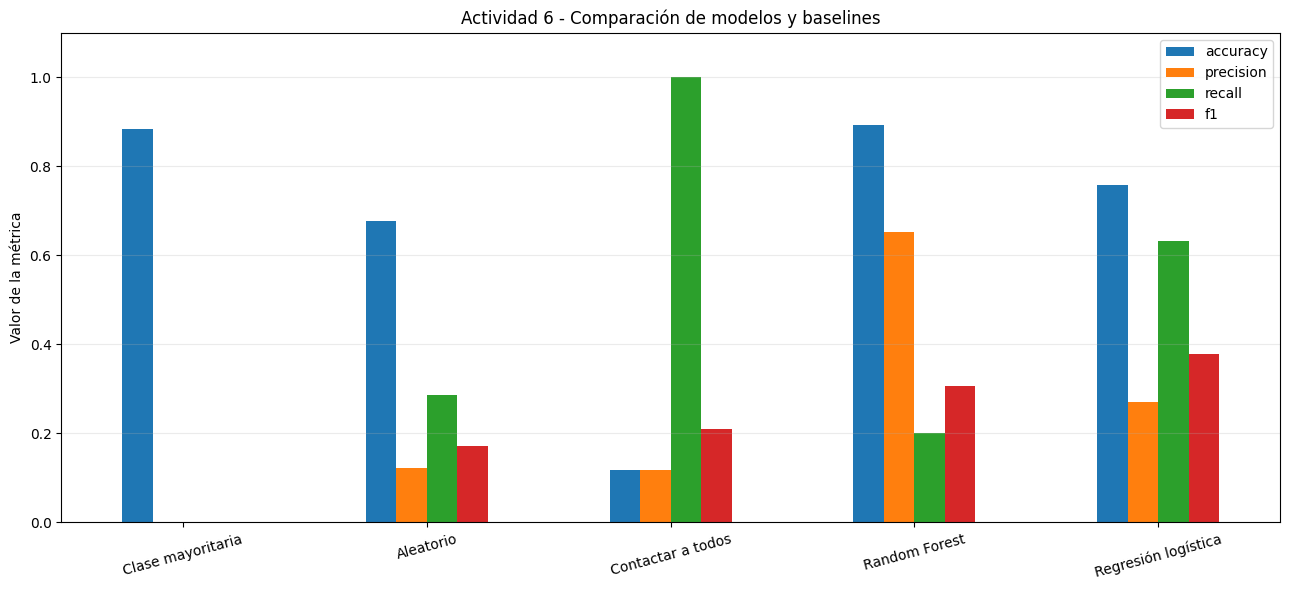

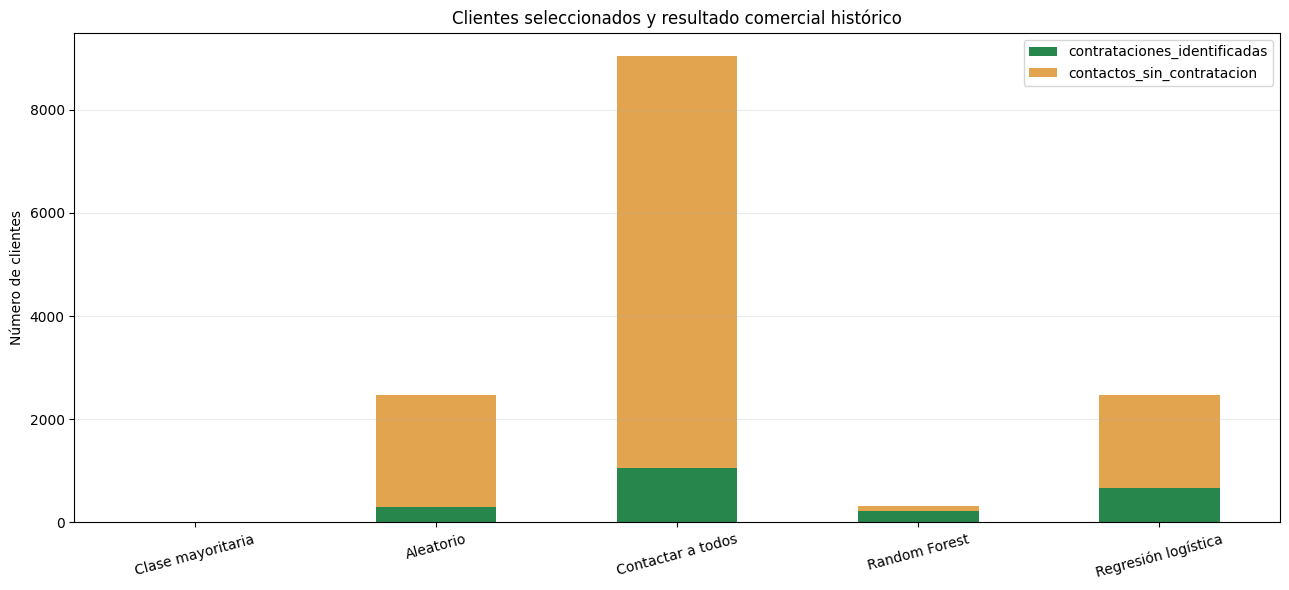

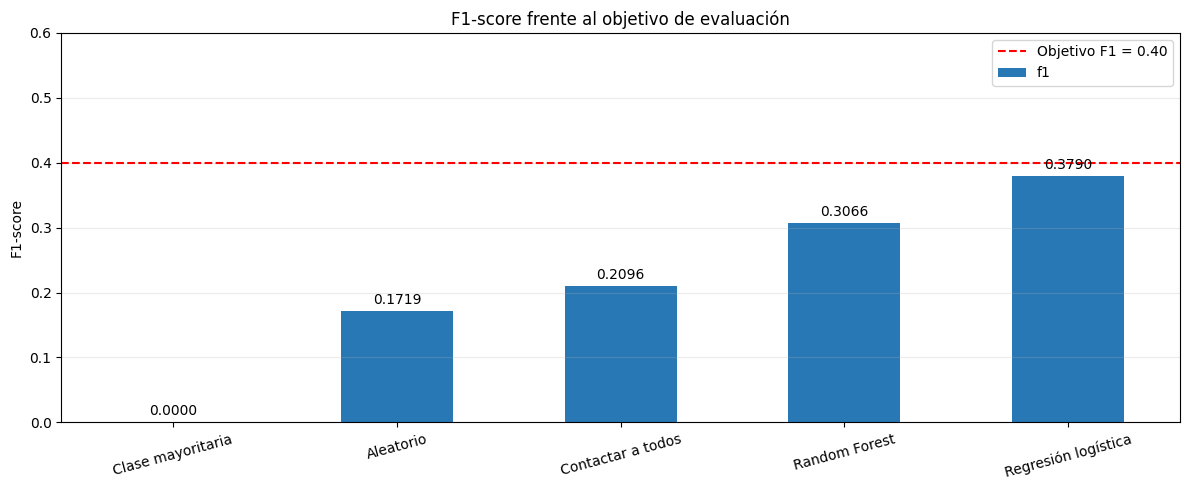

Tres gráficas generadas correctamente


In [14]:
import matplotlib.pyplot as plt

nombres_cortos = {
    "Baseline_mayoritario": "Clase mayoritaria",
    "Baseline_aleatorio": "Aleatorio",
    "Baseline_contactar_todos": "Contactar a todos",
    "Random_forest": "Random Forest",
    "Regresion_logistica": "Regresión logística"
}

df_visual = df_comparacion.copy()

df_visual["nombre"] = (
    df_visual["modelo"].map(nombres_cortos)
)

# ==========================================
# GRÁFICA 1: MÉTRICAS DE CLASIFICACIÓN
# ==========================================

ax = df_visual.set_index("nombre")[
    ["accuracy", "precision", "recall", "f1"]
].plot(
    kind="bar",
    figsize=(13, 6),
    rot=15
)

ax.set_title(
    "Actividad 6 - Comparación de modelos y baselines"
)

ax.set_ylabel("Valor de la métrica")
ax.set_xlabel("")
ax.set_ylim(0, 1.10)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "01_comparacion_metricas.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==========================================
# GRÁFICA 2: INDICADORES COMERCIALES
# ==========================================

ax = df_visual.set_index("nombre")[
    [
        "contrataciones_identificadas",
        "contactos_sin_contratacion"
    ]
].plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6),
    rot=15,
    color=["#27864B", "#E2A44F"]
)

ax.set_title(
    "Clientes seleccionados y resultado comercial histórico"
)

ax.set_ylabel("Número de clientes")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "02_indicadores_comerciales.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==========================================
# GRÁFICA 3: F1 VS OBJETIVO SMART
# ==========================================

ax = df_visual.set_index("nombre")[
    "f1"
].plot(
    kind="bar",
    figsize=(12, 5),
    rot=15,
    color="#2878B5"
)

ax.axhline(
    OBJETIVOS["f1_minimo"],
    color="red",
    linestyle="--",
    label="Objetivo F1 = 0.40"
)

ax.set_title(
    "F1-score frente al objetivo de evaluación"
)

ax.set_ylabel("F1-score")
ax.set_xlabel("")
ax.set_ylim(0, 0.60)
ax.legend()
ax.grid(axis="y", alpha=0.25)

for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt="%.4f",
        padding=3
    )

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "03_f1_objetivo_smart.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Tres gráficas generadas correctamente")

In [15]:
from datetime import datetime
from google.colab import files

fecha = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

ruta_respaldo = Path(
    f"/content/Actividad6_Avance_Etapa03_{fecha}.zip"
)

carpetas_respaldo = [
    "resultados",
    "graficas",
    "documentacion"
]

with zipfile.ZipFile(
    ruta_respaldo,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for carpeta in carpetas_respaldo:

        for archivo in (
            ruta_base / carpeta
        ).rglob("*"):

            if archivo.is_file():

                z.write(
                    archivo,
                    archivo.relative_to(ruta_base)
                )

print("Respaldo generado:", ruta_respaldo.name)

print(
    "Tamaño:",
    round(
        ruta_respaldo.stat().st_size / 1024,
        2
    ),
    "KB"
)

files.download(str(ruta_respaldo))

Respaldo generado: Actividad6_Avance_Etapa03_20261128_073212.zip
Tamaño: 565.68 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 04. Validación cruzada y generación de predicciones Out-of-Fold (OOF)

En esta etapa se recuperan los resultados de validación cruzada de la Actividad 5 y se amplía la experimentación mediante la generación de predicciones Out-of-Fold.

Se utilizarán cinco particiones estratificadas sobre los datos de entrenamiento, conservando los hiperparámetros seleccionados previamente para regresión logística y Random Forest.

Cada registro recibirá una predicción de un modelo que no utilizó dicho registro durante su ajuste.

Las probabilidades obtenidas permitirán seleccionar posteriormente los umbrales de decisión sin optimizarlos sobre el conjunto de prueba reservado.

Los modelos originales permanecerán sin modificaciones.

In [16]:
# Recuperar los resultados de la Actividad 5

ruta_cv_historica = (
    ruta_act5 / "resultados" / "cv_folds.json"
)

with open(
    ruta_cv_historica,
    "r",
    encoding="utf-8"
) as f:
    cv_historica = json.load(f)

print("=" * 65)
print("VALIDACIÓN CRUZADA HISTÓRICA")
print("=" * 65)

print(
    json.dumps(
        cv_historica,
        indent=4,
        ensure_ascii=False
    )
)

# Conservar evidencia histórica

with open(
    ruta_base / "resultados" /
    "cv_historica_act5.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        cv_historica,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\nResultados históricos recuperados")

VALIDACIÓN CRUZADA HISTÓRICA
{
    "Regresion_logistica": [
        0.36197825324447563,
        0.37795831861533025,
        0.3714689265536723,
        0.38139204545454547,
        0.3638320775026911
    ],
    "Random_forest": [
        0.3117117117117117,
        0.3217550274223035,
        0.3283052351375333,
        0.3303411131059246,
        0.2814814814814815
    ]
}

Resultados históricos recuperados


In [17]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

cv = StratifiedKFold(
    n_splits=OBJETIVOS["cv_folds"],
    shuffle=True,
    random_state=SEED
)

# Generar las mismas particiones para ambos modelos
particiones = list(
    cv.split(X_train, y_train)
)

resumen_particiones = []

# Identificar el fold de cada registro
fold_por_registro = np.zeros(
    len(y_train),
    dtype=int
)

for numero, (idx_train, idx_val) in enumerate(
    particiones,
    start=1
):

    y_fold_train = y_train.iloc[idx_train]
    y_fold_val = y_train.iloc[idx_val]

    fold_por_registro[idx_val] = numero

    resumen_particiones.append({
        "fold": numero,

        "registros_entrenamiento": len(idx_train),

        "registros_validacion": len(idx_val),

        "positivos_entrenamiento": int(
            y_fold_train.sum()
        ),

        "positivos_validacion": int(
            y_fold_val.sum()
        ),

        "prevalencia_entrenamiento": (
            y_fold_train.mean()
        ),

        "prevalencia_validacion": (
            y_fold_val.mean()
        )
    })

df_particiones = pd.DataFrame(
    resumen_particiones
)

assert np.all(fold_por_registro > 0)

print("=" * 65)
print("CONFIGURACIÓN DE LOS CINCO FOLDS")
print("=" * 65)

display(df_particiones.round(6))

print("\nTotal de registros de validación:")

print(
    df_particiones[
        "registros_validacion"
    ].sum()
)

df_particiones.to_csv(
    ruta_base / "resultados" /
    "configuracion_folds.csv",
    index=False
)

print("\nParticiones preparadas correctamente")

CONFIGURACIÓN DE LOS CINCO FOLDS


,fold,registros_entrenamiento,registros_validacion,positivos_entrenamiento,positivos_validacion,prevalencia_entrenamiento,prevalencia_validacion
0,1,28924,7232,3384,847,0.116996,0.117118
1,2,28925,7231,3385,846,0.117027,0.116996
2,3,28925,7231,3385,846,0.117027,0.116996
3,4,28925,7231,3385,846,0.117027,0.116996
4,5,28925,7231,3385,846,0.117027,0.116996



Total de registros de validación:
36156

Particiones preparadas correctamente


In [18]:
import time

resultados_cv = []

predicciones_oof = pd.DataFrame({
    "id_registro": X_train.index,
    "y_real": y_train.to_numpy(),
    "fold": fold_por_registro
})

inicio_total = time.perf_counter()

print("=" * 70)
print("GENERACIÓN DE PREDICCIONES OUT-OF-FOLD")
print("=" * 70)

for nombre, modelo_original in modelos.items():

    print("\nMODELO:", nombre)
    print("-" * 60)

    # Espacio para guardar probabilidades
    probabilidades_oof = np.full(
        len(y_train),
        np.nan
    )

    predicciones_binarias = np.full(
        len(y_train),
        -1,
        dtype=int
    )

    for numero, (idx_train, idx_val) in enumerate(
        particiones,
        start=1
    ):

        inicio = time.perf_counter()

        # Crear una copia no entrenada
        modelo_fold = clone(modelo_original)

        # Datos exclusivos de cada fold
        X_fold_train = X_train.iloc[idx_train]
        y_fold_train = y_train.iloc[idx_train]

        X_fold_val = X_train.iloc[idx_val]
        y_fold_val = y_train.iloc[idx_val]

        # Entrenar pipeline completo
        modelo_fold.fit(
            X_fold_train,
            y_fold_train
        )

        # Predicciones de validación
        proba = modelo_fold.predict_proba(
            X_fold_val
        )[:, 1]

        pred = modelo_fold.predict(
            X_fold_val
        )

        # Guardar resultados en su posición original
        probabilidades_oof[idx_val] = proba

        predicciones_binarias[idx_val] = pred

        # Evaluar datos de validación
        metricas = evaluar_clasificacion(
            nombre,
            y_fold_val,
            pred,
            proba
        )

        # Evaluar también datos de entrenamiento
        pred_train = modelo_fold.predict(
            X_fold_train
        )

        metricas["f1_entrenamiento"] = f1_score(
            y_fold_train,
            pred_train,
            zero_division=0
        )

        metricas["brecha_f1"] = (
            metricas["f1_entrenamiento"] -
            metricas["f1"]
        )

        metricas["fold"] = numero

        metricas["tiempo_segundos"] = (
            time.perf_counter() - inicio
        )

        resultados_cv.append(metricas)

        print(
            f"Fold {numero}/5 | "
            f"F1: {metricas['f1']:.4f} | "
            f"Recall: {metricas['recall']:.4f} | "
            f"AUC: {metricas['roc_auc']:.4f} | "
            f"Tiempo: "
            f"{metricas['tiempo_segundos']:.2f} s"
        )

        del modelo_fold

    # Verificar que todos los registros
    # recibieron una predicción

    assert not np.isnan(
        probabilidades_oof
    ).any()

    assert np.all(
        np.isin(predicciones_binarias, [0, 1])
    )

    predicciones_oof[
        f"{nombre}_proba"
    ] = probabilidades_oof

    predicciones_oof[
        f"{nombre}_pred"
    ] = predicciones_binarias

    print(
        "Predicciones OOF generadas:",
        len(probabilidades_oof)
    )

df_cv_nueva = pd.DataFrame(
    resultados_cv
)

# Guardar evidencias

df_cv_nueva.to_csv(
    ruta_base / "resultados" /
    "validacion_cruzada.csv",
    index=False
)

predicciones_oof.to_csv(
    ruta_base / "resultados" /
    "predicciones_oof.csv",
    index=False
)

tiempo_total = (
    time.perf_counter() - inicio_total
)

print("\n" + "=" * 70)

print(
    "ENTRENAMIENTOS REALIZADOS:",
    len(df_cv_nueva)
)

print(
    "REGISTROS CON PREDICCIONES OOF:",
    len(predicciones_oof)
)

print(
    f"TIEMPO TOTAL: {tiempo_total:.2f} segundos"
)

print("=" * 70)

display(
    df_cv_nueva[
        [
            "modelo",
            "fold",
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "f1_entrenamiento",
            "brecha_f1"
        ]
    ].round(6)
)

GENERACIÓN DE PREDICCIONES OUT-OF-FOLD

MODELO: Random_forest
------------------------------------------------------------
Fold 1/5 | F1: 0.3117 | Recall: 0.2043 | AUC: 0.7934 | Tiempo: 12.39 s
Fold 2/5 | F1: 0.3218 | Recall: 0.2080 | AUC: 0.7961 | Tiempo: 9.41 s
Fold 3/5 | F1: 0.3283 | Recall: 0.2187 | AUC: 0.7988 | Tiempo: 8.96 s
Fold 4/5 | F1: 0.3303 | Recall: 0.2175 | AUC: 0.8025 | Tiempo: 8.33 s
Fold 5/5 | F1: 0.2815 | Recall: 0.1797 | AUC: 0.7784 | Tiempo: 9.06 s
Predicciones OOF generadas: 36156

MODELO: Regresion_logistica
------------------------------------------------------------
Fold 1/5 | F1: 0.3620 | Recall: 0.6092 | AUC: 0.7547 | Tiempo: 0.94 s
Fold 2/5 | F1: 0.3780 | Recall: 0.6324 | AUC: 0.7667 | Tiempo: 0.83 s
Fold 3/5 | F1: 0.3715 | Recall: 0.6217 | AUC: 0.7658 | Tiempo: 0.96 s
Fold 4/5 | F1: 0.3814 | Recall: 0.6348 | AUC: 0.7783 | Tiempo: 0.90 s
Fold 5/5 | F1: 0.3638 | Recall: 0.5993 | AUC: 0.7540 | Tiempo: 0.90 s
Predicciones OOF generadas: 36156

ENTRENAMIENTOS RE

,modelo,fold,accuracy,precision,recall,f1,roc_auc,f1_entrenamiento,brecha_f1
0,Random_forest,1,0.894358,0.657795,0.204250,0.311712,0.793449,0.606359,0.294647
1,Random_forest,2,0.897386,0.709677,0.208038,0.321755,0.796064,0.600000,0.278245
2,Random_forest,3,0.895312,0.658363,0.218676,0.328305,0.798818,0.599671,0.271366
3,Random_forest,4,0.896833,0.686567,0.217494,0.330341,0.802485,0.612212,0.281870
4,Random_forest,5,0.892684,0.649573,0.179669,0.281481,0.778401,0.610080,0.328598
5,Regresion_logistica,1,0.748479,0.257485,0.609209,0.361978,0.754704,0.376179,0.014201
6,Regresion_logistica,2,0.756465,0.269521,0.632388,0.377958,0.766733,0.370753,-0.007205
7,Regresion_logistica,3,0.753838,0.264854,0.621749,0.371469,0.765770,0.377068,0.005599
8,Regresion_logistica,4,0.759093,0.272589,0.634752,0.381392,0.778318,0.372525,-0.008867
9,Regresion_logistica,5,0.754806,0.261206,0.599291,0.363832,0.754031,0.380059,0.016227


In [19]:
metricas_cv = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "especificidad",
    "f1_entrenamiento",
    "brecha_f1"
]

df_resumen_cv = (
    df_cv_nueva
    .groupby("modelo")[metricas_cv]
    .agg(["mean", "std", "min", "max"])
)

# Simplificar los nombres de las columnas

df_resumen_cv.columns = [
    f"{metrica}_{estadistico}"
    for metrica, estadistico
    in df_resumen_cv.columns
]

df_resumen_cv = (
    df_resumen_cv.reset_index()
)

print("=" * 65)
print("RESUMEN ESTADÍSTICO DE VALIDACIÓN CRUZADA")
print("=" * 65)

display(
    df_resumen_cv[
        [
            "modelo",
            "f1_mean",
            "f1_std",
            "f1_min",
            "f1_max",
            "recall_mean",
            "roc_auc_mean",
            "f1_entrenamiento_mean",
            "brecha_f1_mean"
        ]
    ].round(6)
)

df_resumen_cv.to_csv(
    ruta_base / "resultados" /
    "resumen_validacion_cruzada.csv",
    index=False
)

print("\nResumen estadístico guardado")

RESUMEN ESTADÍSTICO DE VALIDACIÓN CRUZADA


,modelo,f1_mean,f1_std,f1_min,f1_max,recall_mean,roc_auc_mean,f1_entrenamiento_mean,brecha_f1_mean
0,Random_forest,0.314719,0.019949,0.281481,0.330341,0.205625,0.793844,0.605664,0.290945
1,Regresion_logistica,0.371326,0.008498,0.361978,0.381392,0.619478,0.763911,0.375317,0.003991



Resumen estadístico guardado


In [20]:
resultados_oof = []

for nombre in modelos.keys():

    pred = predicciones_oof[
        f"{nombre}_pred"
    ].to_numpy()

    proba = predicciones_oof[
        f"{nombre}_proba"
    ].to_numpy()

    resultado = evaluar_clasificacion(
        nombre,
        predicciones_oof["y_real"],
        pred,
        proba
    )

    resultados_oof.append(resultado)

df_metricas_oof = pd.DataFrame(
    resultados_oof
)

print("=" * 65)
print("MÉTRICAS CONSOLIDADAS OUT-OF-FOLD")
print("=" * 65)

display(
    df_metricas_oof[
        [
            "modelo",
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "especificidad"
        ]
    ].round(6)
)

print("\nMATRICES DE CONFUSIÓN OOF")

display(
    df_metricas_oof[
        ["modelo", "VN", "FP", "FN", "VP"]
    ]
)

df_metricas_oof.to_csv(
    ruta_base / "resultados" /
    "metricas_oof.csv",
    index=False
)

print("\nPrimeras diez predicciones OOF:")

display(
    predicciones_oof.head(10)
)

print("\nEvidencias OOF guardadas correctamente")

MÉTRICAS CONSOLIDADAS OUT-OF-FOLD


,modelo,accuracy,precision,recall,f1,roc_auc,especificidad
0,Random_forest,0.895315,0.672334,0.205625,0.314932,0.793610,0.986719
1,Regresion_logistica,0.754536,0.265122,0.619475,0.371325,0.763788,0.772435



MATRICES DE CONFUSIÓN OOF


,modelo,VN,FP,FN,VP
0,Random_forest,31501,424,3361,870
1,Regresion_logistica,24660,7265,1610,2621



Primeras diez predicciones OOF:


,id_registro,y_real,fold,Random_forest_proba,Random_forest_pred,Regresion_logistica_proba,Regresion_logistica_pred
0,37804,0,3,0.112193,0,0.533025,1
1,36708,0,1,0.059203,0,0.590027,1
2,40750,0,4,0.164540,0,0.547486,1
3,10407,0,1,0.025783,0,0.396735,0
4,8134,0,3,0.060468,0,0.250489,0
5,12605,0,4,0.034457,0,0.157644,0
6,5639,0,3,0.044788,0,0.208308,0
7,18578,0,2,0.140863,0,0.421051,0
8,8155,0,1,0.045554,0,0.263296,0
9,7762,0,2,0.109058,0,0.315063,0



Evidencias OOF guardadas correctamente


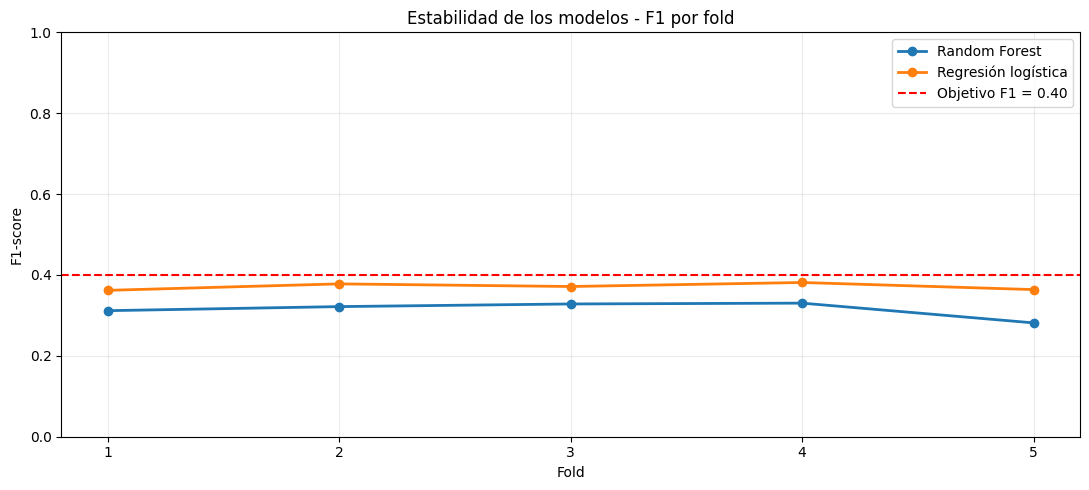

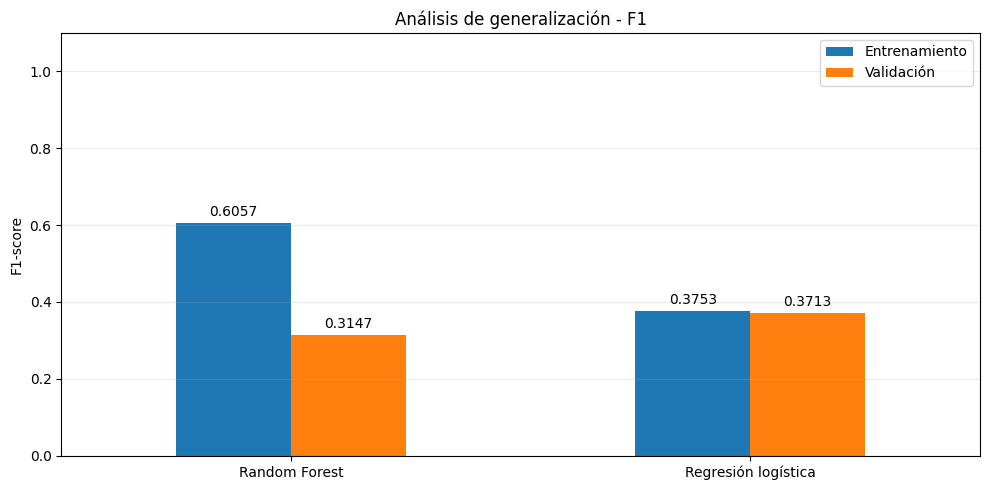

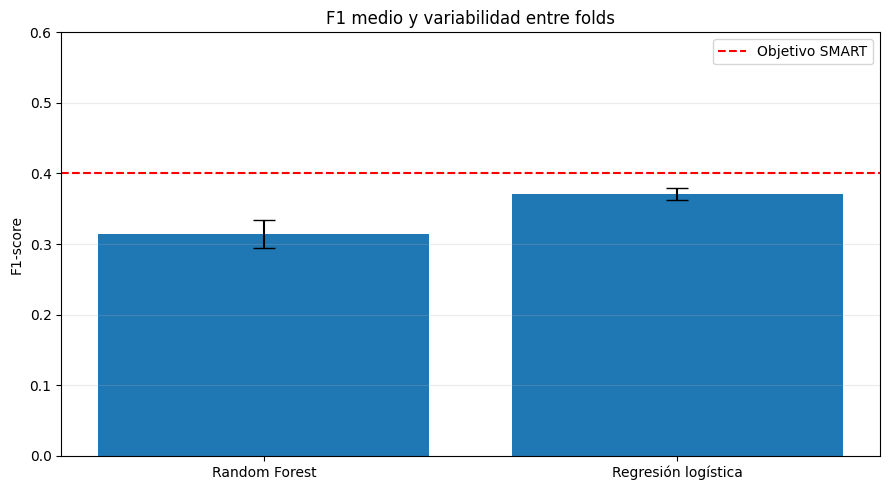


Tres gráficas adicionales generadas


In [21]:
# ==========================================
# GRÁFICA 4: F1 POR FOLD
# ==========================================

fig, ax = plt.subplots(
    figsize=(11, 5)
)

for nombre, grupo in df_cv_nueva.groupby(
    "modelo"
):

    grupo = grupo.sort_values("fold")

    ax.plot(
        grupo["fold"],
        grupo["f1"],
        marker="o",
        linewidth=2,
        label=nombres_cortos.get(
            nombre,
            nombre
        )
    )

ax.axhline(
    OBJETIVOS["f1_minimo"],
    color="red",
    linestyle="--",
    label="Objetivo F1 = 0.40"
)

ax.set_title(
    "Estabilidad de los modelos - F1 por fold"
)

ax.set_xlabel("Fold")
ax.set_ylabel("F1-score")
ax.set_xticks(range(1, 6))
ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "04_f1_validacion_cruzada.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ==========================================
# GRÁFICA 5: ENTRENAMIENTO VS VALIDACIÓN
# ==========================================

df_brecha = (
    df_cv_nueva
    .groupby("modelo")[
        ["f1_entrenamiento", "f1"]
    ]
    .mean()
)

df_brecha.index = [
    nombres_cortos.get(n, n)
    for n in df_brecha.index
]

df_brecha.columns = [
    "Entrenamiento",
    "Validación"
]

ax = df_brecha.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title(
    "Análisis de generalización - F1"
)

ax.set_ylabel("F1-score")
ax.set_xlabel("")
ax.set_ylim(0, 1.10)
ax.grid(axis="y", alpha=0.25)

for contenedor in ax.containers:

    ax.bar_label(
        contenedor,
        fmt="%.4f",
        padding=3
    )

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "05_entrenamiento_vs_validacion.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ==========================================
# GRÁFICA 6: MEDIA Y DESVIACIÓN ESTÁNDAR
# ==========================================

df_estabilidad = (
    df_cv_nueva
    .groupby("modelo")["f1"]
    .agg(["mean", "std"])
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.bar(
    [
        nombres_cortos.get(n, n)
        for n in df_estabilidad.index
    ],
    df_estabilidad["mean"],
    yerr=df_estabilidad["std"],
    capsize=8
)

ax.axhline(
    OBJETIVOS["f1_minimo"],
    color="red",
    linestyle="--",
    label="Objetivo SMART"
)

ax.set_title(
    "F1 medio y variabilidad entre folds"
)

ax.set_ylabel("F1-score")
ax.set_ylim(0, 0.60)
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "06_estabilidad_modelos.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nTres gráficas adicionales generadas")

In [22]:
fecha = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

ruta_respaldo = Path(
    f"/content/Actividad6_Avance_Etapa04_{fecha}.zip"
)

carpetas_respaldo = [
    "resultados",
    "graficas",
    "documentacion"
]

with zipfile.ZipFile(
    ruta_respaldo,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for carpeta in carpetas_respaldo:

        for archivo in (
            ruta_base / carpeta
        ).rglob("*"):

            if archivo.is_file():

                z.write(
                    archivo,
                    archivo.relative_to(ruta_base)
                )

print("Respaldo generado:", ruta_respaldo.name)

print(
    "Tamaño:",
    round(
        ruta_respaldo.stat().st_size / 1024,
        2
    ),
    "KB"
)

files.download(str(ruta_respaldo))

Respaldo generado: Actividad6_Avance_Etapa04_20261128_074520.zip
Tamaño: 1507.97 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 05. Optimización de umbrales de decisión

En esta etapa se analizará el comportamiento de los modelos de regresión logística y Random Forest utilizando diferentes umbrales de clasificación.

Para cada modelo se evaluarán 99 umbrales, comprendidos entre 0.01 y 0.99, utilizando exclusivamente las predicciones Out-of-Fold obtenidas mediante validación cruzada.

Se calcularán las métricas de clasificación y los indicadores comerciales correspondientes a cada umbral.

Se identificarán el umbral de máximo F1-score y el mejor umbral que permita cumplir simultáneamente los criterios SMART establecidos previamente.

Los umbrales seleccionados quedarán registrados antes de realizar su evaluación sobre el conjunto de prueba histórico.

Esta actividad no modifica los hiperparámetros ni requiere entrenamientos adicionales de los modelos.

In [23]:
print("=" * 70)
print("VERIFICACIÓN DE PREDICCIONES OOF")
print("=" * 70)

# Verificar cantidad de registros
assert len(predicciones_oof) == len(X_train)

# Verificar que no existan registros duplicados
assert predicciones_oof["id_registro"].is_unique

# Verificar correspondencia con los datos originales
assert np.array_equal(
    predicciones_oof["id_registro"].to_numpy(),
    X_train.index.to_numpy()
)

assert np.array_equal(
    predicciones_oof["y_real"].to_numpy(),
    y_train.to_numpy()
)

# Verificar que entrenamiento y prueba
# no compartan registros
assert set(
    predicciones_oof["id_registro"]
).isdisjoint(
    predicciones_prueba["id_registro"]
)

# Verificar probabilidades
for nombre in modelos.keys():

    columna = f"{nombre}_proba"

    assert predicciones_oof[columna].notna().all()

    assert predicciones_oof[columna].between(
        0, 1
    ).all()

    print("\nModelo:", nombre)

    print(
        predicciones_oof[columna]
        .describe()
        .round(6)
    )

print("\nRegistros OOF:", len(predicciones_oof))

print(
    "Contrataciones reales:",
    predicciones_oof["y_real"].sum()
)

print(
    "\n[OK] Integridad de las predicciones verificada"
)

print(
    "[OK] Sin registros compartidos "
    "entre entrenamiento y prueba"
)

VERIFICACIÓN DE PREDICCIONES OOF

Modelo: Random_forest
count    36156.000000
mean         0.116763
std          0.137805
min          0.004800
25%          0.044405
50%          0.070017
75%          0.113384
max          0.906084
Name: Random_forest_proba, dtype: float64

Modelo: Regresion_logistica
count    36156.000000
mean         0.414974
std          0.193831
min          0.004172
25%          0.272697
50%          0.395165
75%          0.513749
max          0.999941
Name: Regresion_logistica_proba, dtype: float64

Registros OOF: 36156
Contrataciones reales: 4231

[OK] Integridad de las predicciones verificada
[OK] Sin registros compartidos entre entrenamiento y prueba


In [24]:
# Definir los 99 umbrales
umbrales = np.round(
    np.arange(1, 100) / 100,
    2
)

resultados_umbrales = []

y_oof = predicciones_oof[
    "y_real"
].to_numpy()

print("=" * 70)
print("EXPERIMENTACIÓN CON UMBRALES")
print("=" * 70)

for nombre in modelos.keys():

    print("\nEvaluando:", nombre)

    proba = predicciones_oof[
        f"{nombre}_proba"
    ].to_numpy()

    # ROC-AUC no cambia con el umbral
    auc_modelo = roc_auc_score(
        y_oof,
        proba
    )

    for umbral in umbrales:

        # Aplicar la regla de decisión
        pred = (
            proba >= umbral
        ).astype(int)

        # Calcular métricas
        resultado = evaluar_clasificacion(
            nombre,
            y_oof,
            pred
        )

        resultado["roc_auc"] = auc_modelo

        resultado["umbral"] = float(umbral)

        # Verificar criterios SMART
        resultado["cumple_f1"] = (
            resultado["f1"] >=
            OBJETIVOS["f1_minimo"]
        )

        resultado["cumple_recall"] = (
            resultado["recall"] >=
            OBJETIVOS["recall_minimo"]
        )

        resultado["cumple_precision"] = (
            resultado["precision"] >=
            OBJETIVOS["precision_minima"]
        )

        resultado["cumple_smart"] = (
            resultado["cumple_f1"] and
            resultado["cumple_recall"] and
            resultado["cumple_precision"]
        )

        resultados_umbrales.append(
            resultado
        )

    print("Umbrales evaluados:", len(umbrales))

df_umbrales = pd.DataFrame(
    resultados_umbrales
)

assert len(df_umbrales) == 198

# Guardar todos los escenarios
df_umbrales.to_csv(
    ruta_base / "resultados" /
    "evaluacion_umbrales_oof.csv",
    index=False
)

print("\n" + "=" * 70)

print(
    "TOTAL DE ESCENARIOS:",
    len(df_umbrales)
)

print("=" * 70)

print("\nUmbrales que cumplen los objetivos:")

display(
    df_umbrales.groupby("modelo")[
        "cumple_smart"
    ].sum()
)

print("\nPrimeros escenarios evaluados:")

display(
    df_umbrales[
        [
            "modelo",
            "umbral",
            "precision",
            "recall",
            "f1",
            "clientes_seleccionados",
            "cumple_smart"
        ]
    ].head(10).round(6)
)

EXPERIMENTACIÓN CON UMBRALES

Evaluando: Random_forest
Umbrales evaluados: 99

Evaluando: Regresion_logistica
Umbrales evaluados: 99

TOTAL DE ESCENARIOS: 198

Umbrales que cumplen los objetivos:


,cumple_smart
modelo,
Random_forest,3
Regresion_logistica,0



Primeros escenarios evaluados:


,modelo,umbral,precision,recall,f1,clientes_seleccionados,cumple_smart
0,Random_forest,0.01,0.117221,0.999527,0.209834,36077,False
1,Random_forest,0.02,0.120772,0.988182,0.215238,34619,False
2,Random_forest,0.03,0.129178,0.967384,0.227921,31685,False
3,Random_forest,0.04,0.139427,0.940203,0.242842,28531,False
4,Random_forest,0.05,0.153315,0.912787,0.262534,25190,False
5,Random_forest,0.06,0.171584,0.870007,0.286638,21453,False
6,Random_forest,0.07,0.193242,0.825810,0.313195,18081,False
7,Random_forest,0.08,0.216075,0.780903,0.338490,15291,False
8,Random_forest,0.09,0.240495,0.740014,0.363014,13019,False
9,Random_forest,0.10,0.270648,0.704798,0.391108,11018,False


In [25]:
selecciones = []

umbrales_seleccionados = {}

columnas_mostrar = [
    "modelo",
    "criterio",
    "umbral",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "especificidad",
    "clientes_seleccionados",
    "VP",
    "FP",
    "FN",
    "cumple_smart"
]

print("=" * 70)
print("SELECCIÓN DE UMBRALES")
print("=" * 70)

for nombre in modelos.keys():

    grupo = df_umbrales[
        df_umbrales["modelo"] == nombre
    ].copy()

    # 1. Umbral original
    original = grupo[
        np.isclose(grupo["umbral"], 0.50)
    ].iloc[0].copy()

    original["criterio"] = "Original_0.50"

    selecciones.append(original)

    # 2. Umbral de máximo F1
    mejor_f1 = grupo.sort_values(
        ["f1", "precision", "umbral"],
        ascending=[False, False, False]
    ).iloc[0].copy()

    mejor_f1["criterio"] = "Maximo_F1"

    selecciones.append(mejor_f1)

    # 3. Umbral que cumple objetivos SMART
    candidatos_smart = grupo[
        grupo["cumple_smart"]
    ]

    if not candidatos_smart.empty:

        mejor_smart = candidatos_smart.sort_values(
            ["f1", "precision", "umbral"],
            ascending=[False, False, False]
        ).iloc[0].copy()

        mejor_smart["criterio"] = "Mejor_SMART"

        selecciones.append(mejor_smart)

        elegido = mejor_smart

        criterio_elegido = "Cumple_SMART"

    else:

        elegido = mejor_f1

        criterio_elegido = (
            "Maximo_F1_sin_cumplir_SMART"
        )

    # Guardar el candidato por modelo
    umbrales_seleccionados[nombre] = {
        "umbral": float(elegido["umbral"]),
        "criterio": criterio_elegido,
        "f1_oof": float(elegido["f1"]),
        "precision_oof": float(
            elegido["precision"]
        ),
        "recall_oof": float(elegido["recall"]),
        "cumple_smart_oof": bool(
            elegido["cumple_smart"]
        )
    }

    print("\nModelo:", nombre)

    print(
        "Umbrales que cumplen SMART:",
        len(candidatos_smart)
    )

    print(
        "Umbral candidato:",
        elegido["umbral"]
    )

    print("Criterio:", criterio_elegido)

    print(f"F1: {elegido['f1']:.4f}")

    print(
        f"Precision: "
        f"{elegido['precision']:.4f}"
    )

    print(
        f"Recall: "
        f"{elegido['recall']:.4f}"
    )

df_selecciones = pd.DataFrame(
    selecciones
).reset_index(drop=True)

display(
    df_selecciones[
        columnas_mostrar
    ].round(6)
)

df_selecciones.to_csv(
    ruta_base / "resultados" /
    "comparacion_umbrales_oof.csv",
    index=False
)

print("\nSelección de umbrales finalizada")

SELECCIÓN DE UMBRALES

Modelo: Random_forest
Umbrales que cumplen SMART: 3
Umbral candidato: 0.14
Criterio: Cumple_SMART
F1: 0.4570
Precision: 0.3673
Recall: 0.6048

Modelo: Regresion_logistica
Umbrales que cumplen SMART: 0
Umbral candidato: 0.62
Criterio: Maximo_F1_sin_cumplir_SMART
F1: 0.4379
Precision: 0.4169
Recall: 0.4611


,modelo,criterio,umbral,accuracy,precision,recall,f1,roc_auc,especificidad,clientes_seleccionados,VP,FP,FN,cumple_smart
0,Random_forest,Original_0.50,0.50,0.895315,0.672334,0.205625,0.314932,0.793610,0.986719,1294,870,424,3361,False
1,Random_forest,Maximo_F1,0.19,0.863923,0.434318,0.538407,0.480794,0.793610,0.907063,5245,2278,2967,1953,False
2,Random_forest,Mejor_SMART,0.14,0.831812,0.367250,0.604822,0.457005,0.793610,0.861895,6968,2559,4409,1672,True
3,Regresion_logistica,Original_0.50,0.50,0.754536,0.265122,0.619475,0.371325,0.763788,0.772435,9886,2621,7265,1610,False
4,Regresion_logistica,Maximo_F1,0.62,0.861461,0.416880,0.461120,0.437886,0.763788,0.914518,4680,1951,2729,2280,False



Selección de umbrales finalizada


In [26]:
df_candidatos = pd.DataFrame.from_dict(
    umbrales_seleccionados,
    orient="index"
)

df_candidatos.index.name = "modelo"

df_candidatos = (
    df_candidatos.reset_index()
)

# Priorizar candidatos que cumplen SMART
# y después el mayor F1

df_candidatos = df_candidatos.sort_values(
    [
        "cumple_smart_oof",
        "f1_oof",
        "precision_oof"
    ],
    ascending=[False, False, False]
).reset_index(drop=True)

candidato_preliminar = (
    df_candidatos.iloc[0]
)

modelo_candidato = (
    candidato_preliminar["modelo"]
)

umbral_candidato = float(
    candidato_preliminar["umbral"]
)

print("=" * 70)
print("SELECCIÓN PRELIMINAR DEL MODELO")
print("=" * 70)

display(df_candidatos.round(6))

print("\nModelo candidato:", modelo_candidato)

print("Umbral candidato:", umbral_candidato)

print(
    "F1 OOF:",
    round(candidato_preliminar["f1_oof"], 6)
)

print(
    "Cumple SMART:",
    candidato_preliminar["cumple_smart_oof"]
)

if candidato_preliminar["cumple_smart_oof"]:

    print(
        "\nCandidato elegible para "
        "evaluación posterior"
    )

else:

    print(
        "\nNingún candidato cumple todos "
        "los objetivos SMART"
    )

    print(
        "La selección es exclusivamente "
        "exploratoria"
    )

df_candidatos.to_csv(
    ruta_base / "resultados" /
    "modelos_candidatos_oof.csv",
    index=False
)

SELECCIÓN PRELIMINAR DEL MODELO


,modelo,umbral,criterio,f1_oof,precision_oof,recall_oof,cumple_smart_oof
0,Random_forest,0.14,Cumple_SMART,0.457005,0.36725,0.604822,True
1,Regresion_logistica,0.62,Maximo_F1_sin_cumplir_SMART,0.437886,0.41688,0.461120,False



Modelo candidato: Random_forest
Umbral candidato: 0.14
F1 OOF: 0.457005
Cumple SMART: True

Candidato elegible para evaluación posterior


In [31]:
from datetime import datetime, timezone

registro_seleccion = {
    "fecha_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "fuente_seleccion": "Predicciones Out-of-Fold",

    "registros_validacion": int(
        len(predicciones_oof)
    ),

    "umbrales_evaluados_por_modelo": int(
        len(umbrales)
    ),

    "criterios_smart": OBJETIVOS,

    "modelos": umbrales_seleccionados,

    "modelo_candidato": modelo_candidato,

    "umbral_candidato": umbral_candidato,

    "cumple_smart_oof": bool(
        candidato_preliminar["cumple_smart_oof"]
    ),

    "conjunto_prueba_utilizado_para_ajuste": False,

    "estado": (
        "Candidato pendiente de evaluación "
        "sobre prueba histórica"
    )
}

ruta_seleccion = (
    ruta_base / "documentacion" /
    "seleccion_umbrales.json"
)

with open(
    ruta_seleccion,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        registro_seleccion,
        f,
        indent=4,
        ensure_ascii=False
    )

print(json.dumps(
    registro_seleccion,
    indent=4,
    ensure_ascii=False
))

print("\nConfiguración registrada:", ruta_seleccion)

{
    "fecha_utc": "2026-11-28T08:01:34.433465+00:00",
    "fuente_seleccion": "Predicciones Out-of-Fold",
    "registros_validacion": 36156,
    "umbrales_evaluados_por_modelo": 99,
    "criterios_smart": {
        "f1_minimo": 0.4,
        "recall_minimo": 0.6,
        "precision_minima": 0.3,
        "metrica_principal": "f1",
        "nivel_significancia": 0.05,
        "nivel_confianza": 0.95,
        "cv_folds": 5,
        "random_state": 42,
        "umbral_original": 0.5
    },
    "modelos": {
        "Random_forest": {
            "umbral": 0.14,
            "criterio": "Cumple_SMART",
            "f1_oof": 0.45700508974015536,
            "precision_oof": 0.36725028702640644,
            "recall_oof": 0.6048215551878988,
            "cumple_smart_oof": true
        },
        "Regresion_logistica": {
            "umbral": 0.62,
            "criterio": "Maximo_F1_sin_cumplir_SMART",
            "f1_oof": 0.43788575917405453,
            "precision_oof": 0.4168803418803419,
  

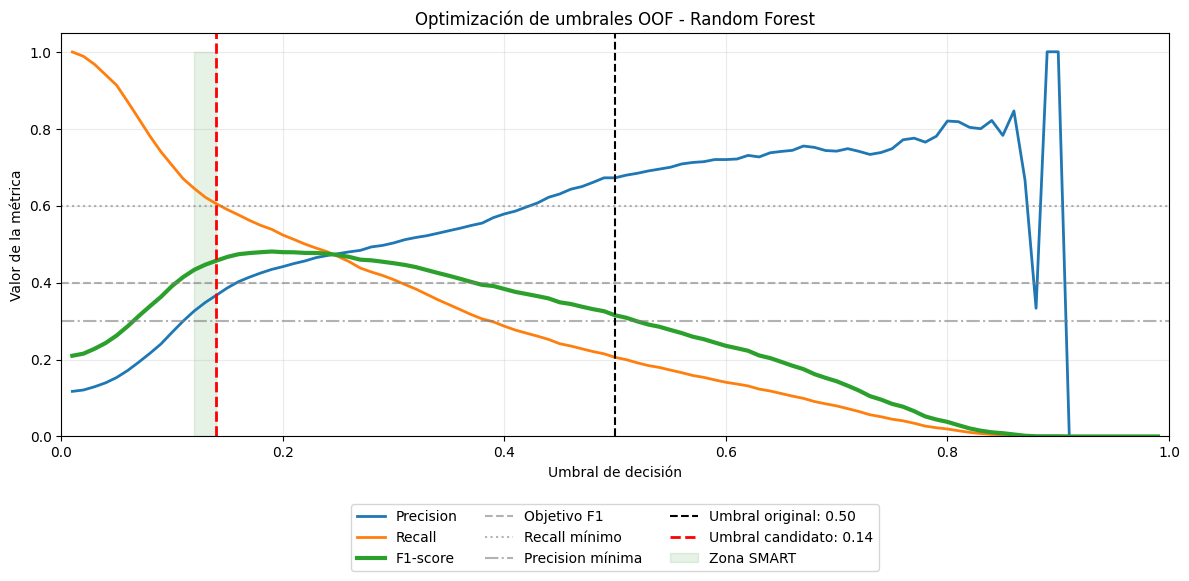

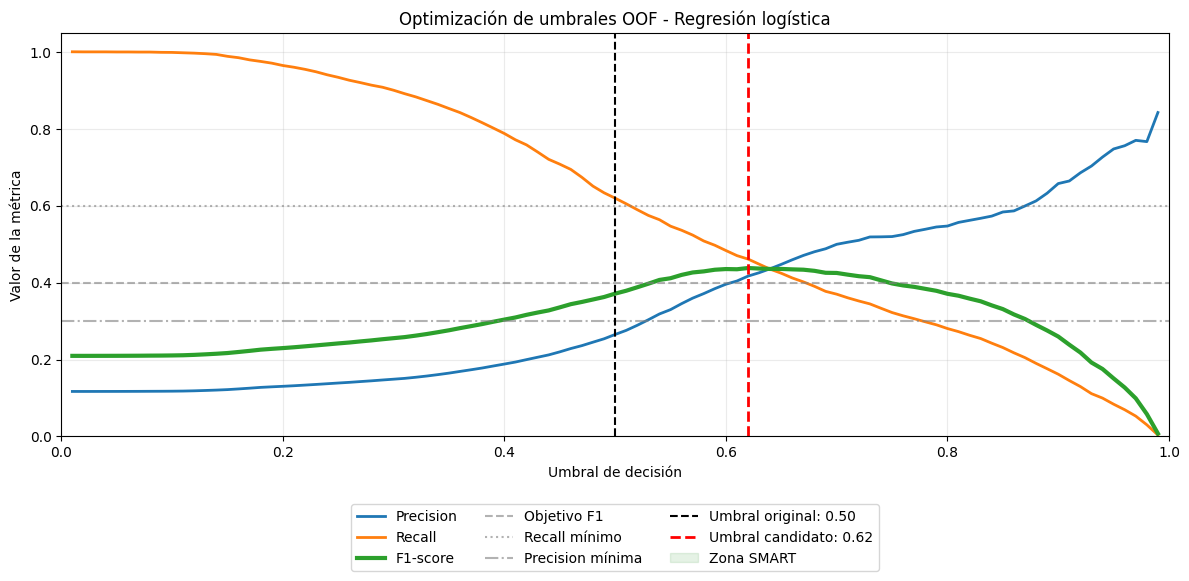


Gráficas de umbrales generadas


In [27]:
for numero, nombre in enumerate(
    modelos.keys(),
    start=7
):

    grupo = df_umbrales[
        df_umbrales["modelo"] == nombre
    ].sort_values("umbral")

    elegido = umbrales_seleccionados[
        nombre
    ]["umbral"]

    fig, ax = plt.subplots(
        figsize=(12, 6)
    )

    ax.plot(
        grupo["umbral"],
        grupo["precision"],
        label="Precision",
        linewidth=2
    )

    ax.plot(
        grupo["umbral"],
        grupo["recall"],
        label="Recall",
        linewidth=2
    )

    ax.plot(
        grupo["umbral"],
        grupo["f1"],
        label="F1-score",
        linewidth=3
    )

    # Objetivos SMART
    ax.axhline(
        OBJETIVOS["f1_minimo"],
        color="gray",
        linestyle="--",
        alpha=0.6,
        label="Objetivo F1"
    )

    ax.axhline(
        OBJETIVOS["recall_minimo"],
        color="gray",
        linestyle=":",
        alpha=0.6,
        label="Recall mínimo"
    )

    ax.axhline(
        OBJETIVOS["precision_minima"],
        color="gray",
        linestyle="-.",
        alpha=0.6,
        label="Precision mínima"
    )

    # Umbral original
    ax.axvline(
        0.50,
        color="black",
        linestyle="--",
        label="Umbral original: 0.50"
    )

    # Umbral candidato
    ax.axvline(
        elegido,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Umbral candidato: {elegido:.2f}"
    )

    # Resaltar los umbrales que cumplen SMART
    ax.fill_between(
        grupo["umbral"].to_numpy(),
        0,
        1,
        where=grupo[
            "cumple_smart"
        ].to_numpy(),
        color="green",
        alpha=0.10,
        label="Zona SMART"
    )

    ax.set_title(
        "Optimización de umbrales OOF - " +
        nombres_cortos.get(nombre, nombre)
    )

    ax.set_xlabel("Umbral de decisión")
    ax.set_ylabel("Valor de la métrica")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)

    ax.grid(alpha=0.25)

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        ncol=3
    )

    plt.tight_layout()

    plt.savefig(
        ruta_base / "graficas" /
        f"{numero:02d}_umbrales_{nombre}.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("\nGráficas de umbrales generadas")

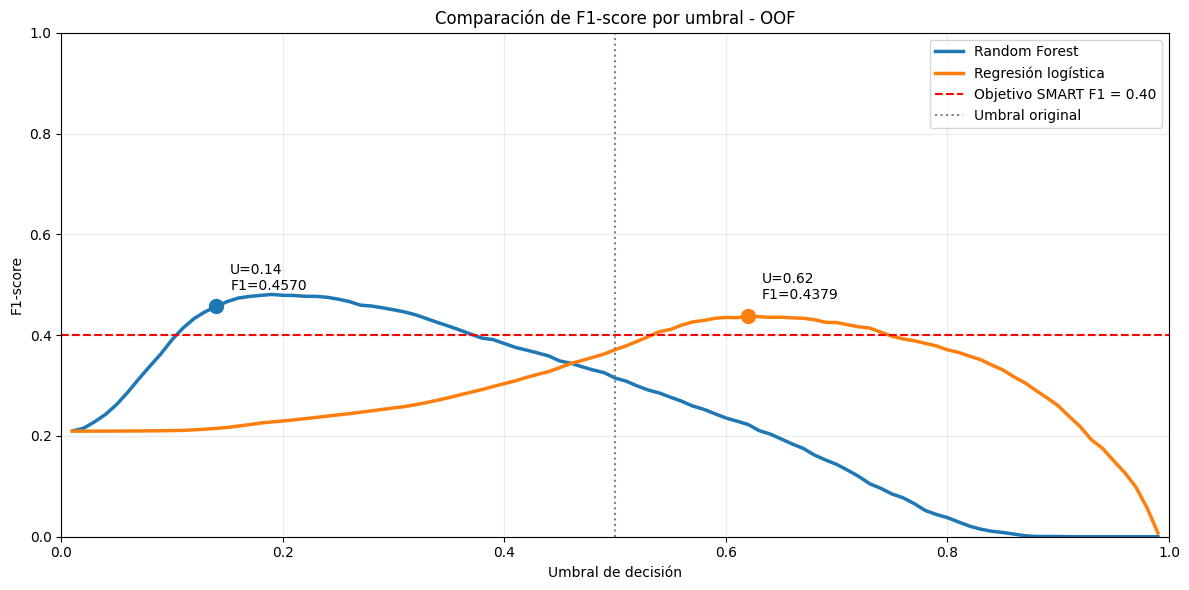

In [28]:
fig, ax = plt.subplots(
    figsize=(12, 6)
)

for nombre, grupo in df_umbrales.groupby(
    "modelo"
):

    grupo = grupo.sort_values("umbral")

    linea, = ax.plot(
        grupo["umbral"],
        grupo["f1"],
        linewidth=2.5,
        label=nombres_cortos.get(
            nombre,
            nombre
        )
    )

    candidato = umbrales_seleccionados[
        nombre
    ]

    ax.scatter(
        candidato["umbral"],
        candidato["f1_oof"],
        color=linea.get_color(),
        s=100,
        zorder=5
    )

    ax.annotate(
        f"U={candidato['umbral']:.2f}\n"
        f"F1={candidato['f1_oof']:.4f}",
        (
            candidato["umbral"],
            candidato["f1_oof"]
        ),
        xytext=(10, 12),
        textcoords="offset points"
    )

ax.axhline(
    OBJETIVOS["f1_minimo"],
    color="red",
    linestyle="--",
    label="Objetivo SMART F1 = 0.40"
)

ax.axvline(
    0.50,
    color="gray",
    linestyle=":",
    label="Umbral original"
)

ax.set_title(
    "Comparación de F1-score por umbral - OOF"
)

ax.set_xlabel("Umbral de decisión")
ax.set_ylabel("F1-score")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "09_comparacion_f1_umbrales.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [29]:
comparacion_impacto = []

for nombre in modelos.keys():

    grupo = df_umbrales[
        df_umbrales["modelo"] == nombre
    ]

    original = grupo[
        np.isclose(grupo["umbral"], 0.50)
    ].iloc[0]

    umbral_nuevo = (
        umbrales_seleccionados[nombre]["umbral"]
    )

    ajustado = grupo[
        np.isclose(
            grupo["umbral"],
            umbral_nuevo
        )
    ].iloc[0]

    comparacion_impacto.append({
        "modelo": nombre,

        "umbral_original": 0.50,

        "umbral_ajustado": umbral_nuevo,

        "f1_original": original["f1"],

        "f1_ajustado": ajustado["f1"],

        "mejora_f1_pp": 100 * (
            ajustado["f1"] - original["f1"]
        ),

        "precision_original": original[
            "precision"
        ],

        "precision_ajustada": ajustado[
            "precision"
        ],

        "recall_original": original["recall"],

        "recall_ajustado": ajustado["recall"],

        "contactos_originales": original[
            "clientes_seleccionados"
        ],

        "contactos_ajustados": ajustado[
            "clientes_seleccionados"
        ],

        "diferencia_contactos": (
            ajustado["clientes_seleccionados"] -
            original["clientes_seleccionados"]
        ),

        "contrataciones_originales": original[
            "VP"
        ],

        "contrataciones_ajustadas": ajustado[
            "VP"
        ],

        "diferencia_contrataciones": (
            ajustado["VP"] - original["VP"]
        ),

        "cumple_smart": ajustado[
            "cumple_smart"
        ]
    })

df_impacto_umbral = pd.DataFrame(
    comparacion_impacto
)

print("=" * 70)
print("IMPACTO DEL AJUSTE DE UMBRALES - OOF")
print("=" * 70)

display(
    df_impacto_umbral.T.round(6)
)

df_impacto_umbral.to_csv(
    ruta_base / "resultados" /
    "impacto_ajuste_umbrales_oof.csv",
    index=False
)

print("\nComparación comercial guardada")

IMPACTO DEL AJUSTE DE UMBRALES - OOF


,0,1
modelo,Random_forest,Regresion_logistica
umbral_original,0.5,0.5
umbral_ajustado,0.14,0.62
f1_original,0.314932,0.371325
f1_ajustado,0.457005,0.437886
mejora_f1_pp,14.207296,6.656041
precision_original,0.672334,0.265122
precision_ajustada,0.36725,0.41688
recall_original,0.205625,0.619475
recall_ajustado,0.604822,0.46112



Comparación comercial guardada


In [30]:
fecha = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

ruta_respaldo = Path(
    f"/content/Actividad6_Avance_Etapa05_{fecha}.zip"
)

carpetas_respaldo = [
    "resultados",
    "graficas",
    "documentacion"
]

with zipfile.ZipFile(
    ruta_respaldo,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for carpeta in carpetas_respaldo:

        for archivo in (
            ruta_base / carpeta
        ).rglob("*"):

            if archivo.is_file():

                z.write(
                    archivo,
                    archivo.relative_to(ruta_base)
                )

print("Respaldo generado:", ruta_respaldo.name)

print(
    "Tamaño:",
    round(
        ruta_respaldo.stat().st_size / 1024,
        2
    ),
    "KB"
)

files.download(str(ruta_respaldo))

Respaldo generado: Actividad6_Avance_Etapa05_20261128_075237.zip
Tamaño: 1969.08 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 06. Evaluación comparativa sobre el conjunto de prueba

Como resultado de la experimentación con 198 escenarios de clasificación, Random Forest fue seleccionado como modelo candidato con un umbral de decisión de 0.14, al cumplir simultáneamente los tres objetivos SMART sobre las predicciones Out-of-Fold.

Por otra parte, la regresión logística obtuvo su mejor F1-score con un umbral de 0.62, aunque no consiguió cumplir el recall mínimo establecido.

En esta etapa se evaluarán ambos modelos con sus umbrales originales y ajustados sobre los 9,039 registros del conjunto de prueba histórico.

Se analizará si las mejoras observadas durante la validación se mantienen, mediante métricas de clasificación, matrices de confusión, curvas ROC y Precision-Recall e indicadores comerciales.

Los umbrales seleccionados permanecerán sin modificaciones, independientemente de los resultados obtenidos.

In [32]:
with open(
    ruta_seleccion,
    "r",
    encoding="utf-8"
) as f:
    seleccion_congelada = json.load(f)

assert (
    seleccion_congelada[
        "conjunto_prueba_utilizado_para_ajuste"
    ] is False
)

assert seleccion_congelada[
    "modelo_candidato"
] == modelo_candidato

assert np.isclose(
    seleccion_congelada["umbral_candidato"],
    umbral_candidato
)

assert len(predicciones_prueba) == 9039

assert np.array_equal(
    predicciones_prueba["id_registro"].to_numpy(),
    X_test.index.to_numpy()
)

assert np.array_equal(
    predicciones_prueba["y_real"].to_numpy(),
    y_test.to_numpy()
)

print("=" * 65)
print("CONFIGURACIÓN PARA EVALUACIÓN FINAL")
print("=" * 65)

for nombre, datos in (
    seleccion_congelada["modelos"].items()
):
    print(
        nombre,
        "| Umbral:", datos["umbral"],
        "| Criterio:", datos["criterio"]
    )

print("\nCandidato:", modelo_candidato)
print("Umbral:", umbral_candidato)
print("Registros de prueba:", len(y_test))

print("\n[OK] Configuración verificada")

CONFIGURACIÓN PARA EVALUACIÓN FINAL
Random_forest | Umbral: 0.14 | Criterio: Cumple_SMART
Regresion_logistica | Umbral: 0.62 | Criterio: Maximo_F1_sin_cumplir_SMART

Candidato: Random_forest
Umbral: 0.14
Registros de prueba: 9039

[OK] Configuración verificada


In [33]:
from sklearn.metrics import average_precision_score

resultados_finales = []

predicciones_finales = (
    predicciones_prueba.copy()
)

y_prueba = predicciones_finales[
    "y_real"
].to_numpy()

for nombre in modelos.keys():

    proba = predicciones_finales[
        f"{nombre}_proba"
    ].to_numpy()

    escenarios = {
        "Original": 0.50,

        "Ajustado": seleccion_congelada[
            "modelos"
        ][nombre]["umbral"]
    }

    for escenario, umbral in escenarios.items():

        if escenario == "Original":

            pred = predicciones_finales[
                f"{nombre}_pred"
            ].to_numpy()

        else:

            pred = (
                proba >= umbral
            ).astype(int)

        identificador = (
            f"{nombre}_{escenario}"
        )

        resultado = evaluar_clasificacion(
            identificador,
            y_prueba,
            pred,
            proba
        )

        resultado["algoritmo"] = nombre
        resultado["escenario"] = escenario
        resultado["umbral"] = umbral

        resultado["average_precision"] = (
            average_precision_score(
                y_prueba,
                proba
            )
        )

        resultado["cumple_f1"] = (
            resultado["f1"] >=
            OBJETIVOS["f1_minimo"]
        )

        resultado["cumple_recall"] = (
            resultado["recall"] >=
            OBJETIVOS["recall_minimo"]
        )

        resultado["cumple_precision"] = (
            resultado["precision"] >=
            OBJETIVOS["precision_minima"]
        )

        resultado["cumple_smart"] = (
            resultado["cumple_f1"] and
            resultado["cumple_recall"] and
            resultado["cumple_precision"]
        )

        resultados_finales.append(resultado)

        predicciones_finales[
            f"{identificador}_pred"
        ] = pred

df_final = pd.DataFrame(
    resultados_finales
)

print("=" * 70)
print("EVALUACIÓN SOBRE CONJUNTO DE PRUEBA")
print("=" * 70)

display(
    df_final[
        [
            "modelo",
            "umbral",
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "average_precision",
            "especificidad",
            "cumple_smart"
        ]
    ].round(6)
)

print("\nMATRICES DE CONFUSIÓN")

display(
    df_final[
        ["modelo", "VN", "FP", "FN", "VP"]
    ]
)

df_final.to_csv(
    ruta_base / "resultados" /
    "metricas_finales_prueba.csv",
    index=False
)

predicciones_finales.to_csv(
    ruta_base / "resultados" /
    "predicciones_finales_prueba.csv",
    index=False
)

print("\nEvidencias guardadas correctamente")

EVALUACIÓN SOBRE CONJUNTO DE PRUEBA


,modelo,umbral,accuracy,precision,recall,f1,roc_auc,average_precision,especificidad,cumple_smart
0,Random_forest_Original,0.50,0.893904,0.652308,0.200378,0.306580,0.803305,0.444281,0.985841,False
1,Random_forest_Ajustado,0.14,0.837593,0.379977,0.613422,0.469270,0.803305,0.444281,0.867310,True
2,Regresion_logistica_Original,0.50,0.757827,0.270774,0.631380,0.379007,0.773500,0.400261,0.774590,False
3,Regresion_logistica_Ajustado,0.62,0.863038,0.422414,0.463138,0.441839,0.773500,0.400261,0.916051,False



MATRICES DE CONFUSIÓN


,modelo,VN,FP,FN,VP
0,Random_forest_Original,7868,113,846,212
1,Random_forest_Ajustado,6922,1059,409,649
2,Regresion_logistica_Original,6182,1799,390,668
3,Regresion_logistica_Ajustado,7311,670,568,490



Evidencias guardadas correctamente


In [34]:
comparacion_generalizacion = []

for nombre in modelos.keys():

    configuracion = (
        seleccion_congelada["modelos"][nombre]
    )

    prueba = df_final[
        (df_final["algoritmo"] == nombre) &
        (df_final["escenario"] == "Ajustado")
    ].iloc[0]

    comparacion_generalizacion.append({
        "modelo": nombre,

        "umbral": configuracion["umbral"],

        "f1_oof": configuracion["f1_oof"],

        "f1_prueba": prueba["f1"],

        "diferencia_f1_pp": 100 * (
            prueba["f1"] -
            configuracion["f1_oof"]
        ),

        "precision_oof": configuracion[
            "precision_oof"
        ],

        "precision_prueba": prueba[
            "precision"
        ],

        "recall_oof": configuracion[
            "recall_oof"
        ],

        "recall_prueba": prueba["recall"],

        "cumple_smart_oof": configuracion[
            "cumple_smart_oof"
        ],

        "cumple_smart_prueba": prueba[
            "cumple_smart"
        ]
    })

df_generalizacion = pd.DataFrame(
    comparacion_generalizacion
)

print("=" * 70)
print("COMPARACIÓN OOF VS PRUEBA")
print("=" * 70)

display(
    df_generalizacion.T.round(6)
)

df_generalizacion.to_csv(
    ruta_base / "resultados" /
    "generalizacion_umbrales.csv",
    index=False
)

print("\nComparación guardada")

COMPARACIÓN OOF VS PRUEBA


,0,1
modelo,Random_forest,Regresion_logistica
umbral,0.14,0.62
f1_oof,0.457005,0.437886
f1_prueba,0.46927,0.441839
diferencia_f1_pp,1.226461,0.395374
precision_oof,0.36725,0.41688
precision_prueba,0.379977,0.422414
recall_oof,0.604822,0.46112
recall_prueba,0.613422,0.463138
cumple_smart_oof,True,False



Comparación guardada


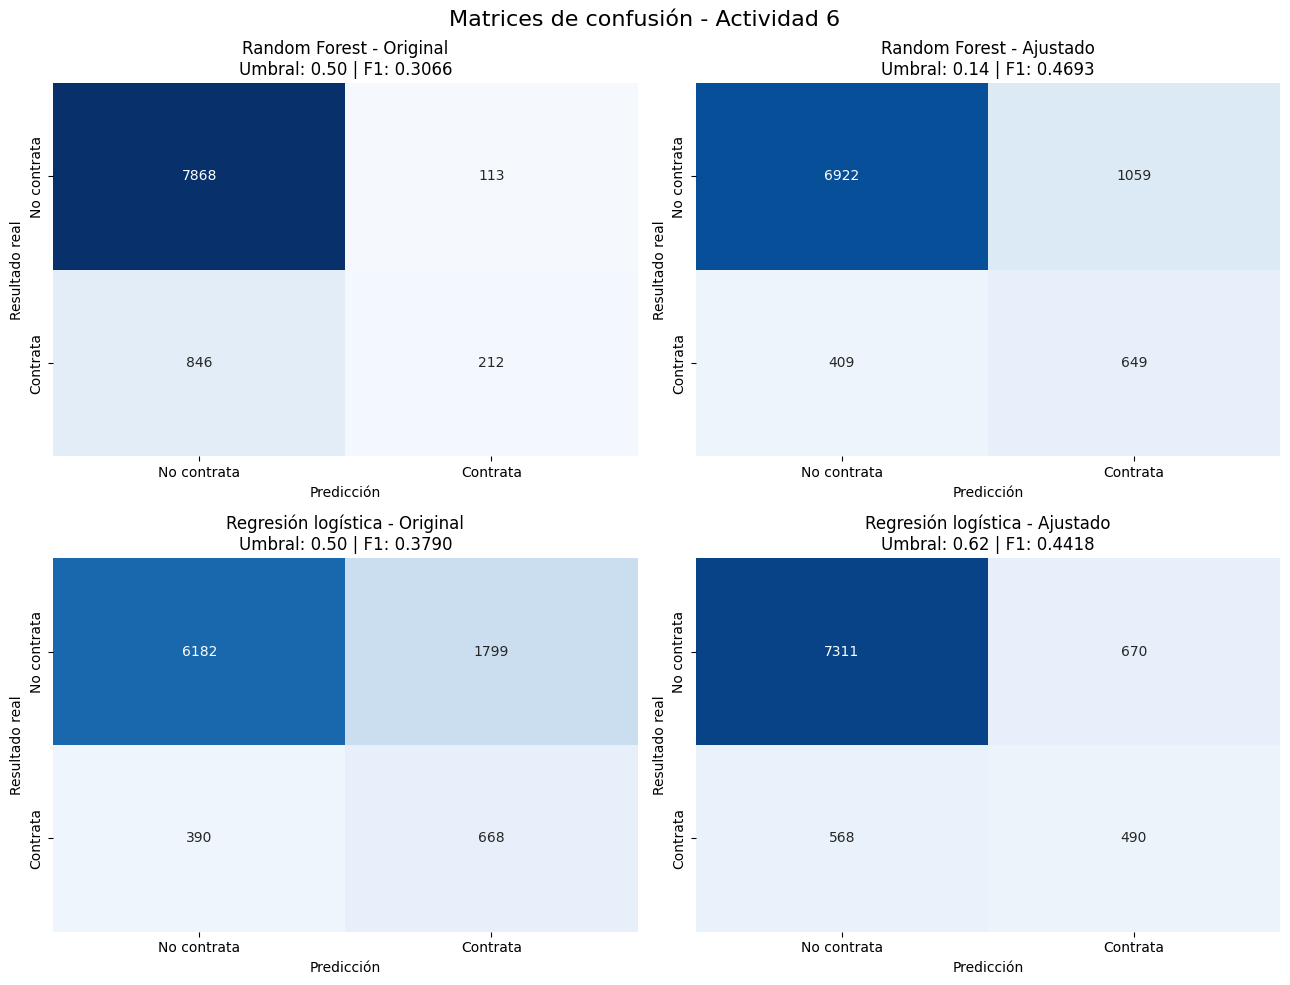

In [35]:
import seaborn as sns

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

vmax = df_final[
    ["VN", "FP", "FN", "VP"]
].to_numpy().max()

for ax, (_, fila) in zip(
    axes.flat,
    df_final.iterrows()
):

    matriz = np.array([
        [fila["VN"], fila["FP"]],
        [fila["FN"], fila["VP"]]
    ], dtype=int)

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        vmin=0,
        vmax=vmax,
        cbar=False,
        ax=ax,

        xticklabels=[
            "No contrata",
            "Contrata"
        ],

        yticklabels=[
            "No contrata",
            "Contrata"
        ]
    )

    nombre = nombres_cortos.get(
        fila["algoritmo"],
        fila["algoritmo"]
    )

    ax.set_title(
        f"{nombre} - {fila['escenario']}\n"
        f"Umbral: {fila['umbral']:.2f} | "
        f"F1: {fila['f1']:.4f}"
    )

    ax.set_xlabel("Predicción")
    ax.set_ylabel("Resultado real")

fig.suptitle(
    "Matrices de confusión - Actividad 6",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "10_matrices_confusion_finales.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

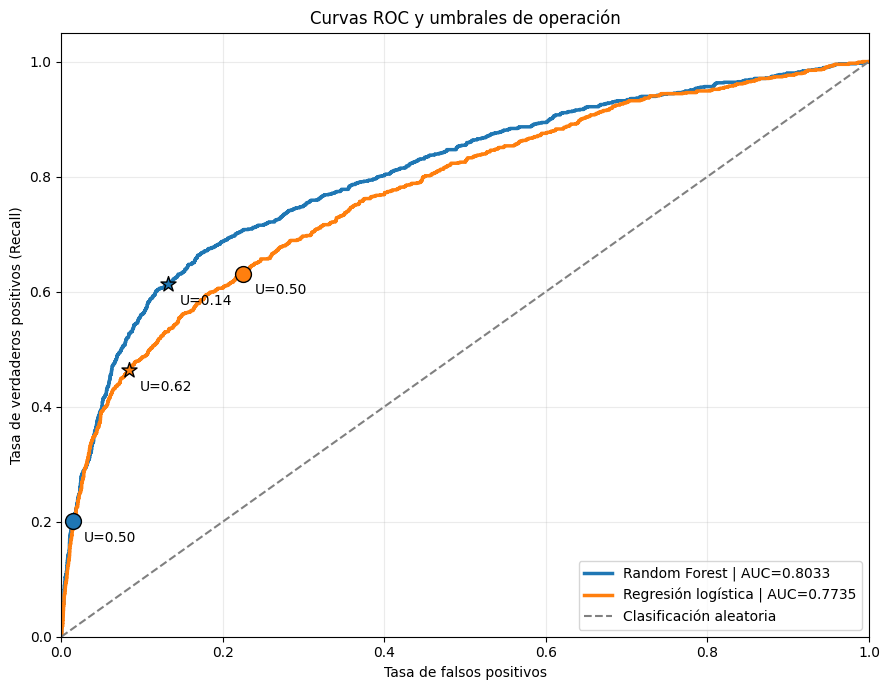

In [36]:
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(
    figsize=(9, 7)
)

for nombre in modelos.keys():

    proba = predicciones_finales[
        f"{nombre}_proba"
    ].to_numpy()

    fpr, tpr, _ = roc_curve(
        y_prueba,
        proba
    )

    auc = roc_auc_score(
        y_prueba,
        proba
    )

    linea, = ax.plot(
        fpr,
        tpr,
        linewidth=2.5,
        label=(
            nombres_cortos.get(nombre, nombre)
            + f" | AUC={auc:.4f}"
        )
    )

    filas = df_final[
        df_final["algoritmo"] == nombre
    ]

    for _, fila in filas.iterrows():

        x = 1 - fila["especificidad"]
        y = fila["recall"]

        marcador = (
            "o"
            if fila["escenario"] == "Original"
            else "*"
        )

        ax.scatter(
            x,
            y,
            marker=marcador,
            s=130,
            color=linea.get_color(),
            edgecolor="black",
            zorder=5
        )

        ax.annotate(
            f"U={fila['umbral']:.2f}",
            (x, y),
            xytext=(8, -15),
            textcoords="offset points"
        )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificación aleatoria"
)

ax.set_title(
    "Curvas ROC y umbrales de operación"
)

ax.set_xlabel(
    "Tasa de falsos positivos"
)

ax.set_ylabel(
    "Tasa de verdaderos positivos (Recall)"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)

ax.grid(alpha=0.25)
ax.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "11_curvas_roc_finales.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

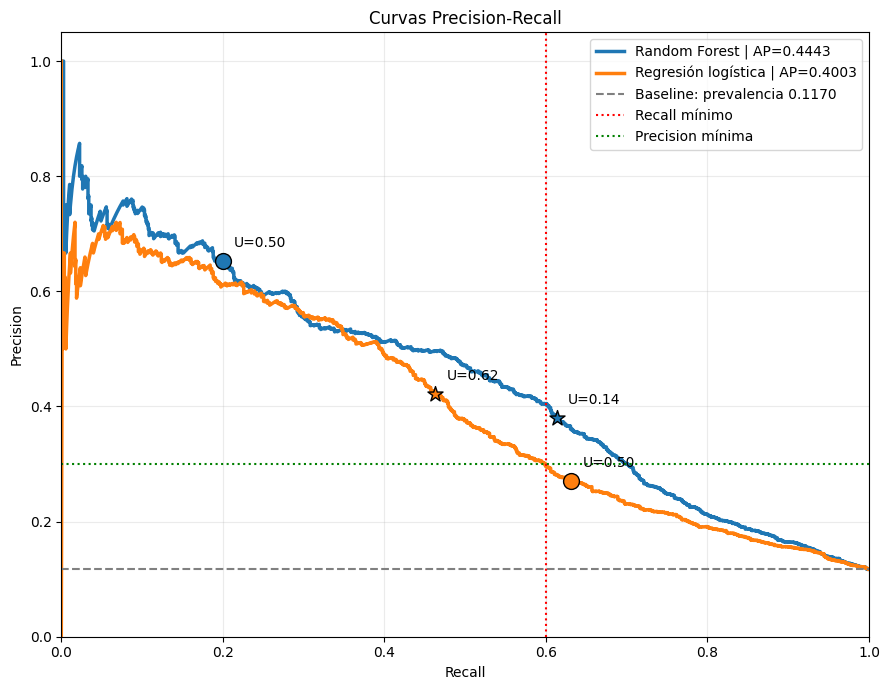

In [37]:
from sklearn.metrics import (
    precision_recall_curve
)

fig, ax = plt.subplots(
    figsize=(9, 7)
)

for nombre in modelos.keys():

    proba = predicciones_finales[
        f"{nombre}_proba"
    ].to_numpy()

    precision_curva, recall_curva, _ = (
        precision_recall_curve(
            y_prueba,
            proba
        )
    )

    ap = average_precision_score(
        y_prueba,
        proba
    )

    linea, = ax.plot(
        recall_curva,
        precision_curva,
        linewidth=2.5,
        label=(
            nombres_cortos.get(nombre, nombre)
            + f" | AP={ap:.4f}"
        )
    )

    filas = df_final[
        df_final["algoritmo"] == nombre
    ]

    for _, fila in filas.iterrows():

        marcador = (
            "o"
            if fila["escenario"] == "Original"
            else "*"
        )

        ax.scatter(
            fila["recall"],
            fila["precision"],
            marker=marcador,
            s=130,
            color=linea.get_color(),
            edgecolor="black",
            zorder=5
        )

        ax.annotate(
            f"U={fila['umbral']:.2f}",
            (
                fila["recall"],
                fila["precision"]
            ),
            xytext=(8, 10),
            textcoords="offset points"
        )

prevalencia = y_prueba.mean()

ax.axhline(
    prevalencia,
    linestyle="--",
    color="gray",
    label=(
        f"Baseline: prevalencia "
        f"{prevalencia:.4f}"
    )
)

ax.axvline(
    OBJETIVOS["recall_minimo"],
    color="red",
    linestyle=":",
    label="Recall mínimo"
)

ax.axhline(
    OBJETIVOS["precision_minima"],
    color="green",
    linestyle=":",
    label="Precision mínima"
)

ax.set_title(
    "Curvas Precision-Recall"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "12_curvas_precision_recall.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

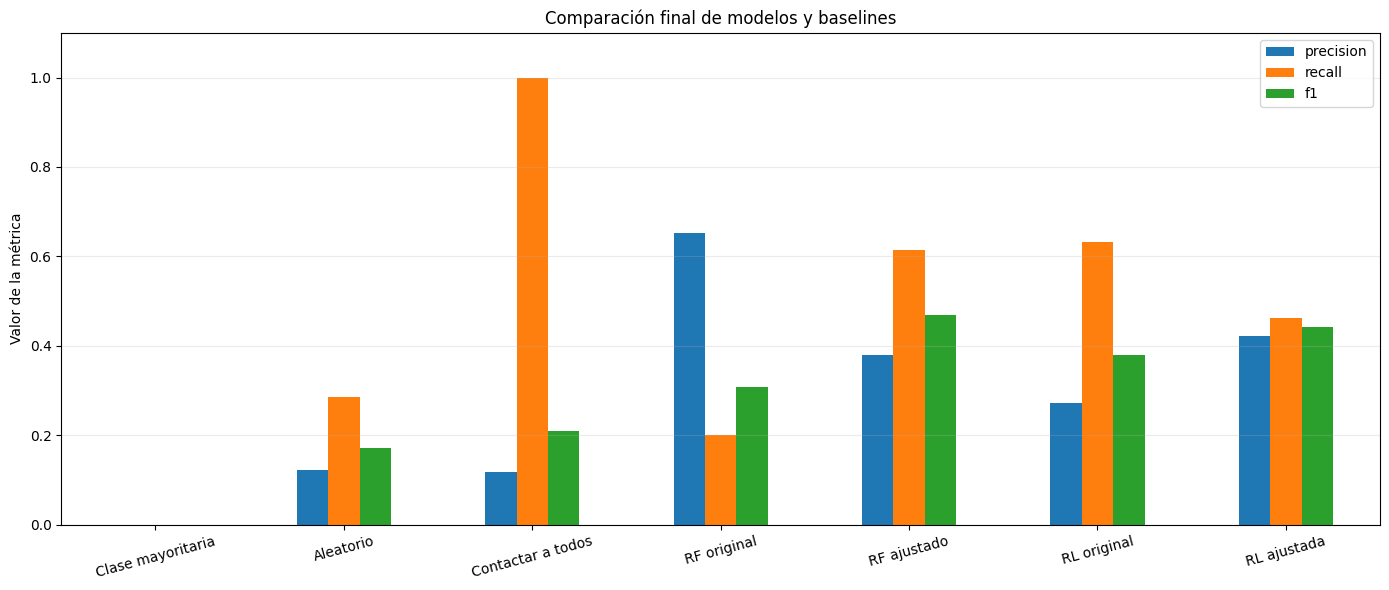

,modelo,accuracy,precision,recall,f1,roc_auc,clientes_seleccionados,VP,FP,FN
0,Baseline_mayoritario,0.882952,0.000000,0.000000,0.000000,0.500000,0,0,0,1058
1,Baseline_aleatorio,0.677066,0.122821,0.286389,0.171915,0.504189,2467,303,2164,755
2,Baseline_contactar_todos,0.117048,0.117048,1.000000,0.209567,0.500000,9039,1058,7981,0
3,Random_forest_Original,0.893904,0.652308,0.200378,0.306580,0.803305,325,212,113,846
4,Random_forest_Ajustado,0.837593,0.379977,0.613422,0.469270,0.803305,1708,649,1059,409
5,Regresion_logistica_Original,0.757827,0.270774,0.631380,0.379007,0.773500,2467,668,1799,390
6,Regresion_logistica_Ajustado,0.863038,0.422414,0.463138,0.441839,0.773500,1160,490,670,568


In [38]:
df_comparacion_final = pd.concat(
    [df_baselines, df_final],
    ignore_index=True
)

df_comparacion_final.to_csv(
    ruta_base / "resultados" /
    "comparacion_final_modelos_baselines.csv",
    index=False
)

etiquetas = {
    "Baseline_mayoritario": "Clase mayoritaria",
    "Baseline_aleatorio": "Aleatorio",
    "Baseline_contactar_todos": "Contactar a todos",

    "Random_forest_Original": "RF original",
    "Random_forest_Ajustado": "RF ajustado",

    "Regresion_logistica_Original": "RL original",
    "Regresion_logistica_Ajustado": "RL ajustada"
}

df_grafica_final = (
    df_comparacion_final.copy()
)

df_grafica_final["nombre"] = (
    df_grafica_final["modelo"]
    .map(etiquetas)
    .fillna(df_grafica_final["modelo"])
)

ax = df_grafica_final.set_index(
    "nombre"
)[
    ["precision", "recall", "f1"]
].plot(
    kind="bar",
    figsize=(14, 6),
    rot=15
)

ax.set_title(
    "Comparación final de modelos y baselines"
)

ax.set_ylabel("Valor de la métrica")
ax.set_xlabel("")
ax.set_ylim(0, 1.10)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "13_comparacion_final_metricas.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

display(
    df_comparacion_final[
        [
            "modelo",
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "clientes_seleccionados",
            "VP",
            "FP",
            "FN"
        ]
    ].round(6)
)

In [39]:
candidato_prueba = df_final[
    (df_final["algoritmo"] == modelo_candidato) &
    (df_final["escenario"] == "Ajustado")
].iloc[0]

criterios = [
    (
        "F1-score",
        candidato_prueba["f1"],
        OBJETIVOS["f1_minimo"]
    ),
    (
        "Recall",
        candidato_prueba["recall"],
        OBJETIVOS["recall_minimo"]
    ),
    (
        "Precision",
        candidato_prueba["precision"],
        OBJETIVOS["precision_minima"]
    )
]

print("=" * 70)
print("VERIFICACIÓN DEL OBJETIVO SMART")
print("=" * 70)

print("Modelo:", modelo_candidato)
print("Umbral:", umbral_candidato)

verificacion_smart = []

for metrica, valor, objetivo in criterios:

    cumple = bool(valor >= objetivo)

    estado = (
        "CUMPLE"
        if cumple
        else "NO CUMPLE"
    )

    print(
        f"\n{metrica}: {valor:.4f}"
        f" | Objetivo: {objetivo:.4f}"
        f" | {estado}"
    )

    verificacion_smart.append({
        "metrica": metrica,
        "resultado": float(valor),
        "objetivo": objetivo,
        "cumple": cumple
    })

cumplimiento_total = all(
    x["cumple"]
    for x in verificacion_smart
)

print("\n" + "=" * 70)

if cumplimiento_total:

    print(
        "El candidato cumple los objetivos "
        "SMART en prueba histórica."
    )

else:

    print(
        "El candidato no cumple todos los "
        "objetivos SMART en prueba histórica."
    )

print(
    "Pendiente: significancia estadística, "
    "prueba A/B y validación de negocio."
)

pd.DataFrame(
    verificacion_smart
).to_csv(
    ruta_base / "resultados" /
    "verificacion_smart_prueba.csv",
    index=False
)

VERIFICACIÓN DEL OBJETIVO SMART
Modelo: Random_forest
Umbral: 0.14

F1-score: 0.4693 | Objetivo: 0.4000 | CUMPLE

Recall: 0.6134 | Objetivo: 0.6000 | CUMPLE

Precision: 0.3800 | Objetivo: 0.3000 | CUMPLE

El candidato cumple los objetivos SMART en prueba histórica.
Pendiente: significancia estadística, prueba A/B y validación de negocio.


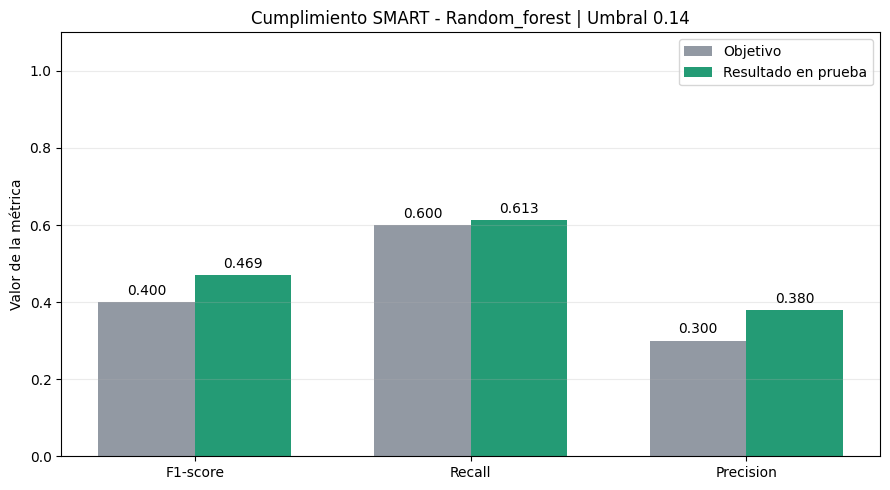

In [40]:
df_smart = pd.DataFrame(
    verificacion_smart
)

x = np.arange(len(df_smart))
ancho = 0.35

fig, ax = plt.subplots(
    figsize=(9, 5)
)

b1 = ax.bar(
    x - ancho / 2,
    df_smart["objetivo"],
    ancho,
    label="Objetivo",
    color="#9299A3"
)

b2 = ax.bar(
    x + ancho / 2,
    df_smart["resultado"],
    ancho,
    label="Resultado en prueba",
    color=[
        "#249B75" if cumple
        else "#D48B30"
        for cumple in df_smart["cumple"]
    ]
)

ax.set_xticks(x)
ax.set_xticklabels(df_smart["metrica"])

ax.set_title(
    f"Cumplimiento SMART - "
    f"{modelo_candidato} | "
    f"Umbral {umbral_candidato:.2f}"
)

ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0, 1.10)

ax.bar_label(
    b1,
    fmt="%.3f",
    padding=3
)

ax.bar_label(
    b2,
    fmt="%.3f",
    padding=3
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "14_cumplimiento_smart.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [41]:
fecha = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

ruta_respaldo = Path(
    f"/content/Actividad6_Avance_Etapa06_{fecha}.zip"
)

carpetas_respaldo = [
    "resultados",
    "graficas",
    "documentacion"
]

with zipfile.ZipFile(
    ruta_respaldo,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for carpeta in carpetas_respaldo:

        for archivo in (
            ruta_base / carpeta
        ).rglob("*"):

            if archivo.is_file():

                z.write(
                    archivo,
                    archivo.relative_to(ruta_base)
                )

print("Respaldo generado:", ruta_respaldo.name)

print(
    "Tamaño:",
    round(
        ruta_respaldo.stat().st_size / 1024,
        2
    ),
    "KB"
)

files.download(str(ruta_respaldo))

Respaldo generado: Actividad6_Avance_Etapa06_20261128_080643.zip
Tamaño: 2727.1 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 07. Análisis de significancia estadística

En esta etapa se analizará la incertidumbre de las métricas obtenidas durante la evaluación de los modelos.

Se utilizará la técnica Bootstrap con 2,000 remuestreos para estimar intervalos de confianza del 95 % para accuracy, precision, recall, F1-score y ROC-AUC.

Adicionalmente, se realizará una comparación pareada de los modelos utilizando los mismos registros en cada remuestreo, con la finalidad de estimar la incertidumbre de las diferencias observadas.

Se aplicará la prueba de McNemar para analizar las diferencias en los errores de clasificación.

El nivel de significancia establecido será de 0.05.

Los resultados permitirán distinguir entre el cumplimiento puntual de los objetivos SMART y la evidencia estadística disponible para respaldar las decisiones técnicas.

Estas pruebas se realizarán sobre el conjunto de prueba histórico, por lo que sus conclusiones estarán limitadas a las condiciones y población del experimento académico.

In [42]:
from scipy.stats import binomtest

N_BOOTSTRAP = 2000

ALPHA = OBJETIVOS["nivel_significancia"]

rng_bootstrap = np.random.default_rng(SEED)

escenarios_estadisticos = [
    "Random_forest_Original",
    "Random_forest_Ajustado",
    "Regresion_logistica_Original",
    "Regresion_logistica_Ajustado"
]

y_estadistica = predicciones_finales[
    "y_real"
].to_numpy()

pred_estadisticas = {
    nombre: predicciones_finales[
        f"{nombre}_pred"
    ].to_numpy()
    for nombre in escenarios_estadisticos
}

proba_estadisticas = {
    nombre: predicciones_finales[
        f"{nombre}_proba"
    ].to_numpy()
    for nombre in modelos.keys()
}

assert len(y_estadistica) == 9039

assert set(np.unique(y_estadistica)) == {0, 1}

for nombre, pred in pred_estadisticas.items():

    assert len(pred) == len(y_estadistica)

    assert np.isin(pred, [0, 1]).all()

print("=" * 65)
print("CONFIGURACIÓN ESTADÍSTICA")
print("=" * 65)

print("Registros:", len(y_estadistica))
print("Escenarios:", len(escenarios_estadisticos))
print("Remuestreos Bootstrap:", N_BOOTSTRAP)
print("Nivel de significancia:", ALPHA)
print("Nivel de confianza:", 1 - ALPHA)

print("\n[OK] Datos preparados")

CONFIGURACIÓN ESTADÍSTICA
Registros: 9039
Escenarios: 4
Remuestreos Bootstrap: 2000
Nivel de significancia: 0.05
Nivel de confianza: 0.95

[OK] Datos preparados


In [43]:
def metricas_bootstrap(y_real, y_pred):

    vp = np.sum(
        (y_real == 1) & (y_pred == 1)
    )

    vn = np.sum(
        (y_real == 0) & (y_pred == 0)
    )

    fp = np.sum(
        (y_real == 0) & (y_pred == 1)
    )

    fn = np.sum(
        (y_real == 1) & (y_pred == 0)
    )

    accuracy = (vp + vn) / len(y_real)

    precision = (
        vp / (vp + fp)
        if vp + fp > 0 else 0
    )

    recall = (
        vp / (vp + fn)
        if vp + fn > 0 else 0
    )

    f1 = (
        2 * vp / (2 * vp + fp + fn)
        if 2 * vp + fp + fn > 0 else 0
    )

    especificidad = (
        vn / (vn + fp)
        if vn + fp > 0 else 0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "especificidad": especificidad
    }


# Verificar que nuestra función
# reproduce las métricas conocidas

for nombre in escenarios_estadisticos:

    calculadas = metricas_bootstrap(
        y_estadistica,
        pred_estadisticas[nombre]
    )

    referencia = df_final[
        df_final["modelo"] == nombre
    ].iloc[0]

    for metrica, valor in calculadas.items():

        assert np.isclose(
            valor,
            referencia[metrica]
        )

print("[OK] Función de métricas verificada")

[OK] Función de métricas verificada


In [44]:
import time

resultados_bootstrap = []

inicio = time.perf_counter()

n = len(y_estadistica)

print("=" * 65)
print("EJECUCIÓN DE BOOTSTRAP PAREADO")
print("=" * 65)

for repeticion in range(N_BOOTSTRAP):

    # Selección aleatoria con reemplazo
    indices = rng_bootstrap.integers(
        0, n, size=n
    )

    y_b = y_estadistica[indices]

    # Evitar muestras sin ambas clases
    if len(np.unique(y_b)) < 2:
        continue

    # AUC por algoritmo:
    # no depende del umbral
    auc_b = {}

    for nombre, proba in (
        proba_estadisticas.items()
    ):

        auc_b[nombre] = roc_auc_score(
            y_b,
            proba[indices]
        )

    # Evaluar los cuatro escenarios
    # utilizando exactamente la misma muestra

    for nombre in escenarios_estadisticos:

        pred_b = pred_estadisticas[
            nombre
        ][indices]

        resultado = metricas_bootstrap(
            y_b,
            pred_b
        )

        algoritmo = nombre.rsplit(
            "_", 1
        )[0]

        resultado["roc_auc"] = auc_b[
            algoritmo
        ]

        resultado["modelo"] = nombre

        resultado["repeticion"] = (
            repeticion + 1
        )

        resultados_bootstrap.append(
            resultado
        )

    if (repeticion + 1) % 250 == 0:

        print(
            f"Remuestreos completados: "
            f"{repeticion + 1}/{N_BOOTSTRAP}"
        )

df_bootstrap = pd.DataFrame(
    resultados_bootstrap
)

df_bootstrap.to_csv(
    ruta_base / "resultados" /
    "resultados_bootstrap.csv",
    index=False
)

print("\nRegistros generados:", len(df_bootstrap))

print(
    "Tiempo total:",
    round(time.perf_counter() - inicio, 2),
    "segundos"
)

display(df_bootstrap.head())

print("\n[OK] Bootstrap finalizado")

EJECUCIÓN DE BOOTSTRAP PAREADO
Remuestreos completados: 250/2000
Remuestreos completados: 500/2000
Remuestreos completados: 750/2000
Remuestreos completados: 1000/2000
Remuestreos completados: 1250/2000
Remuestreos completados: 1500/2000
Remuestreos completados: 1750/2000
Remuestreos completados: 2000/2000

Registros generados: 8000
Tiempo total: 35.62 segundos


,accuracy,precision,recall,f1,especificidad,roc_auc,modelo,repeticion
0,0.898440,0.678474,0.237369,0.351695,0.985232,0.811260,Random_forest_Original,1
1,0.841797,0.387875,0.628217,0.479622,0.869837,0.811260,Random_forest_Ajustado,1
2,0.759597,0.271173,0.634890,0.380029,0.775970,0.782573,Regresion_logistica_Original,1
3,0.869012,0.442060,0.490944,0.465221,0.918648,0.782573,Regresion_logistica_Ajustado,1
4,0.895232,0.618750,0.193548,0.294862,0.984780,0.802053,Random_forest_Original,2



[OK] Bootstrap finalizado


In [45]:
metricas_ic = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "especificidad"
]

intervalos = []

for nombre in escenarios_estadisticos:

    grupo = df_bootstrap[
        df_bootstrap["modelo"] == nombre
    ]

    referencia = df_final[
        df_final["modelo"] == nombre
    ].iloc[0]

    for metrica in metricas_ic:

        valores = grupo[metrica]

        inferior = valores.quantile(
            ALPHA / 2
        )

        superior = valores.quantile(
            1 - ALPHA / 2
        )

        intervalos.append({
            "modelo": nombre,
            "metrica": metrica,
            "estimacion": referencia[metrica],
            "media_bootstrap": valores.mean(),
            "desviacion_bootstrap": valores.std(),
            "ic_inferior": inferior,
            "ic_superior": superior,
            "amplitud_ic": superior - inferior
        })

df_intervalos = pd.DataFrame(
    intervalos
)

print("=" * 70)
print("INTERVALOS DE CONFIANZA DEL 95 %")
print("=" * 70)

display(
    df_intervalos[
        [
            "modelo",
            "metrica",
            "estimacion",
            "ic_inferior",
            "ic_superior"
        ]
    ].round(6)
)

df_intervalos.to_csv(
    ruta_base / "resultados" /
    "intervalos_confianza.csv",
    index=False
)

print("\n[OK] Intervalos guardados")

INTERVALOS DE CONFIANZA DEL 95 %


,modelo,metrica,estimacion,ic_inferior,ic_superior
0,Random_forest_Original,accuracy,0.893904,0.887377,0.900100
1,Random_forest_Original,precision,0.652308,0.599387,0.705507
2,Random_forest_Original,recall,0.200378,0.175266,0.225026
3,Random_forest_Original,f1,0.306580,0.273683,0.338572
4,Random_forest_Original,roc_auc,0.803305,0.787534,0.818197
5,Random_forest_Original,especificidad,0.985841,0.983260,0.988450
6,Random_forest_Ajustado,accuracy,0.837593,0.830402,0.844676
7,Random_forest_Ajustado,precision,0.379977,0.357761,0.402828
8,Random_forest_Ajustado,recall,0.613422,0.584614,0.641375
9,Random_forest_Ajustado,f1,0.469270,0.446714,0.491510



[OK] Intervalos guardados


In [46]:
objetivos_metricas = {
    "f1": OBJETIVOS["f1_minimo"],
    "recall": OBJETIVOS["recall_minimo"],
    "precision": OBJETIVOS["precision_minima"]
}

nombre_candidato_final = (
    f"{modelo_candidato}_Ajustado"
)

resultados_smart_ic = []

for metrica, objetivo in (
    objetivos_metricas.items()
):

    fila = df_intervalos[
        (
            df_intervalos["modelo"] ==
            nombre_candidato_final
        ) &
        (
            df_intervalos["metrica"] ==
            metrica
        )
    ].iloc[0]

    estimacion = fila["estimacion"]

    inferior = fila["ic_inferior"]

    superior = fila["ic_superior"]

    if inferior >= objetivo:

        interpretacion = (
            "Intervalo completamente "
            "por encima del objetivo"
        )

    elif superior < objetivo:

        interpretacion = (
            "Intervalo completamente "
            "por debajo del objetivo"
        )

    else:

        interpretacion = (
            "Intervalo incluye el objetivo"
        )

    resultados_smart_ic.append({
        "metrica": metrica,
        "objetivo": objetivo,
        "estimacion": estimacion,
        "ic_inferior": inferior,
        "ic_superior": superior,
        "cumple_estimacion": (
            estimacion >= objetivo
        ),
        "limite_inferior_cumple": (
            inferior >= objetivo
        ),
        "interpretacion": interpretacion
    })

df_smart_ic = pd.DataFrame(
    resultados_smart_ic
)

print("=" * 70)
print("OBJETIVOS SMART E INCERTIDUMBRE")
print("=" * 70)

display(df_smart_ic.round(6))

df_smart_ic.to_csv(
    ruta_base / "resultados" /
    "smart_intervalos_confianza.csv",
    index=False
)

print("\n[OK] Validación estadística guardada")

OBJETIVOS SMART E INCERTIDUMBRE


,metrica,objetivo,estimacion,ic_inferior,ic_superior,cumple_estimacion,limite_inferior_cumple,interpretacion
0,f1,0.4,0.469270,0.446714,0.491510,True,True,Intervalo completamente por encima del objetivo
1,recall,0.6,0.613422,0.584614,0.641375,True,False,Intervalo incluye el objetivo
2,precision,0.3,0.379977,0.357761,0.402828,True,True,Intervalo completamente por encima del objetivo



[OK] Validación estadística guardada


In [47]:
comparaciones = [
    (
        "Random_forest_Ajustado",
        "Regresion_logistica_Original"
    ),
    (
        "Random_forest_Ajustado",
        "Regresion_logistica_Ajustado"
    ),
    (
        "Random_forest_Ajustado",
        "Random_forest_Original"
    )
]

resultados_diferencias = []

for metrica in [
    "f1", "recall", "precision", "roc_auc"
]:

    tabla = df_bootstrap.pivot(
        index="repeticion",
        columns="modelo",
        values=metrica
    )

    for modelo_a, modelo_b in comparaciones:

        diferencias = (
            tabla[modelo_a] -
            tabla[modelo_b]
        )

        valor_a = df_final.loc[
            df_final["modelo"] == modelo_a,
            metrica
        ].iloc[0]

        valor_b = df_final.loc[
            df_final["modelo"] == modelo_b,
            metrica
        ].iloc[0]

        inferior = diferencias.quantile(
            ALPHA / 2
        )

        superior = diferencias.quantile(
            1 - ALPHA / 2
        )

        if inferior > 0:

            conclusion = "Favorable a A"

        elif superior < 0:

            conclusion = "Favorable a B"

        else:

            conclusion = (
                "Sin diferencia concluyente"
            )

        resultados_diferencias.append({
            "modelo_a": modelo_a,
            "modelo_b": modelo_b,
            "metrica": metrica,
            "diferencia_observada": (
                valor_a - valor_b
            ),
            "ic_inferior": inferior,
            "ic_superior": superior,
            "excluye_cero": (
                inferior > 0 or superior < 0
            ),
            "conclusion": conclusion
        })

df_diferencias = pd.DataFrame(
    resultados_diferencias
)

print("=" * 70)
print("DIFERENCIAS ESTADÍSTICAS ENTRE MODELOS")
print("=" * 70)

display(
    df_diferencias.round(6)
)

df_diferencias.to_csv(
    ruta_base / "resultados" /
    "comparaciones_bootstrap_pareado.csv",
    index=False
)

print("\n[OK] Comparaciones guardadas")

DIFERENCIAS ESTADÍSTICAS ENTRE MODELOS


,modelo_a,modelo_b,metrica,diferencia_observada,ic_inferior,ic_superior,excluye_cero,conclusion
0,Random_forest_Ajustado,Regresion_logistica_Original,f1,0.090263,0.075672,0.105695,True,Favorable a A
1,Random_forest_Ajustado,Regresion_logistica_Ajustado,f1,0.027430,0.010110,0.045196,True,Favorable a A
2,Random_forest_Ajustado,Random_forest_Original,f1,0.162690,0.131366,0.195432,True,Favorable a A
3,Random_forest_Ajustado,Regresion_logistica_Original,recall,-0.017958,-0.040797,0.003847,False,Sin diferencia concluyente
4,Random_forest_Ajustado,Regresion_logistica_Ajustado,recall,0.150284,0.128449,0.172325,True,Favorable a A
5,Random_forest_Ajustado,Random_forest_Original,recall,0.413043,0.384247,0.443131,True,Favorable a A
6,Random_forest_Ajustado,Regresion_logistica_Original,precision,0.109202,0.095992,0.123485,True,Favorable a A
7,Random_forest_Ajustado,Regresion_logistica_Ajustado,precision,-0.042437,-0.060334,-0.025144,True,Favorable a B
8,Random_forest_Ajustado,Random_forest_Original,precision,-0.272331,-0.320451,-0.224883,True,Favorable a B
9,Random_forest_Ajustado,Regresion_logistica_Original,roc_auc,0.029804,0.020582,0.039654,True,Favorable a A



[OK] Comparaciones guardadas


In [48]:
resultados_mcnemar = []

for modelo_a, modelo_b in comparaciones:

    acierto_a = (
        pred_estadisticas[modelo_a] ==
        y_estadistica
    )

    acierto_b = (
        pred_estadisticas[modelo_b] ==
        y_estadistica
    )

    a = int(np.sum(
        acierto_a & acierto_b
    ))

    b = int(np.sum(
        acierto_a & ~acierto_b
    ))

    c = int(np.sum(
        ~acierto_a & acierto_b
    ))

    d = int(np.sum(
        ~acierto_a & ~acierto_b
    ))

    discordantes = b + c

    # McNemar exacto mediante
    # una prueba binomial bilateral

    if discordantes > 0:

        prueba = binomtest(
            b,
            n=discordantes,
            p=0.5,
            alternative="two-sided"
        )

        valor_p = prueba.pvalue

    else:

        valor_p = 1.0

    resultados_mcnemar.append({
        "modelo_a": modelo_a,
        "modelo_b": modelo_b,
        "ambos_aciertan": a,
        "solo_a_acierta": b,
        "solo_b_acierta": c,
        "ambos_fallan": d,
        "discordantes": discordantes,
        "p_value": valor_p,
        "alpha": ALPHA,
        "rechaza_h0": valor_p < ALPHA,
        "diferencia_accuracy": (
            (b - c) / len(y_estadistica)
        )
    })

df_mcnemar = pd.DataFrame(
    resultados_mcnemar
)

# Ajuste de Holm para las tres
# comparaciones de McNemar

orden = np.argsort(
    df_mcnemar["p_value"].to_numpy()
)

p_ordenados = df_mcnemar[
    "p_value"
].to_numpy()[orden]

m = len(p_ordenados)

p_ajustados_ordenados = np.minimum(
    1,
    np.maximum.accumulate(
        p_ordenados * np.arange(m, 0, -1)
    )
)

p_ajustados = np.empty(m)

p_ajustados[orden] = (
    p_ajustados_ordenados
)

df_mcnemar["p_value_holm"] = p_ajustados

df_mcnemar["rechaza_h0_holm"] = (
    p_ajustados < ALPHA
)

print("=" * 70)
print("PRUEBA EXACTA DE MCNEMAR")
print("=" * 70)

display(df_mcnemar.T)

df_mcnemar.to_csv(
    ruta_base / "resultados" /
    "prueba_mcnemar.csv",
    index=False
)

print("\n[OK] Pruebas estadísticas guardadas")

PRUEBA EXACTA DE MCNEMAR


,0,1,2
modelo_a,Random_forest_Ajustado,Random_forest_Ajustado,Random_forest_Ajustado
modelo_b,Regresion_logistica_Original,Regresion_logistica_Ajustado,Random_forest_Original
ambos_aciertan,6559,7313,7134
solo_a_acierta,1012,258,437
solo_b_acierta,291,488,946
ambos_fallan,1177,980,522
discordantes,1303,746,1383
p_value,0.0,0.0,0.0
alpha,0.05,0.05,0.05
rechaza_h0,True,True,True



[OK] Pruebas estadísticas guardadas


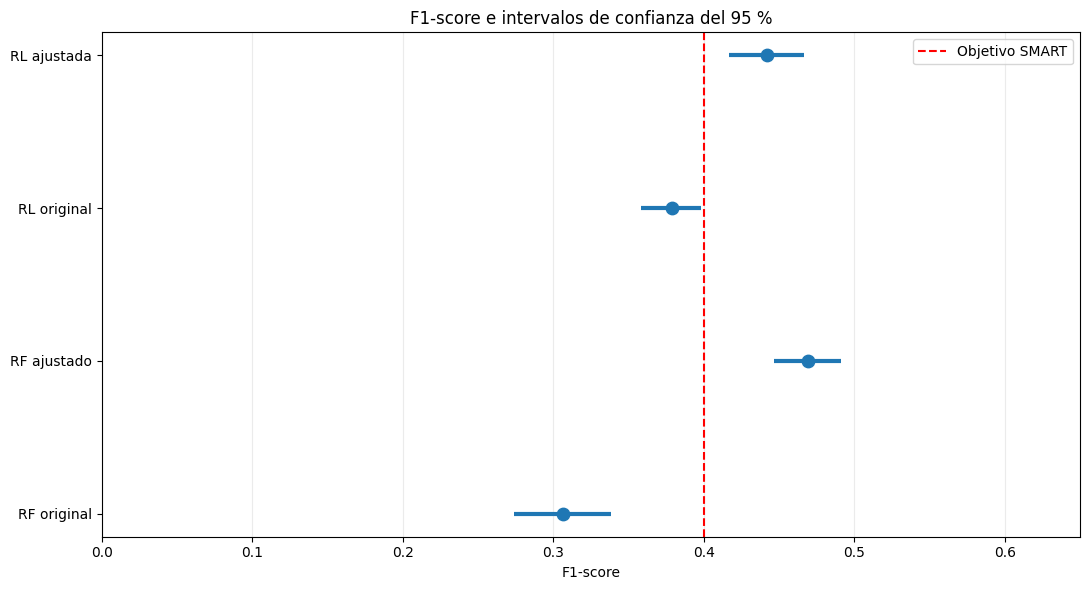

In [49]:
fig, ax = plt.subplots(
    figsize=(11, 6)
)

df_ic_f1 = df_intervalos[
    df_intervalos["metrica"] == "f1"
].copy()

posiciones = np.arange(
    len(df_ic_f1)
)

valores = df_ic_f1[
    "estimacion"
].to_numpy()

limites_inf = df_ic_f1[
    "ic_inferior"
].to_numpy()

limites_sup = df_ic_f1[
    "ic_superior"
].to_numpy()

ax.hlines(
    posiciones,
    limites_inf,
    limites_sup,
    linewidth=3
)

ax.scatter(
    valores,
    posiciones,
    s=80,
    zorder=5
)

ax.set_yticks(posiciones)

ax.set_yticklabels([
    etiquetas.get(n, n)
    for n in df_ic_f1["modelo"]
])

ax.axvline(
    OBJETIVOS["f1_minimo"],
    color="red",
    linestyle="--",
    label="Objetivo SMART"
)

ax.set_title(
    "F1-score e intervalos de confianza del 95 %"
)

ax.set_xlabel("F1-score")

ax.set_xlim(0, 0.65)

ax.grid(axis="x", alpha=0.25)

ax.legend()

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "15_intervalos_confianza_f1.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

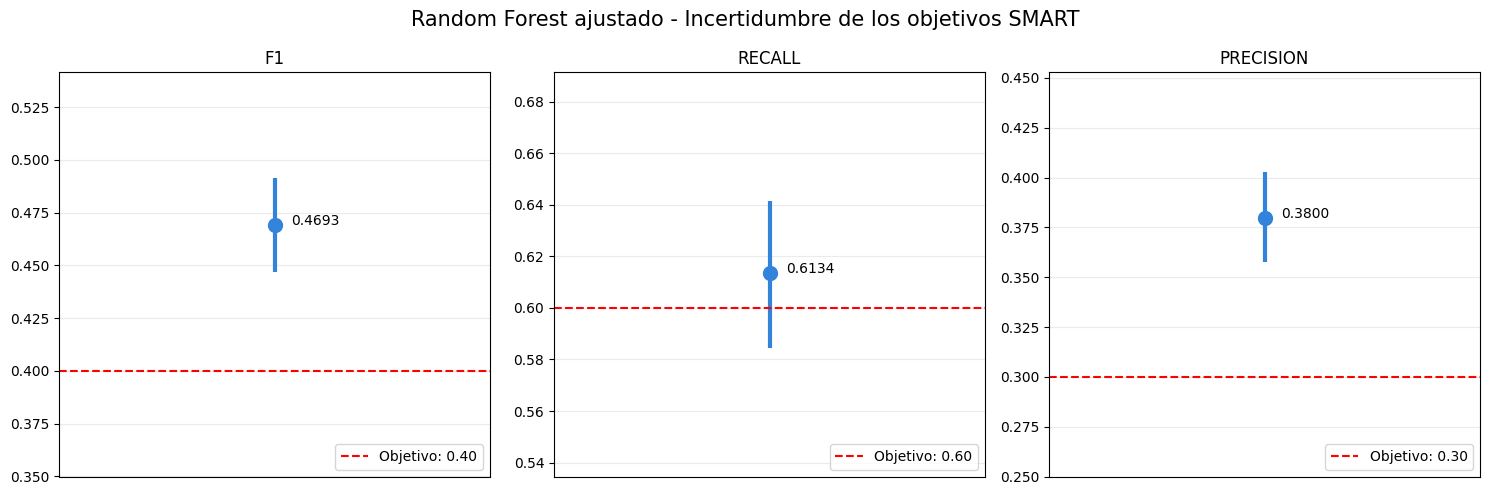

In [50]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

for ax, (_, fila) in zip(
    axes,
    df_smart_ic.iterrows()
):

    valor = fila["estimacion"]

    inferior = fila["ic_inferior"]

    superior = fila["ic_superior"]

    objetivo = fila["objetivo"]

    ax.vlines(
        0,
        inferior,
        superior,
        linewidth=3,
        color="#3383DB"
    )

    ax.scatter(
        0,
        valor,
        s=100,
        color="#3383DB",
        zorder=5
    )

    ax.axhline(
        objetivo,
        color="red",
        linestyle="--",
        label=f"Objetivo: {objetivo:.2f}"
    )

    ax.set_title(
        fila["metrica"].upper()
    )

    ax.set_xticks([])

    ax.set_xlim(-0.5, 0.5)

    ax.set_ylim(
        max(
            0,
            min(inferior, objetivo) - 0.05
        ),
        min(
            1,
            max(superior, objetivo) + 0.05
        )
    )

    ax.annotate(
        f"{valor:.4f}",
        (0, valor),
        xytext=(12, 0),
        textcoords="offset points"
    )

    ax.grid(axis="y", alpha=0.25)

    ax.legend(loc="lower right")

fig.suptitle(
    "Random Forest ajustado - "
    "Incertidumbre de los objetivos SMART",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "16_smart_intervalos_confianza.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

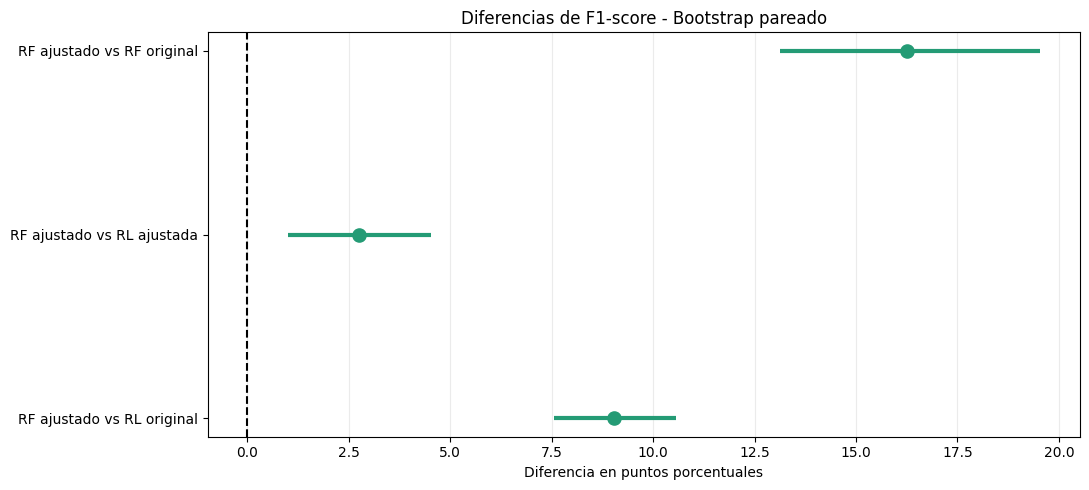

In [51]:
df_diff_f1 = df_diferencias[
    df_diferencias["metrica"] == "f1"
].copy()

fig, ax = plt.subplots(
    figsize=(11, 5)
)

for i, (_, fila) in enumerate(
    df_diff_f1.iterrows()
):

    diferencia = (
        fila["diferencia_observada"] * 100
    )

    inferior = fila["ic_inferior"] * 100

    superior = fila["ic_superior"] * 100

    color = (
        "#249B75"
        if inferior > 0
        else "#D48B30"
    )

    ax.hlines(
        i,
        inferior,
        superior,
        color=color,
        linewidth=3
    )

    ax.scatter(
        diferencia,
        i,
        color=color,
        s=90,
        zorder=5
    )

ax.set_yticks(
    range(len(df_diff_f1))
)

ax.set_yticklabels([
    "RF ajustado vs " +
    etiquetas.get(n, n)
    for n in df_diff_f1["modelo_b"]
])

ax.axvline(
    0,
    color="black",
    linestyle="--"
)

ax.set_title(
    "Diferencias de F1-score - Bootstrap pareado"
)

ax.set_xlabel(
    "Diferencia en puntos porcentuales"
)

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "17_diferencias_estadisticas_f1.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [52]:
fecha = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

ruta_respaldo = Path(
    f"/content/Actividad6_Avance_Etapa07_{fecha}.zip"
)

carpetas_respaldo = [
    "resultados",
    "graficas",
    "documentacion"
]

with zipfile.ZipFile(
    ruta_respaldo,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for carpeta in carpetas_respaldo:

        for archivo in (
            ruta_base / carpeta
        ).rglob("*"):

            if archivo.is_file():

                z.write(
                    archivo,
                    archivo.relative_to(ruta_base)
                )

print("Respaldo generado:", ruta_respaldo.name)

print(
    "Tamaño:",
    round(
        ruta_respaldo.stat().st_size / 1024,
        2
    ),
    "KB"
)

files.download(str(ruta_respaldo))

Respaldo generado: Actividad6_Avance_Etapa07_20261128_081444.zip
Tamaño: 3296.62 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [53]:
columnas_mcnemar = [
    "modelo_a",
    "modelo_b",
    "solo_a_acierta",
    "solo_b_acierta",
    "p_value",
    "p_value_holm",
    "rechaza_h0_holm",
    "diferencia_accuracy"
]

display(
    df_mcnemar[columnas_mcnemar].style.format({
        "p_value": "{:.6e}",
        "p_value_holm": "{:.6e}",
        "diferencia_accuracy": "{:.4%}"
    })
)

,modelo_a,modelo_b,solo_a_acierta,solo_b_acierta,p_value,p_value_holm,rechaza_h0_holm,diferencia_accuracy
0,Random_forest_Ajustado,Regresion_logistica_Original,1012,291,1.467089e-93,4.401266e-93,True,7.9765%
1,Random_forest_Ajustado,Regresion_logistica_Ajustado,258,488,2.875805e-17,2.875805e-17,True,-2.5445%
2,Random_forest_Ajustado,Random_forest_Original,437,946,1.909795e-43,3.819590e-43,True,-5.6312%


## 08. Simulación de prueba A/B y comparación de estrategias comerciales

En esta etapa se realizará una simulación retrospectiva de una prueba A/B para comparar una estrategia de selección aleatoria de clientes con una estrategia de priorización basada en Random Forest.

Los registros del conjunto de prueba se distribuirán aleatoriamente en dos grupos independientes, estableciendo la misma capacidad de contacto comercial para ambas estrategias.

Se analizarán las contrataciones históricas identificadas, las tasas de conversión observadas, la mejora absoluta, el lift y la significancia estadística.

Adicionalmente, se realizarán múltiples simulaciones para analizar la estabilidad de los resultados ante diferentes asignaciones aleatorias.

El ejercicio no constituye una campaña comercial real ni permite establecer una relación causal entre el uso del modelo y el incremento de contrataciones.

In [54]:
from scipy.stats import fisher_exact, norm

CONFIG_AB = {
    "semilla": 42,
    "contactos_por_grupo": 850,
    "numero_simulaciones": 1000,
    "nivel_significancia": 0.05,
    "nivel_confianza": 0.95,
    "modelo": modelo_candidato,
    "umbral_referencia": umbral_candidato,
    "tipo": "Simulacion retrospectiva"
}

df_ab_base = predicciones_finales[
    [
        "id_registro",
        "y_real",
        f"{modelo_candidato}_proba"
    ]
].copy()

df_ab_base = df_ab_base.rename(
    columns={
        f"{modelo_candidato}_proba": "score"
    }
).reset_index(drop=True)

assert len(df_ab_base) == 9039

assert df_ab_base["id_registro"].is_unique

assert df_ab_base["score"].between(0, 1).all()

with open(
    ruta_base / "documentacion" /
    "configuracion_ab.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        CONFIG_AB,
        f,
        indent=4,
        ensure_ascii=False
    )

print("=" * 65)
print("CONFIGURACIÓN DE LA PRUEBA A/B")
print("=" * 65)

for clave, valor in CONFIG_AB.items():
    print(f"{clave}: {valor}")

print("\nRegistros disponibles:", len(df_ab_base))

print("[OK] Configuración preparada")

CONFIGURACIÓN DE LA PRUEBA A/B
semilla: 42
contactos_por_grupo: 850
numero_simulaciones: 1000
nivel_significancia: 0.05
nivel_confianza: 0.95
modelo: Random_forest
umbral_referencia: 0.14
tipo: Simulacion retrospectiva

Registros disponibles: 9039
[OK] Configuración preparada


In [55]:
def simular_ab(datos, semilla, n_contactos):

    rng = np.random.default_rng(semilla)

    # Asignación aleatoria de registros
    indices = rng.permutation(len(datos))

    mitad = len(datos) // 2

    grupo_a = datos.iloc[
        indices[:mitad]
    ].copy()

    grupo_b = datos.iloc[
        indices[mitad:]
    ].copy()

    assert set(
        grupo_a["id_registro"]
    ).isdisjoint(
        grupo_b["id_registro"]
    )

    assert n_contactos <= min(
        len(grupo_a), len(grupo_b)
    )

    # GRUPO A: selección aleatoria

    seleccion_a = grupo_a.iloc[
        rng.choice(
            len(grupo_a),
            size=n_contactos,
            replace=False
        )
    ].copy()

    # GRUPO B: selección por score

    # Desempate aleatorio reproducible
    grupo_b["desempate"] = rng.random(
        len(grupo_b)
    )

    seleccion_b = grupo_b.sort_values(
        ["score", "desempate"],
        ascending=[False, False]
    ).head(n_contactos).copy()

    # Resultados históricos identificados

    exitos_a = int(
        seleccion_a["y_real"].sum()
    )

    exitos_b = int(
        seleccion_b["y_real"].sum()
    )

    tasa_a = exitos_a / n_contactos

    tasa_b = exitos_b / n_contactos

    resultado = {
        "semilla": semilla,

        "poblacion_a": len(grupo_a),
        "poblacion_b": len(grupo_b),

        "prevalencia_a": grupo_a[
            "y_real"
        ].mean(),

        "prevalencia_b": grupo_b[
            "y_real"
        ].mean(),

        "contactos_a": n_contactos,
        "contactos_b": n_contactos,

        "contrataciones_a": exitos_a,
        "contrataciones_b": exitos_b,

        "no_contrataciones_a": (
            n_contactos - exitos_a
        ),

        "no_contrataciones_b": (
            n_contactos - exitos_b
        ),

        "conversion_a": tasa_a,
        "conversion_b": tasa_b,

        "diferencia_conversion": (
            tasa_b - tasa_a
        ),

        "contrataciones_adicionales": (
            exitos_b - exitos_a
        ),

        "lift": (
            tasa_b / tasa_a
            if tasa_a > 0 else np.nan
        ),

        "mejora_relativa": (
            (tasa_b - tasa_a) / tasa_a
            if tasa_a > 0 else np.nan
        ),

        "score_minimo_b": seleccion_b[
            "score"
        ].min()
    }

    seleccion_a["grupo"] = "A_Control"

    seleccion_b["grupo"] = "B_Experimental"

    detalle = pd.concat(
        [seleccion_a, seleccion_b],
        ignore_index=True
    )

    return resultado, detalle


print("[OK] Función de simulación creada")

[OK] Función de simulación creada


In [56]:
resultado_ab, detalle_ab = simular_ab(
    df_ab_base,
    semilla=CONFIG_AB["semilla"],
    n_contactos=CONFIG_AB[
        "contactos_por_grupo"
    ]
)

df_ab = pd.DataFrame(
    [resultado_ab]
)

print("=" * 70)
print("RESULTADOS DE LA SIMULACIÓN A/B")
print("=" * 70)

display(df_ab.T.round(6))

tabla_ab = pd.DataFrame({
    "indicador": [
        "Poblacion asignada",
        "Contactos seleccionados",
        "Contrataciones identificadas",
        "Contactos sin contratacion",
        "Tasa de conversion historica"
    ],

    "Grupo_A": [
        resultado_ab["poblacion_a"],
        resultado_ab["contactos_a"],
        resultado_ab["contrataciones_a"],
        resultado_ab["no_contrataciones_a"],
        resultado_ab["conversion_a"]
    ],

    "Grupo_B": [
        resultado_ab["poblacion_b"],
        resultado_ab["contactos_b"],
        resultado_ab["contrataciones_b"],
        resultado_ab["no_contrataciones_b"],
        resultado_ab["conversion_b"]
    ]
})

display(tabla_ab.round(6))

df_ab.to_csv(
    ruta_base / "resultados" /
    "simulacion_ab_principal.csv",
    index=False
)

detalle_ab.to_csv(
    ruta_base / "resultados" /
    "detalle_clientes_ab.csv",
    index=False
)

print("\n[OK] Resultados A/B guardados")

RESULTADOS DE LA SIMULACIÓN A/B


,0
semilla,42.000000
poblacion_a,4519.000000
poblacion_b,4520.000000
prevalencia_a,0.119053
prevalencia_b,0.115044
contactos_a,850.000000
contactos_b,850.000000
contrataciones_a,87.000000
contrataciones_b,314.000000
no_contrataciones_a,763.000000


,indicador,Grupo_A,Grupo_B
0,Poblacion asignada,4519.000000,4520.000000
1,Contactos seleccionados,850.000000,850.000000
2,Contrataciones identificadas,87.000000,314.000000
3,Contactos sin contratacion,763.000000,536.000000
4,Tasa de conversion historica,0.102353,0.369412



[OK] Resultados A/B guardados


In [57]:
x_a = resultado_ab["contrataciones_a"]
x_b = resultado_ab["contrataciones_b"]

n_a = resultado_ab["contactos_a"]
n_b = resultado_ab["contactos_b"]

p_a = x_a / n_a
p_b = x_b / n_b

diferencia = p_b - p_a

# ==========================================
# PRUEBA DE DOS PROPORCIONES
# ==========================================

p_combinada = (
    (x_a + x_b) / (n_a + n_b)
)

error_h0 = np.sqrt(
    p_combinada *
    (1 - p_combinada) *
    (1 / n_a + 1 / n_b)
)

if error_h0 > 0:

    z = diferencia / error_h0

    p_value_z = 2 * norm.sf(
        abs(z)
    )

else:

    z = 0
    p_value_z = 1.0

# ==========================================
# INTERVALO DE CONFIANZA APROXIMADO
# ==========================================

error_diferencia = np.sqrt(
    p_a * (1 - p_a) / n_a +
    p_b * (1 - p_b) / n_b
)

z_critico = norm.ppf(
    1 - ALPHA / 2
)

ic_inferior = (
    diferencia -
    z_critico * error_diferencia
)

ic_superior = (
    diferencia +
    z_critico * error_diferencia
)

# ==========================================
# PRUEBA EXACTA DE FISHER
# ==========================================

tabla_contingencia = [
    [x_b, n_b - x_b],
    [x_a, n_a - x_a]
]

odds_ratio, p_value_fisher = fisher_exact(
    tabla_contingencia,
    alternative="two-sided"
)

resultado_estadistico_ab = {
    "conversion_a": p_a,
    "conversion_b": p_b,

    "diferencia_conversion": diferencia,

    "ic_inferior": ic_inferior,
    "ic_superior": ic_superior,

    "estadistico_z": z,
    "p_value_z": p_value_z,

    "odds_ratio": odds_ratio,
    "p_value_fisher": p_value_fisher,

    "alpha": ALPHA,

    "rechaza_h0_z": p_value_z < ALPHA,

    "rechaza_h0_fisher": (
        p_value_fisher < ALPHA
    )
}

df_estadistica_ab = pd.DataFrame(
    [resultado_estadistico_ab]
)

print("=" * 70)
print("ANÁLISIS ESTADÍSTICO A/B")
print("=" * 70)

print(f"Conversión histórica A: {p_a:.2%}")
print(f"Conversión histórica B: {p_b:.2%}")

print(
    f"Diferencia: "
    f"{diferencia * 100:.2f} pp"
)

print(
    f"IC 95% aproximado: "
    f"[{ic_inferior:.4f}, "
    f"{ic_superior:.4f}]"
)

print(f"Estadístico Z: {z:.4f}")
print(f"Valor p Z: {p_value_z:.6e}")

print(f"Odds ratio: {odds_ratio:.4f}")
print(f"Valor p Fisher: {p_value_fisher:.6e}")

df_estadistica_ab.to_csv(
    ruta_base / "resultados" /
    "significancia_ab.csv",
    index=False
)

print("\n[OK] Evidencia estadística guardada")

ANÁLISIS ESTADÍSTICO A/B
Conversión histórica A: 10.24%
Conversión histórica B: 36.94%
Diferencia: 26.71 pp
IC 95% aproximado: [0.2287, 0.3054]
Estadístico Z: 12.9680
Valor p Z: 1.857756e-38
Odds ratio: 5.1377
Valor p Fisher: 7.221577e-40

[OK] Evidencia estadística guardada


In [58]:
resultados_ab_repetidos = []

inicio = time.perf_counter()

N_SIMULACIONES = CONFIG_AB[
    "numero_simulaciones"
]

for i in range(N_SIMULACIONES):

    resultado, _ = simular_ab(
        df_ab_base,
        semilla=1000 + i,
        n_contactos=CONFIG_AB[
            "contactos_por_grupo"
        ]
    )

    resultados_ab_repetidos.append(
        resultado
    )

    if (i + 1) % 200 == 0:

        print(
            f"Simulaciones completadas: "
            f"{i + 1}/{N_SIMULACIONES}"
        )

df_ab_repetido = pd.DataFrame(
    resultados_ab_repetidos
)

df_ab_repetido.to_csv(
    ruta_base / "resultados" /
    "simulaciones_ab_repetidas.csv",
    index=False
)

print("\nSimulaciones realizadas:", len(df_ab_repetido))

print(
    "Tiempo total:",
    round(time.perf_counter() - inicio, 2),
    "segundos"
)

display(
    df_ab_repetido[
        [
            "conversion_a",
            "conversion_b",
            "diferencia_conversion",
            "contrataciones_adicionales",
            "lift"
        ]
    ].describe().round(6)
)

print("\n[OK] Simulaciones finalizadas")

Simulaciones completadas: 200/1000
Simulaciones completadas: 400/1000
Simulaciones completadas: 600/1000
Simulaciones completadas: 800/1000
Simulaciones completadas: 1000/1000

Simulaciones realizadas: 1000
Tiempo total: 13.7 segundos


,conversion_a,conversion_b,diferencia_conversion,contrataciones_adicionales,lift
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000
mean,0.117331,0.381387,0.264056,224.44800,3.280466
std,0.010663,0.013185,0.018773,15.95719,0.350133
min,0.087059,0.342353,0.202353,172.00000,2.373016
25%,0.110588,0.372941,0.251765,214.00000,3.037037
50%,0.117647,0.381176,0.263529,224.00000,3.243661
75%,0.124706,0.390588,0.276471,235.00000,3.488760
max,0.148235,0.425882,0.325882,277.00000,4.539474



[OK] Simulaciones finalizadas


In [59]:
metricas_ab = [
    "conversion_a",
    "conversion_b",
    "diferencia_conversion",
    "contrataciones_adicionales",
    "lift"
]

resumen_ab = []

for metrica in metricas_ab:

    valores = df_ab_repetido[metrica]

    resumen_ab.append({
        "metrica": metrica,
        "media": valores.mean(),
        "mediana": valores.median(),
        "desviacion": valores.std(),
        "minimo": valores.min(),
        "maximo": valores.max(),
        "percentil_2_5": valores.quantile(0.025),
        "percentil_97_5": valores.quantile(0.975)
    })

df_resumen_ab = pd.DataFrame(
    resumen_ab
)

proporcion_favorable_b = (
    df_ab_repetido[
        "diferencia_conversion"
    ] > 0
).mean()

print("=" * 70)
print("ESTABILIDAD DE LA SIMULACIÓN A/B")
print("=" * 70)

display(df_resumen_ab.round(6))

print(
    "\nProporción de simulaciones "
    "favorables al grupo B:",
    f"{proporcion_favorable_b:.2%}"
)

df_resumen_ab.to_csv(
    ruta_base / "resultados" /
    "resumen_simulaciones_ab.csv",
    index=False
)

print("\n[OK] Resumen guardado")

ESTABILIDAD DE LA SIMULACIÓN A/B


,metrica,media,mediana,desviacion,minimo,maximo,percentil_2_5,percentil_97_5
0,conversion_a,0.117331,0.117647,0.010663,0.087059,0.148235,0.096471,0.137676
1,conversion_b,0.381387,0.381176,0.013185,0.342353,0.425882,0.355294,0.405882
2,diferencia_conversion,0.264056,0.263529,0.018773,0.202353,0.325882,0.227059,0.300000
3,contrataciones_adicionales,224.448000,224.000000,15.957190,172.000000,277.000000,193.000000,255.000000
4,lift,3.280466,3.243661,0.350133,2.373016,4.539474,2.684651,4.072311



Proporción de simulaciones favorables al grupo B: 100.00%

[OK] Resumen guardado


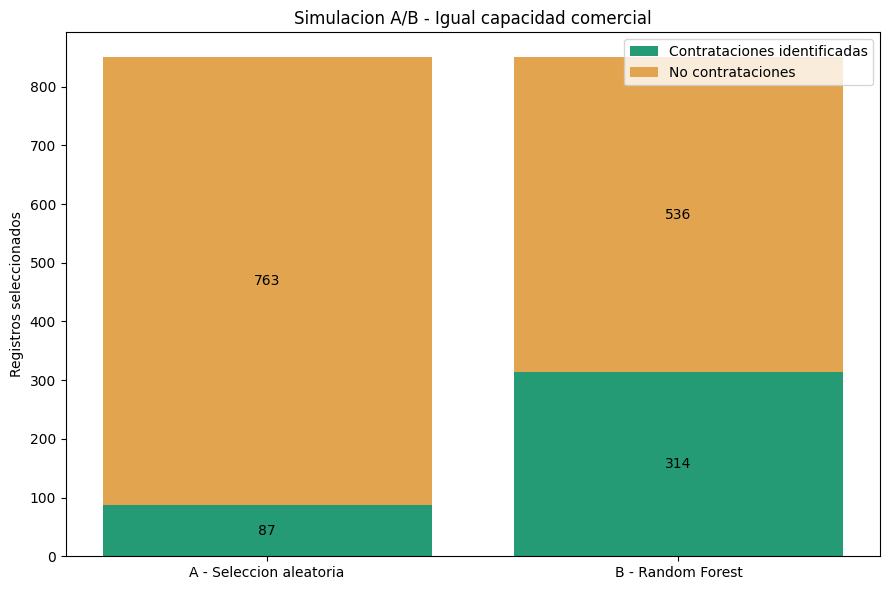

In [60]:
fig, ax = plt.subplots(figsize=(9, 6))

contrataciones = [
    resultado_ab["contrataciones_a"],
    resultado_ab["contrataciones_b"]
]

no_contrataciones = [
    resultado_ab["no_contrataciones_a"],
    resultado_ab["no_contrataciones_b"]
]

grupos = [
    "A - Seleccion aleatoria",
    "B - Random Forest"
]

b1 = ax.bar(
    grupos,
    contrataciones,
    color="#249B75",
    label="Contrataciones identificadas"
)

b2 = ax.bar(
    grupos,
    no_contrataciones,
    bottom=contrataciones,
    color="#E2A44F",
    label="No contrataciones"
)

ax.bar_label(
    b1,
    label_type="center"
)

ax.bar_label(
    b2,
    label_type="center"
)

ax.set_title(
    "Simulacion A/B - Igual capacidad comercial"
)

ax.set_ylabel("Registros seleccionados")

ax.legend()

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "18_resultados_ab.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

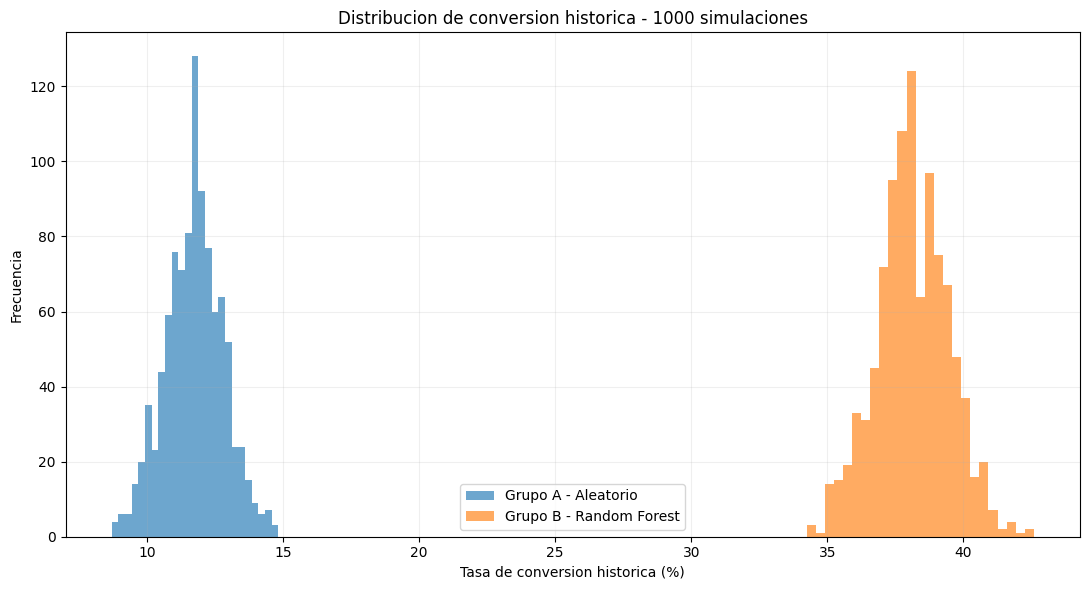

In [61]:
fig, ax = plt.subplots(
    figsize=(11, 6)
)

ax.hist(
    df_ab_repetido["conversion_a"] * 100,
    bins=25,
    alpha=0.65,
    label="Grupo A - Aleatorio"
)

ax.hist(
    df_ab_repetido["conversion_b"] * 100,
    bins=25,
    alpha=0.65,
    label="Grupo B - Random Forest"
)

ax.set_title(
    "Distribucion de conversion historica "
    "- 1000 simulaciones"
)

ax.set_xlabel(
    "Tasa de conversion historica (%)"
)

ax.set_ylabel("Frecuencia")

ax.grid(alpha=0.2)

ax.legend()

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "19_distribucion_simulaciones_ab.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

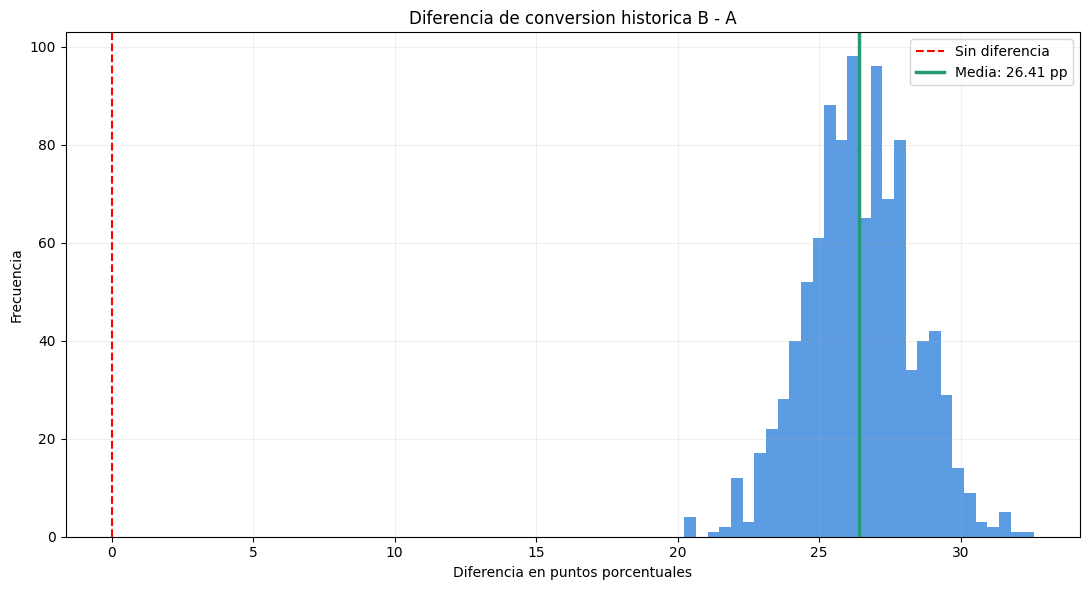

[OK] Tres graficas A/B generadas


In [62]:
diferencias_pp = (
    df_ab_repetido[
        "diferencia_conversion"
    ] * 100
)

fig, ax = plt.subplots(
    figsize=(11, 6)
)

ax.hist(
    diferencias_pp,
    bins=30,
    color="#3383DB",
    alpha=0.8
)

ax.axvline(
    0,
    color="red",
    linestyle="--",
    label="Sin diferencia"
)

ax.axvline(
    diferencias_pp.mean(),
    color="#249B75",
    linewidth=2.5,
    label=(
        f"Media: "
        f"{diferencias_pp.mean():.2f} pp"
    )
)

ax.set_title(
    "Diferencia de conversion historica B - A"
)

ax.set_xlabel(
    "Diferencia en puntos porcentuales"
)

ax.set_ylabel("Frecuencia")

ax.grid(alpha=0.2)

ax.legend()

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "20_diferencias_conversion_ab.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("[OK] Tres graficas A/B generadas")

In [63]:
fecha = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

ruta_respaldo = Path(
    f"/content/Actividad6_Avance_Etapa08_{fecha}.zip"
)

carpetas_respaldo = [
    "resultados",
    "graficas",
    "documentacion"
]

with zipfile.ZipFile(
    ruta_respaldo,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for carpeta in carpetas_respaldo:

        for archivo in (
            ruta_base / carpeta
        ).rglob("*"):

            if archivo.is_file():

                z.write(
                    archivo,
                    archivo.relative_to(ruta_base)
                )

print("Respaldo generado:", ruta_respaldo.name)

print(
    "Tamaño:",
    round(
        ruta_respaldo.stat().st_size / 1024,
        2
    ),
    "KB"
)

files.download(str(ruta_respaldo))

Respaldo generado: Actividad6_Avance_Etapa08_20261128_082159.zip
Tamaño: 3524.54 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 09. Evaluación del impacto económico y comercial

En esta etapa se analizará la conveniencia económica potencial de los modelos evaluados mediante dos escenarios.

El primero compara Random Forest ajustado con la regresión logística original, considerando la reducción del volumen de contactos y las oportunidades comerciales identificadas.

El segundo compara las estrategias de la simulación A/B, manteniendo la misma capacidad comercial.

Se utilizarán supuestos económicos hipotéticos y se realizará un análisis de sensibilidad para determinar cómo cambia la conveniencia de cada estrategia ante diferentes costos de contacto y márgenes por contratación.

Los resultados no representan información financiera real del banco ni constituyen una estimación de rentabilidad comprobada mediante una campaña comercial.

In [64]:
CONFIG_ECONOMICA = {
    "moneda": "MXN",
    "costo_contacto": 10.0,
    "margen_contratacion": 300.0,
    "tipo_datos": "Supuestos academicos",
    "costos_implementacion_ia_incluidos": False,
    "impacto_causal_demostrado": False
}

with open(
    ruta_base / "documentacion" /
    "configuracion_economica.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        CONFIG_ECONOMICA,
        f,
        indent=4,
        ensure_ascii=False
    )

print("=" * 65)
print("CONFIGURACIÓN ECONÓMICA")
print("=" * 65)

for clave, valor in CONFIG_ECONOMICA.items():
    print(f"{clave}: {valor}")

print("\n[OK] Supuestos económicos registrados")

CONFIGURACIÓN ECONÓMICA
moneda: MXN
costo_contacto: 10.0
margen_contratacion: 300.0
tipo_datos: Supuestos academicos
costos_implementacion_ia_incluidos: False
impacto_causal_demostrado: False

[OK] Supuestos económicos registrados


In [65]:
def evaluar_economia(
    estrategia,
    contactos,
    contrataciones,
    costo_contacto,
    margen_contratacion
):

    costo_total = contactos * costo_contacto

    margen_total = (
        contrataciones * margen_contratacion
    )

    beneficio = margen_total - costo_total

    return {
        "estrategia": estrategia,

        "contactos": int(contactos),

        "contrataciones_identificadas": int(
            contrataciones
        ),

        "contactos_sin_contratacion": int(
            contactos - contrataciones
        ),

        "costo_contacto": costo_contacto,

        "margen_contratacion": margen_contratacion,

        "costo_total_contactos": costo_total,

        "margen_total_simulado": margen_total,

        "beneficio_neto_simulado": beneficio,

        "costo_por_contratacion_identificada": (
            costo_total / contrataciones
            if contrataciones > 0
            else np.nan
        ),

        "roi_sobre_contactos_pct": (
            100 * beneficio / costo_total
            if costo_total > 0
            else np.nan
        )
    }


print("[OK] Función económica creada")

[OK] Función económica creada


In [66]:
costo = CONFIG_ECONOMICA["costo_contacto"]

margen = CONFIG_ECONOMICA[
    "margen_contratacion"
]

resultados_economicos = []

for _, fila in df_comparacion_final.iterrows():

    resultado = evaluar_economia(
        estrategia=fila["modelo"],

        contactos=fila[
            "clientes_seleccionados"
        ],

        contrataciones=fila["VP"],

        costo_contacto=costo,

        margen_contratacion=margen
    )

    resultados_economicos.append(resultado)

df_economia = pd.DataFrame(
    resultados_economicos
)

df_economia = df_economia.sort_values(
    "beneficio_neto_simulado",
    ascending=False
).reset_index(drop=True)

print("=" * 70)
print("COMPARACIÓN ECONÓMICA DE ESTRATEGIAS")
print("=" * 70)

display(
    df_economia[
        [
            "estrategia",
            "contactos",
            "contrataciones_identificadas",
            "costo_total_contactos",
            "margen_total_simulado",
            "beneficio_neto_simulado",
            "costo_por_contratacion_identificada",
            "roi_sobre_contactos_pct"
        ]
    ].round(2)
)

df_economia.to_csv(
    ruta_base / "resultados" /
    "evaluacion_economica_modelos.csv",
    index=False
)

print("\n[OK] Evaluación económica guardada")

COMPARACIÓN ECONÓMICA DE ESTRATEGIAS


,estrategia,contactos,contrataciones_identificadas,costo_total_contactos,margen_total_simulado,beneficio_neto_simulado,costo_por_contratacion_identificada,roi_sobre_contactos_pct
0,Baseline_contactar_todos,9039,1058,90390.0,317400.0,227010.0,85.43,251.15
1,Random_forest_Ajustado,1708,649,17080.0,194700.0,177620.0,26.32,1039.93
2,Regresion_logistica_Original,2467,668,24670.0,200400.0,175730.0,36.93,712.32
3,Regresion_logistica_Ajustado,1160,490,11600.0,147000.0,135400.0,23.67,1167.24
4,Baseline_aleatorio,2467,303,24670.0,90900.0,66230.0,81.42,268.46
5,Random_forest_Original,325,212,3250.0,63600.0,60350.0,15.33,1856.92
6,Baseline_mayoritario,0,0,0.0,0.0,0.0,NaN,NaN



[OK] Evaluación económica guardada


In [67]:
economia_idx = df_economia.set_index(
    "estrategia"
)

eco_rl = economia_idx.loc[
    "Regresion_logistica_Original"
]

eco_rf = economia_idx.loc[
    "Random_forest_Ajustado"
]

contactos_evitados = int(
    eco_rl["contactos"] -
    eco_rf["contactos"]
)

contrataciones_menos = int(
    eco_rl["contrataciones_identificadas"] -
    eco_rf["contrataciones_identificadas"]
)

ahorro_contactos = (
    contactos_evitados * costo
)

margen_no_identificado = (
    contrataciones_menos * margen
)

ventaja_economica_rf = (
    ahorro_contactos -
    margen_no_identificado
)

costo_equilibrio = (
    contrataciones_menos * margen /
    contactos_evitados
    if contactos_evitados > 0
    else np.nan
)

margen_equilibrio = (
    contactos_evitados * costo /
    contrataciones_menos
    if contrataciones_menos > 0
    else np.nan
)

resultado_equilibrio = {
    "contactos_evitados": contactos_evitados,

    "contrataciones_menos": contrataciones_menos,

    "ahorro_contactos": ahorro_contactos,

    "margen_no_identificado": margen_no_identificado,

    "ventaja_economica_rf": ventaja_economica_rf,

    "costo_contacto_equilibrio": costo_equilibrio,

    "margen_contratacion_equilibrio": margen_equilibrio
}

df_equilibrio = pd.DataFrame(
    [resultado_equilibrio]
)

print("=" * 70)
print("PUNTO DE EQUILIBRIO ECONÓMICO")
print("=" * 70)

display(df_equilibrio.T.round(4))

df_equilibrio.to_csv(
    ruta_base / "resultados" /
    "punto_equilibrio_economico.csv",
    index=False
)

print("\n[OK] Punto de equilibrio calculado")

PUNTO DE EQUILIBRIO ECONÓMICO


,0
contactos_evitados,759.0000
contrataciones_menos,19.0000
ahorro_contactos,7590.0000
margen_no_identificado,5700.0000
ventaja_economica_rf,1890.0000
costo_contacto_equilibrio,7.5099
margen_contratacion_equilibrio,399.4737



[OK] Punto de equilibrio calculado


In [68]:
economia_ab = []

economia_ab.append(
    evaluar_economia(
        estrategia="A_Seleccion_aleatoria",

        contactos=resultado_ab["contactos_a"],

        contrataciones=resultado_ab[
            "contrataciones_a"
        ],

        costo_contacto=costo,

        margen_contratacion=margen
    )
)

economia_ab.append(
    evaluar_economia(
        estrategia="B_Random_Forest",

        contactos=resultado_ab["contactos_b"],

        contrataciones=resultado_ab[
            "contrataciones_b"
        ],

        costo_contacto=costo,

        margen_contratacion=margen
    )
)

df_economia_ab = pd.DataFrame(
    economia_ab
)

ventaja_ab = (
    df_economia_ab.iloc[1][
        "beneficio_neto_simulado"
    ] -
    df_economia_ab.iloc[0][
        "beneficio_neto_simulado"
    ]
)

print("=" * 70)
print("IMPACTO ECONÓMICO SIMULADO A/B")
print("=" * 70)

display(df_economia_ab.T.round(2))

print(
    f"\nVentaja económica simulada: "
    f"${ventaja_ab:,.2f} MXN"
)

df_economia_ab.to_csv(
    ruta_base / "resultados" /
    "evaluacion_economica_ab.csv",
    index=False
)

print("\n[OK] Evaluación económica A/B guardada")

IMPACTO ECONÓMICO SIMULADO A/B


,0,1
estrategia,A_Seleccion_aleatoria,B_Random_Forest
contactos,850,850
contrataciones_identificadas,87,314
contactos_sin_contratacion,763,536
costo_contacto,10.0,10.0
margen_contratacion,300.0,300.0
costo_total_contactos,8500.0,8500.0
margen_total_simulado,26100.0,94200.0
beneficio_neto_simulado,17600.0,85700.0
costo_por_contratacion_identificada,97.701149,27.070064



Ventaja económica simulada: $68,100.00 MXN

[OK] Evaluación económica A/B guardada


In [69]:
costos_contacto = [
    1, 5, 10, 15, 20, 30, 50
]

margenes_contratacion = [
    50, 100, 200, 300, 500, 750, 1000
]

resultados_sensibilidad = []

for c in costos_contacto:

    for m in margenes_contratacion:

        beneficio_rl = (
            eco_rl["contrataciones_identificadas"] * m -
            eco_rl["contactos"] * c
        )

        beneficio_rf = (
            eco_rf["contrataciones_identificadas"] * m -
            eco_rf["contactos"] * c
        )

        diferencia = (
            beneficio_rf - beneficio_rl
        )

        if diferencia > 0:

            preferido = "Random Forest"

        elif diferencia < 0:

            preferido = "Regresion logistica"

        else:

            preferido = "Equivalentes"

        resultados_sensibilidad.append({
            "costo_contacto": c,

            "margen_contratacion": m,

            "beneficio_rl": beneficio_rl,

            "beneficio_rf": beneficio_rf,

            "ventaja_rf": diferencia,

            "modelo_preferido": preferido
        })

df_sensibilidad = pd.DataFrame(
    resultados_sensibilidad
)

print("=" * 70)
print("ANÁLISIS DE SENSIBILIDAD ECONÓMICA")
print("=" * 70)

print(
    "Escenarios evaluados:",
    len(df_sensibilidad)
)

display(
    df_sensibilidad[
        "modelo_preferido"
    ].value_counts()
)

display(df_sensibilidad.round(2))

df_sensibilidad.to_csv(
    ruta_base / "resultados" /
    "sensibilidad_economica.csv",
    index=False
)

print("\n[OK] Análisis de sensibilidad guardado")

ANÁLISIS DE SENSIBILIDAD ECONÓMICA
Escenarios evaluados: 49


,count
modelo_preferido,
Random Forest,31
Regresion logistica,18


,costo_contacto,margen_contratacion,beneficio_rl,beneficio_rf,ventaja_rf,modelo_preferido
0,1,50,30933.0,30742.0,-191.0,Regresion logistica
1,1,100,64333.0,63192.0,-1141.0,Regresion logistica
2,1,200,131133.0,128092.0,-3041.0,Regresion logistica
3,1,300,197933.0,192992.0,-4941.0,Regresion logistica
4,1,500,331533.0,322792.0,-8741.0,Regresion logistica
5,1,750,498533.0,485042.0,-13491.0,Regresion logistica
6,1,1000,665533.0,647292.0,-18241.0,Regresion logistica
7,5,50,21065.0,23910.0,2845.0,Random Forest
8,5,100,54465.0,56360.0,1895.0,Random Forest
9,5,200,121265.0,121260.0,-5.0,Regresion logistica



[OK] Análisis de sensibilidad guardado


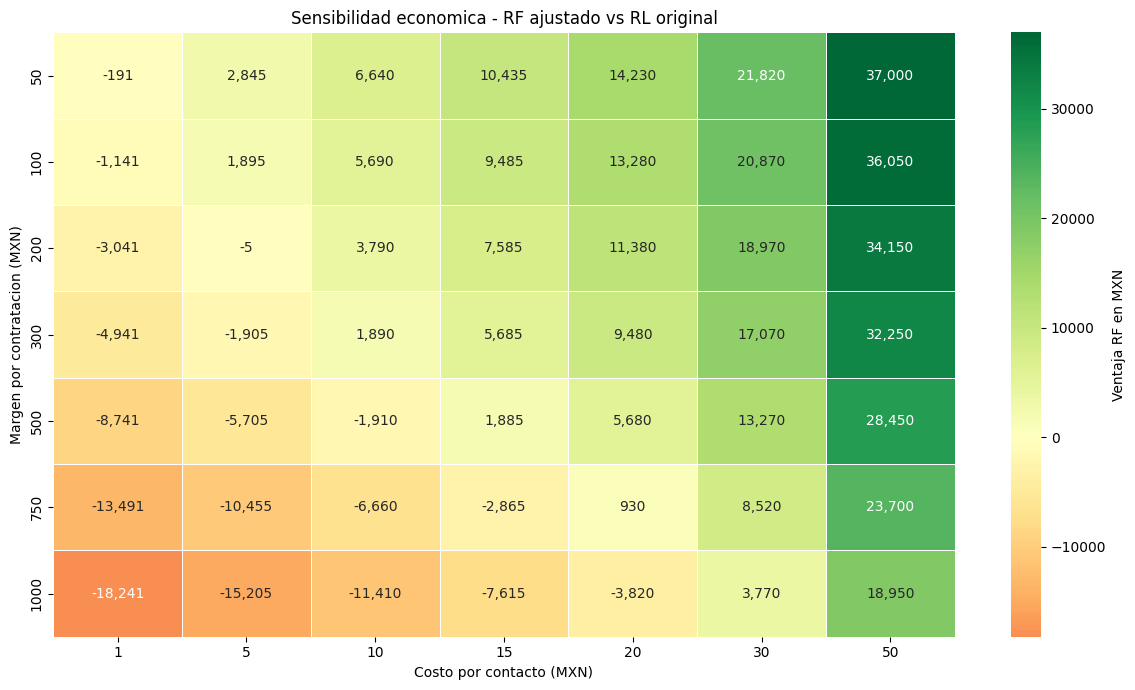

In [70]:
matriz_sensibilidad = (
    df_sensibilidad.pivot(
        index="margen_contratacion",
        columns="costo_contacto",
        values="ventaja_rf"
    )
)

fig, ax = plt.subplots(
    figsize=(12, 7)
)

sns.heatmap(
    matriz_sensibilidad,

    annot=True,

    fmt=",.0f",

    cmap="RdYlGn",

    center=0,

    linewidths=0.5,

    cbar_kws={
        "label": "Ventaja RF en MXN"
    },

    ax=ax
)

ax.set_title(
    "Sensibilidad economica - "
    "RF ajustado vs RL original"
)

ax.set_xlabel(
    "Costo por contacto (MXN)"
)

ax.set_ylabel(
    "Margen por contratacion (MXN)"
)

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "21_sensibilidad_economica.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

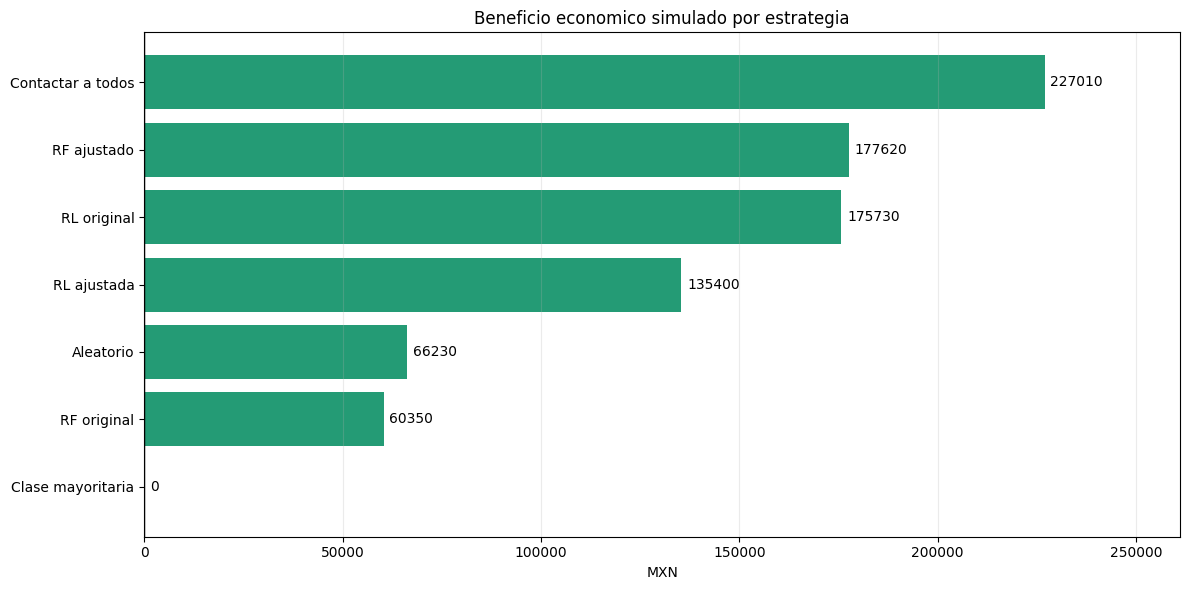

In [71]:
df_eco_grafica = df_economia.copy()

df_eco_grafica["nombre"] = (
    df_eco_grafica["estrategia"]
    .map(etiquetas)
    .fillna(df_eco_grafica["estrategia"])
)

fig, ax = plt.subplots(
    figsize=(12, 6)
)

barras = ax.barh(
    df_eco_grafica["nombre"],

    df_eco_grafica[
        "beneficio_neto_simulado"
    ],

    color=[
        "#249B75" if v >= 0
        else "#C34D4D"

        for v in df_eco_grafica[
            "beneficio_neto_simulado"
        ]
    ]
)

ax.bar_label(
    barras,
    fmt="%.0f",
    padding=4
)

ax.invert_yaxis()

ax.axvline(
    0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Beneficio economico simulado por estrategia"
)

ax.set_xlabel("MXN")

ax.grid(axis="x", alpha=0.25)

ax.margins(x=0.15)

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "22_comparacion_economica_modelos.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

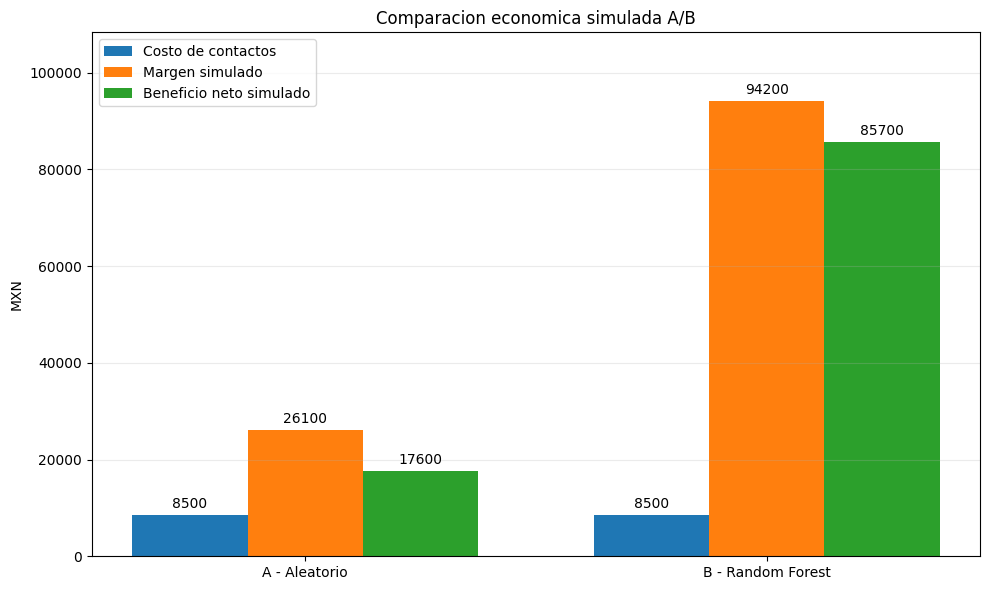

[OK] Gráficas económicas generadas


In [72]:
fig, ax = plt.subplots(
    figsize=(10, 6)
)

x = np.arange(2)

ancho = 0.25

columnas = [
    "costo_total_contactos",
    "margen_total_simulado",
    "beneficio_neto_simulado"
]

nombres = [
    "Costo de contactos",
    "Margen simulado",
    "Beneficio neto simulado"
]

for i, (columna, nombre) in enumerate(
    zip(columnas, nombres)
):

    barras = ax.bar(
        x + (i - 1) * ancho,

        df_economia_ab[columna],

        ancho,

        label=nombre
    )

    ax.bar_label(
        barras,
        fmt="%.0f",
        padding=3
    )

ax.set_xticks(x)

ax.set_xticklabels([
    "A - Aleatorio",
    "B - Random Forest"
])

ax.set_title(
    "Comparacion economica simulada A/B"
)

ax.set_ylabel("MXN")

ax.legend()

ax.grid(axis="y", alpha=0.25)

ax.margins(y=0.15)

plt.tight_layout()

plt.savefig(
    ruta_base / "graficas" /
    "23_impacto_economico_ab.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("[OK] Gráficas económicas generadas")

In [73]:
recomendacion = {
    "modelo_recomendado": modelo_candidato,

    "umbral": float(umbral_candidato),

    "criterio_principal": "F1-score",

    "f1_prueba": float(
        candidato_prueba["f1"]
    ),

    "precision_prueba": float(
        candidato_prueba["precision"]
    ),

    "recall_prueba": float(
        candidato_prueba["recall"]
    ),

    "roc_auc_prueba": float(
        candidato_prueba["roc_auc"]
    ),

    "cumple_smart_puntual": bool(
        cumplimiento_total
    ),

    "todos_limites_inferiores_cumplen_smart": bool(
        df_smart_ic[
            "limite_inferior_cumple"
        ].all()
    ),

    "lift_ab_principal": float(
        resultado_ab["lift"]
    ),

    "lift_ab_promedio": float(
        df_ab_repetido["lift"].mean()
    ),

    "proporcion_simulaciones_favorables": float(
        proporcion_favorable_b
    ),

    "ventaja_economica_vs_rl": float(
        ventaja_economica_rf
    ),

    "ventaja_economica_ab": float(
        ventaja_ab
    ),

    "supuestos_economicos": CONFIG_ECONOMICA,

    "estado_recomendacion": (
        "Candidato para validacion adicional "
        "y eventual piloto controlado"
    ),

    "aprobado_para_produccion": False,

    "limitaciones": [
        "Datos historicos de una entidad extranjera",

        "Conjunto de prueba utilizado anteriormente",

        "Indicios de sobreajuste en Random Forest",

        "Intervalo de confianza del recall "
        "incluye valores inferiores al objetivo",

        "Prueba A/B retrospectiva sin evidencia causal",

        "Supuestos economicos hipoteticos",

        "Costos completos de implementacion no incluidos",

        "Pendiente validacion externa y de riesgos"
    ]
}

with open(
    ruta_base / "documentacion" /
    "recomendacion_modelo.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        recomendacion,
        f,
        indent=4,
        ensure_ascii=False
    )

print("=" * 70)
print("RECOMENDACIÓN PRELIMINAR DEL MODELO")
print("=" * 70)

print(
    json.dumps(
        recomendacion,
        indent=4,
        ensure_ascii=False
    )
)

print("\n[OK] Recomendación documentada")

RECOMENDACIÓN PRELIMINAR DEL MODELO
{
    "modelo_recomendado": "Random_forest",
    "umbral": 0.14,
    "criterio_principal": "F1-score",
    "f1_prueba": 0.4692697035430224,
    "precision_prueba": 0.3799765807962529,
    "recall_prueba": 0.6134215500945179,
    "roc_auc_prueba": 0.8033047059545247,
    "cumple_smart_puntual": true,
    "todos_limites_inferiores_cumplen_smart": false,
    "lift_ab_principal": 3.6091954022988504,
    "lift_ab_promedio": 3.2804658994170914,
    "proporcion_simulaciones_favorables": 1.0,
    "ventaja_economica_vs_rl": 1890.0,
    "ventaja_economica_ab": 68100.0,
    "supuestos_economicos": {
        "moneda": "MXN",
        "costo_contacto": 10.0,
        "margen_contratacion": 300.0,
        "tipo_datos": "Supuestos academicos",
        "costos_implementacion_ia_incluidos": false,
        "impacto_causal_demostrado": false
    },
    "estado_recomendacion": "Candidato para validacion adicional y eventual piloto controlado",
    "aprobado_para_produccio

In [74]:
fecha = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

ruta_respaldo = Path(
    f"/content/Actividad6_Avance_Etapa09_{fecha}.zip"
)

carpetas_respaldo = [
    "resultados",
    "graficas",
    "documentacion"
]

with zipfile.ZipFile(
    ruta_respaldo,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for carpeta in carpetas_respaldo:

        for archivo in (
            ruta_base / carpeta
        ).rglob("*"):

            if archivo.is_file():

                z.write(
                    archivo,
                    archivo.relative_to(ruta_base)
                )

print("Respaldo generado:", ruta_respaldo.name)

print(
    "Tamaño:",
    round(
        ruta_respaldo.stat().st_size / 1024,
        2
    ),
    "KB"
)

files.download(str(ruta_respaldo))

Respaldo generado: Actividad6_Avance_Etapa09_20261128_083123.zip
Tamaño: 3823.09 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Registro de experimentos y trazabilidad mediante MLflow

Una vez concluidos los experimentos de evaluación y validación, se utilizará MLflow para organizar y conservar los resultados obtenidos durante la Actividad 6.

Se registrarán las métricas, parámetros, umbrales de decisión, resultados de validación cruzada, pruebas estadísticas, simulaciones A/B, análisis económico y recomendación del modelo.

Se utilizará una base de datos independiente de la Actividad 5, evitando modificar los registros históricos.

Los resultados se recuperarán mediante la API de MLflow para comprobar la disponibilidad de las métricas y los artefactos registrados.

El propósito de esta etapa es fortalecer la trazabilidad, reproducibilidad y gobernanza del proyecto, incorporando prácticas de MLOps.

In [75]:
%pip install -q "mlflow==3.18.0" "scikit-learn==1.6.1" "numpy==2.4.6" "pandas==2.2.3" "scipy==1.16.3" "cloudpickle==3.1.2"

In [76]:
import mlflow
import mlflow.sklearn

from importlib.metadata import version

print("=" * 65)
print("VERIFICACIÓN DEL ENTORNO MLFLOW")
print("=" * 65)

versiones_esperadas = {
    "mlflow": "3.18.0",
    "scikit-learn": "1.6.1",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "cloudpickle": "3.1.2"
}

for biblioteca, esperada in (
    versiones_esperadas.items()
):

    actual = version(biblioteca)

    print(
        f"{biblioteca:20} "
        f"{actual:12} "
        f"Esperada: {esperada}"
    )

    assert actual == esperada

# Comprobar que conservamos las variables
# de las etapas anteriores

assert len(df_final) == 4
assert len(df_umbrales) == 198
assert len(df_bootstrap) == 8000
assert len(df_ab_repetido) == 1000
assert len(df_sensibilidad) == 49

print("\n[OK] Entorno compatible")

print("[OK] Resultados anteriores disponibles")

VERIFICACIÓN DEL ENTORNO MLFLOW
mlflow               3.18.0       Esperada: 3.18.0
scikit-learn         1.6.1        Esperada: 1.6.1
numpy                2.4.6        Esperada: 2.4.6
pandas               2.2.3        Esperada: 2.2.3
scipy                1.16.3       Esperada: 1.16.3
cloudpickle          3.1.2        Esperada: 3.1.2

[OK] Entorno compatible
[OK] Resultados anteriores disponibles


In [77]:
from mlflow.tracking import MlflowClient

ruta_mlflow = (
    ruta_base / "evidencias_mlflow"
)

ruta_mlflow.mkdir(
    parents=True,
    exist_ok=True
)

ruta_db = ruta_mlflow / "mlflow.db"

ruta_artefactos = (
    ruta_mlflow / "mlruns"
)

ruta_artefactos.mkdir(
    parents=True,
    exist_ok=True
)

# Configurar almacenamiento local

mlflow.set_tracking_uri(
    f"sqlite:///{ruta_db}"
)

client = MlflowClient()

NOMBRE_EXPERIMENTO = (
    "Actividad6_Banca_Evaluacion_Validacion"
)

experimento = client.get_experiment_by_name(
    NOMBRE_EXPERIMENTO
)

if experimento is None:

    experiment_id = client.create_experiment(
        NOMBRE_EXPERIMENTO,

        artifact_location=(
            ruta_artefactos.as_uri()
        )
    )

else:

    experiment_id = experimento.experiment_id

mlflow.set_experiment(
    experiment_id=experiment_id
)

# Identificador de esta sesión de registro

LOTE_REGISTRO = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S%fZ")

print("=" * 65)
print("CONFIGURACIÓN MLFLOW")
print("=" * 65)

print("Experimento:", NOMBRE_EXPERIMENTO)
print("Experiment ID:", experiment_id)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Artefactos:", ruta_artefactos)
print("Lote de registro:", LOTE_REGISTRO)

print("\n[OK] Experimento preparado")

2026/11/28 08:36:32 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/28 08:36:32 INFO mlflow.store.db.utils: Updating database tables


CONFIGURACIÓN MLFLOW
Experimento: Actividad6_Banca_Evaluacion_Validacion
Experiment ID: 1
Tracking URI: sqlite:////content/Actividad6/evidencias_mlflow/mlflow.db
Artefactos: /content/Actividad6/evidencias_mlflow/mlruns
Lote de registro: 20261128T083638682357Z

[OK] Experimento preparado


In [78]:
runs_registrados = []

def registrar_experimento(
    nombre_run,
    parametros=None,
    metricas=None,
    archivos=None,
    etiquetas_run=None
):

    with mlflow.start_run(
        run_name=nombre_run,
        experiment_id=experiment_id
    ) as run:

        mlflow.set_tags({
            "actividad": "6",
            "proyecto": "Contratacion_depositos",
            "dataset": "UCI_Bank_Marketing",
            "lote_registro": LOTE_REGISTRO,
            "tipo_registro": "Retrospectivo",
            "nuevo_entrenamiento": "False"
        })

        if etiquetas_run:

            mlflow.set_tags(
                etiquetas_run
            )

        if parametros:

            mlflow.log_params({
                k: str(v)
                for k, v in parametros.items()
            })

        if metricas:

            metricas_validas = {
                k: float(v)
                for k, v in metricas.items()
                if v is not None
                and np.isfinite(float(v))
            }

            mlflow.log_metrics(
                metricas_validas
            )

        if archivos:

            for archivo in archivos:

                archivo = Path(archivo)

                assert archivo.is_file(), (
                    f"Archivo no encontrado: {archivo}"
                )

                mlflow.log_artifact(
                    str(archivo),

                    artifact_path=(
                        archivo.parent.name
                    )
                )

        run_id = run.info.run_id

    runs_registrados.append({
        "nombre_run": nombre_run,
        "run_id": run_id
    })

    print(
        "[OK]",
        nombre_run,
        "|",
        run_id
    )

    return run_id


print("Función de registro preparada")

Función de registro preparada


In [79]:
R = ruta_base / "resultados"
G = ruta_base / "graficas"
D = ruta_base / "documentacion"

# ==========================================
# REPRODUCIBILIDAD
# ==========================================

registrar_experimento(

    nombre_run="01_Reproducibilidad_Act5",

    parametros={
        "semilla": SEED,
        "test_size": 0.20,
        "modelos_recuperados": 2
    },

    metricas={
        "registros_prueba": len(y_test),

        "metricas_comparadas": len(
            df_reproducibilidad
        ),

        "metricas_coincidentes": (
            df_reproducibilidad[
                "coincide"
            ].sum()
        )
    },

    archivos=[
        R / "metricas_originales.csv",
        R / "reproducibilidad.csv"
    ]
)

# ==========================================
# BASELINES
# ==========================================

metricas_registro = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "especificidad",
    "clientes_seleccionados",
    "VP",
    "FP",
    "FN",
    "VN"
]

for _, fila in df_baselines.iterrows():

    registrar_experimento(

        nombre_run=(
            "02_" + fila["modelo"]
        ),

        parametros={
            "estrategia": fila["modelo"],
            "semilla": SEED
        },

        metricas={
            k: fila[k]
            for k in metricas_registro
        },

        archivos=[
            R / "metricas_baseline.csv",
            G / "01_comparacion_metricas.png",
            G / "02_indicadores_comerciales.png"
        ]
    )

print("\nRuns registrados:", len(runs_registrados))

[OK] 01_Reproducibilidad_Act5 | 90fb2ff6b6564560872964c35608e9ae
[OK] 02_Baseline_mayoritario | 157f24ab31a7438f9a8ac38e0cfbdf4c
[OK] 02_Baseline_aleatorio | d240e7701c224634824b0211a73136de
[OK] 02_Baseline_contactar_todos | e028a76ea26e40ba8bce02cf0eb83af4

Runs registrados: 4


In [80]:
for _, fila in df_resumen_cv.iterrows():

    nombre = fila["modelo"]

    registrar_experimento(

        nombre_run=f"03_CV_{nombre}",

        parametros={
            "modelo": nombre,
            "folds": 5,
            "semilla": SEED,
            "estratificada": True,
            "entrenamientos_historicos": 5,
            "registros_oof": len(
                predicciones_oof
            )
        },

        metricas={
            "f1_mean": fila["f1_mean"],
            "f1_std": fila["f1_std"],
            "recall_mean": fila["recall_mean"],
            "roc_auc_mean": fila["roc_auc_mean"],

            "f1_entrenamiento_mean": (
                fila["f1_entrenamiento_mean"]
            ),

            "brecha_f1_mean": (
                fila["brecha_f1_mean"]
            )
        },

        archivos=[
            R / "validacion_cruzada.csv",
            R / "resumen_validacion_cruzada.csv",
            R / "configuracion_folds.csv",
            G / "04_f1_validacion_cruzada.png",
            G / "05_entrenamiento_vs_validacion.png",
            G / "06_estabilidad_modelos.png"
        ]
    )


for nombre, seleccion in (
    umbrales_seleccionados.items()
):

    registrar_experimento(

        nombre_run=f"04_Umbrales_{nombre}",

        parametros={
            "modelo": nombre,
            "umbral_original": 0.50,
            "umbral_seleccionado": (
                seleccion["umbral"]
            ),
            "umbrales_evaluados": 99,
            "fuente": "OOF",
            "criterio": seleccion["criterio"]
        },

        metricas={
            "f1_oof": seleccion["f1_oof"],
            "recall_oof": seleccion["recall_oof"],
            "precision_oof": (
                seleccion["precision_oof"]
            ),
            "cumple_smart": int(
                seleccion["cumple_smart_oof"]
            )
        },

        archivos=[
            R / "evaluacion_umbrales_oof.csv",
            R / "comparacion_umbrales_oof.csv",
            R / "modelos_candidatos_oof.csv",
            D / "seleccion_umbrales.json",
            G / "09_comparacion_f1_umbrales.png"
        ]
    )

print("\nRuns acumulados:", len(runs_registrados))

[OK] 03_CV_Random_forest | a1e0d54bea47439b8abe6309db65483c
[OK] 03_CV_Regresion_logistica | 9d22029169d4411889b40faeec205586
[OK] 04_Umbrales_Random_forest | 5ecb76b59475458b8d5f0868266b4703
[OK] 04_Umbrales_Regresion_logistica | 0fb7e1224af341dd9ece9b16d0e32378

Runs acumulados: 8


In [81]:
for _, fila in df_final.iterrows():

    nombre = fila["algoritmo"]

    algoritmo = modelos[
        nombre
    ].named_steps["model"]

    parametros = {
        "modelo": nombre,
        "escenario": fila["escenario"],
        "umbral": fila["umbral"],
        "registros_prueba": len(y_test)
    }

    # Conservar hiperparámetros originales

    parametros.update({
        f"hp_{k}": v
        for k, v in algoritmo.get_params().items()
    })

    metricas = {
        k: fila[k]
        for k in metricas_registro
    }

    metricas["average_precision"] = (
        fila["average_precision"]
    )

    metricas["cumple_smart"] = int(
        fila["cumple_smart"]
    )

    es_candidato = (
        nombre == modelo_candidato
        and fila["escenario"] == "Ajustado"
    )

    registrar_experimento(

        nombre_run=(
            "05_" + fila["modelo"]
        ),

        parametros=parametros,

        metricas=metricas,

        etiquetas_run={
            "candidato_seleccionado": str(
                es_candidato
            )
        },

        archivos=[
            R / "metricas_finales_prueba.csv",
            R / "generalizacion_umbrales.csv",
            G / "10_matrices_confusion_finales.png",
            G / "11_curvas_roc_finales.png",
            G / "12_curvas_precision_recall.png",
            G / "13_comparacion_final_metricas.png"
        ]
    )

print("\nRuns acumulados:", len(runs_registrados))

[OK] 05_Random_forest_Original | 5894da7c44704c4b9748edd91d2bb976
[OK] 05_Random_forest_Ajustado | 1a9faa2b93ea4d688719ef46174b5c85
[OK] 05_Regresion_logistica_Original | f57dbd2ff237403594a37ebf937a3639
[OK] 05_Regresion_logistica_Ajustado | 0d3e2293922f4722be37b066cc2a6fff

Runs acumulados: 12


In [82]:
metricas_estadisticas = {
    "remuestreos_bootstrap": N_BOOTSTRAP,
    "intervalos_calculados": len(df_intervalos)
}

for _, fila in df_smart_ic.iterrows():

    metrica = fila["metrica"]

    metricas_estadisticas[
        f"{metrica}_ic_inferior"
    ] = fila["ic_inferior"]

    metricas_estadisticas[
        f"{metrica}_ic_superior"
    ] = fila["ic_superior"]

for i, fila in df_mcnemar.iterrows():

    metricas_estadisticas[
        f"mcnemar_{i+1}_p_value"
    ] = fila["p_value"]

    metricas_estadisticas[
        f"mcnemar_{i+1}_p_holm"
    ] = fila["p_value_holm"]

registrar_experimento(

    nombre_run="06_Significancia_estadistica",

    parametros={
        "bootstrap": N_BOOTSTRAP,
        "alpha": ALPHA,
        "nivel_confianza": 1 - ALPHA,
        "comparacion": "Pareada",
        "correccion_multiple": "Holm"
    },

    metricas=metricas_estadisticas,

    archivos=[
        R / "resultados_bootstrap.csv",
        R / "intervalos_confianza.csv",
        R / "smart_intervalos_confianza.csv",
        R / "comparaciones_bootstrap_pareado.csv",
        R / "prueba_mcnemar.csv",
        G / "15_intervalos_confianza_f1.png",
        G / "16_smart_intervalos_confianza.png",
        G / "17_diferencias_estadisticas_f1.png"
    ]
)

print("\nRuns acumulados:", len(runs_registrados))

[OK] 06_Significancia_estadistica | 9d6f12d3ab6242ffacd11001c5bad809

Runs acumulados: 13


In [83]:
registrar_experimento(

    nombre_run="07_Simulacion_AB",

    parametros=CONFIG_AB,

    metricas={
        "conversion_a": resultado_ab[
            "conversion_a"
        ],

        "conversion_b": resultado_ab[
            "conversion_b"
        ],

        "lift_principal": resultado_ab["lift"],

        "lift_promedio": (
            df_ab_repetido["lift"].mean()
        ),

        "contrataciones_adicionales": (
            resultado_ab[
                "contrataciones_adicionales"
            ]
        ),

        "simulaciones_favorables": (
            proporcion_favorable_b
        ),

        "p_value_z": p_value_z,

        "p_value_fisher": p_value_fisher
    },

    etiquetas_run={
        "evidencia_causal": "False",
        "tipo_experimento": "Retrospectivo"
    },

    archivos=[
        D / "configuracion_ab.json",
        R / "simulacion_ab_principal.csv",
        R / "significancia_ab.csv",
        R / "simulaciones_ab_repetidas.csv",
        R / "resumen_simulaciones_ab.csv",
        G / "18_resultados_ab.png",
        G / "19_distribucion_simulaciones_ab.png",
        G / "20_diferencias_conversion_ab.png"
    ]
)

print("\nRuns acumulados:", len(runs_registrados))

[OK] 07_Simulacion_AB | 971b7bf1411b4398b1d35055e10380d3

Runs acumulados: 14


In [84]:
registrar_experimento(

    nombre_run="08_Impacto_economico",

    parametros=CONFIG_ECONOMICA,

    metricas={
        "ventaja_rf_vs_rl_mxn": (
            ventaja_economica_rf
        ),

        "ventaja_ab_mxn": ventaja_ab,

        "contactos_evitados": contactos_evitados,

        "contrataciones_menos": (
            contrataciones_menos
        ),

        "costo_equilibrio": costo_equilibrio,

        "margen_equilibrio": margen_equilibrio,

        "escenarios_sensibilidad": len(
            df_sensibilidad
        ),

        "escenarios_favorables_rf": (
            df_sensibilidad[
                "modelo_preferido"
            ] == "Random Forest"
        ).sum()
    },

    etiquetas_run={
        "datos_economicos": "Hipoteticos",
        "rentabilidad_real_demostrada": "False"
    },

    archivos=[
        D / "configuracion_economica.json",
        R / "evaluacion_economica_modelos.csv",
        R / "punto_equilibrio_economico.csv",
        R / "evaluacion_economica_ab.csv",
        R / "sensibilidad_economica.csv",
        G / "21_sensibilidad_economica.png",
        G / "22_comparacion_economica_modelos.png",
        G / "23_impacto_economico_ab.png"
    ]
)

print("\nRuns acumulados:", len(runs_registrados))

[OK] 08_Impacto_economico | 882cdd16e6214e2eabb4ffc2b0fda321

Runs acumulados: 15


In [85]:
import hashlib

ruta_modelo_candidato = (
    ruta_base / "modelos" /
    "Random_forest_candidato.pkl"
)

# Conservar una copia del pipeline recuperado.
# No se realiza un nuevo entrenamiento.

with open(ruta_modelo_candidato, "wb") as f:

    cloudpickle.dump(
        modelos[modelo_candidato],
        f
    )

# Identificar el archivo mediante SHA-256

sha256_modelo = hashlib.sha256(
    ruta_modelo_candidato.read_bytes()
).hexdigest()

configuracion_candidato = {
    "modelo": modelo_candidato,
    "umbral_decision": float(
        umbral_candidato
    ),
    "sha256": sha256_modelo,
    "aprobado_produccion": False
}

ruta_config_candidato = (
    ruta_base / "modelos" /
    "configuracion_candidato.json"
)

with open(
    ruta_config_candidato,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        configuracion_candidato,
        f,
        indent=4
    )

run_candidato = registrar_experimento(

    nombre_run="09_Modelo_candidato_final",

    parametros={
        "modelo": modelo_candidato,
        "umbral": umbral_candidato,
        "criterio_principal": "F1-score",
        "sha256_modelo": sha256_modelo
    },

    metricas={
        "f1": candidato_prueba["f1"],
        "precision": candidato_prueba["precision"],
        "recall": candidato_prueba["recall"],
        "roc_auc": candidato_prueba["roc_auc"],
        "accuracy": candidato_prueba["accuracy"],

        "cumple_smart_puntual": int(
            cumplimiento_total
        ),

        "cumple_smart_limites_inferiores": int(
            df_smart_ic[
                "limite_inferior_cumple"
            ].all()
        )
    },

    etiquetas_run={
        "estado": "Candidato_para_piloto",
        "aprobado_produccion": "False",
        "validacion_externa": "Pendiente"
    },

    archivos=[
        ruta_modelo_candidato,
        ruta_config_candidato,
        D / "recomendacion_modelo.json",
        D / "objetivos_evaluacion.json",
        G / "14_cumplimiento_smart.png",
        G / "16_smart_intervalos_confianza.png"
    ]
)

print("\nModelo candidato registrado")

print("Run ID:", run_candidato)

print("SHA-256:", sha256_modelo)

print("Runs acumulados:", len(runs_registrados))

[OK] 09_Modelo_candidato_final | 6b9429e5cded45b79ed20f2dbc388c70

Modelo candidato registrado
Run ID: 6b9429e5cded45b79ed20f2dbc388c70
SHA-256: 4fc520003187ca444489b5b33c6d42176cfca8c1793d9a3fe5443fa22d24e51b
Runs acumulados: 16


In [86]:
ruta_exportacion = (
    ruta_mlflow / "exportacion"
)

ruta_exportacion.mkdir(
    exist_ok=True
)

df_runs_mlflow = mlflow.search_runs(

    experiment_ids=[
        experiment_id
    ],

    filter_string=(
        f"tags.lote_registro = "
        f"'{LOTE_REGISTRO}'"
    )
)

columnas_runs = [
    "run_id",
    "tags.mlflow.runName",
    "status",
    "start_time",
    "end_time"
]

df_inventario_runs = (
    df_runs_mlflow[
        columnas_runs
    ].copy()
)

df_inventario_runs = (
    df_inventario_runs.rename(
        columns={
            "tags.mlflow.runName": "nombre_run"
        }
    )
)

df_inventario_runs = (
    df_inventario_runs.sort_values(
        "nombre_run"
    )
)

print("=" * 70)
print("EXPERIMENTOS RECUPERADOS DESDE MLFLOW")
print("=" * 70)

display(df_inventario_runs)

print("\nTotal de runs:", len(df_runs_mlflow))

print("\nEstados:")

display(
    df_runs_mlflow["status"].value_counts()
)

assert len(df_runs_mlflow) == 16

assert (
    df_runs_mlflow["status"] == "FINISHED"
).all()

df_inventario_runs.to_csv(
    ruta_exportacion /
    "inventario_runs_mlflow.csv",
    index=False
)

df_runs_mlflow.to_csv(
    ruta_exportacion /
    "runs_mlflow_completos.csv",
    index=False
)

print("\n[OK] Registros recuperados y verificados")

EXPERIMENTOS RECUPERADOS DESDE MLFLOW


,run_id,nombre_run,status,start_time,end_time
15,90fb2ff6b6564560872964c35608e9ae,01_Reproducibilidad_Act5,FINISHED,2026-11-28 08:37:27.102000+00:00,2026-11-28 08:37:27.277000+00:00
13,d240e7701c224634824b0211a73136de,02_Baseline_aleatorio,FINISHED,2026-11-28 08:37:27.493000+00:00,2026-11-28 08:37:27.609000+00:00
12,e028a76ea26e40ba8bce02cf0eb83af4,02_Baseline_contactar_todos,FINISHED,2026-11-28 08:37:27.631000+00:00,2026-11-28 08:37:27.743000+00:00
14,157f24ab31a7438f9a8ac38e0cfbdf4c,02_Baseline_mayoritario,FINISHED,2026-11-28 08:37:27.322000+00:00,2026-11-28 08:37:27.468000+00:00
11,a1e0d54bea47439b8abe6309db65483c,03_CV_Random_forest,FINISHED,2026-11-28 08:38:03.322000+00:00,2026-11-28 08:38:03.484000+00:00
10,9d22029169d4411889b40faeec205586,03_CV_Regresion_logistica,FINISHED,2026-11-28 08:38:03.516000+00:00,2026-11-28 08:38:03.701000+00:00
9,5ecb76b59475458b8d5f0868266b4703,04_Umbrales_Random_forest,FINISHED,2026-11-28 08:38:03.739000+00:00,2026-11-28 08:38:04.010000+00:00
8,0fb7e1224af341dd9ece9b16d0e32378,04_Umbrales_Regresion_logistica,FINISHED,2026-11-28 08:38:04.041000+00:00,2026-11-28 08:38:04.228000+00:00
6,1a9faa2b93ea4d688719ef46174b5c85,05_Random_forest_Ajustado,FINISHED,2026-11-28 08:38:26.650000+00:00,2026-11-28 08:38:26.780000+00:00
7,5894da7c44704c4b9748edd91d2bb976,05_Random_forest_Original,FINISHED,2026-11-28 08:38:26.501000+00:00,2026-11-28 08:38:26.631000+00:00



Total de runs: 16

Estados:


,count
status,
FINISHED,16



[OK] Registros recuperados y verificados


In [87]:
def listar_artefactos_recursivo(
    run_id,
    path=None
):

    resultado = []

    for elemento in client.list_artifacts(
        run_id,
        path
    ):

        if elemento.is_dir:

            resultado.extend(
                listar_artefactos_recursivo(
                    run_id,
                    elemento.path
                )
            )

        else:

            resultado.append({
                "run_id": run_id,
                "archivo": elemento.path,
                "tamano_bytes": elemento.file_size
            })

    return resultado


inventario_artefactos = []

for _, fila in df_inventario_runs.iterrows():

    archivos = listar_artefactos_recursivo(
        fila["run_id"]
    )

    for archivo in archivos:

        archivo["nombre_run"] = (
            fila["nombre_run"]
        )

    inventario_artefactos.extend(
        archivos
    )

df_artefactos_mlflow = pd.DataFrame(
    inventario_artefactos
)

print("=" * 70)
print("INVENTARIO DE ARTEFACTOS MLFLOW")
print("=" * 70)

display(
    df_artefactos_mlflow.groupby(
        "nombre_run"
    ).size().rename("artefactos")
)

print(
    "\nTotal de artefactos:",
    len(df_artefactos_mlflow)
)

display(
    df_artefactos_mlflow.head(20)
)

df_artefactos_mlflow.to_csv(
    ruta_exportacion /
    "inventario_artefactos_mlflow.csv",
    index=False
)

print("\n[OK] Inventario guardado")

INVENTARIO DE ARTEFACTOS MLFLOW


,artefactos
nombre_run,
01_Reproducibilidad_Act5,2
02_Baseline_aleatorio,3
02_Baseline_contactar_todos,3
02_Baseline_mayoritario,3
03_CV_Random_forest,6
03_CV_Regresion_logistica,6
04_Umbrales_Random_forest,5
04_Umbrales_Regresion_logistica,5
05_Random_forest_Ajustado,6



Total de artefactos: 87


,run_id,archivo,tamano_bytes,nombre_run
0,90fb2ff6b6564560872964c35608e9ae,resultados/metricas_originales.csv,366,01_Reproducibilidad_Act5
1,90fb2ff6b6564560872964c35608e9ae,resultados/reproducibilidad.csv,773,01_Reproducibilidad_Act5
2,d240e7701c224634824b0211a73136de,graficas/01_comparacion_metricas.png,106405,02_Baseline_aleatorio
3,d240e7701c224634824b0211a73136de,graficas/02_indicadores_comerciales.png,114348,02_Baseline_aleatorio
4,d240e7701c224634824b0211a73136de,resultados/metricas_baseline.csv,608,02_Baseline_aleatorio
5,e028a76ea26e40ba8bce02cf0eb83af4,graficas/01_comparacion_metricas.png,106405,02_Baseline_contactar_todos
6,e028a76ea26e40ba8bce02cf0eb83af4,graficas/02_indicadores_comerciales.png,114348,02_Baseline_contactar_todos
7,e028a76ea26e40ba8bce02cf0eb83af4,resultados/metricas_baseline.csv,608,02_Baseline_contactar_todos
8,157f24ab31a7438f9a8ac38e0cfbdf4c,graficas/01_comparacion_metricas.png,106405,02_Baseline_mayoritario
9,157f24ab31a7438f9a8ac38e0cfbdf4c,graficas/02_indicadores_comerciales.png,114348,02_Baseline_mayoritario



[OK] Inventario guardado


In [88]:
ruta_verificacion = (
    ruta_exportacion / "verificacion"
)

ruta_verificacion.mkdir(
    exist_ok=True
)

archivo_recuperado = (
    client.download_artifacts(

        run_candidato,

        "modelos/Random_forest_candidato.pkl",

        dst_path=str(ruta_verificacion)
    )
)

hash_recuperado = hashlib.sha256(
    Path(archivo_recuperado).read_bytes()
).hexdigest()

assert hash_recuperado == sha256_modelo

with open(archivo_recuperado, "rb") as f:

    modelo_verificado = cloudpickle.load(f)

proba_verificada = (
    modelo_verificado.predict_proba(
        X_test
    )[:, 1]
)

pred_verificada = (
    proba_verificada >= umbral_candidato
).astype(int)

f1_verificado = f1_score(
    y_test,
    pred_verificada
)

assert np.allclose(
    proba_verificada,

    predicciones_finales[
        f"{modelo_candidato}_proba"
    ].to_numpy()
)

assert np.isclose(
    f1_verificado,
    candidato_prueba["f1"]
)

print("=" * 70)
print("VERIFICACIÓN DEL MODELO EN MLFLOW")
print("=" * 70)

print("SHA-256 original:", sha256_modelo)

print("SHA-256 recuperado:", hash_recuperado)

print("F1 original:", candidato_prueba["f1"])

print("F1 recuperado:", f1_verificado)

print("\n[OK] Integridad del archivo verificada")

print("[OK] Predicciones reproducidas")

print("[OK] Modelo candidato recuperable")

resultado_verificacion = {
    "run_id": run_candidato,
    "sha256_coincide": True,
    "predicciones_coinciden": True,
    "f1_original": float(
        candidato_prueba["f1"]
    ),
    "f1_recuperado": float(
        f1_verificado
    )
}

with open(
    ruta_exportacion /
    "verificacion_modelo.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        resultado_verificacion,
        f,
        indent=4
    )

VERIFICACIÓN DEL MODELO EN MLFLOW
SHA-256 original: 4fc520003187ca444489b5b33c6d42176cfca8c1793d9a3fe5443fa22d24e51b
SHA-256 recuperado: 4fc520003187ca444489b5b33c6d42176cfca8c1793d9a3fe5443fa22d24e51b
F1 original: 0.4692697035430224
F1 recuperado: 0.4692697035430224

[OK] Integridad del archivo verificada
[OK] Predicciones reproducidas
[OK] Modelo candidato recuperable


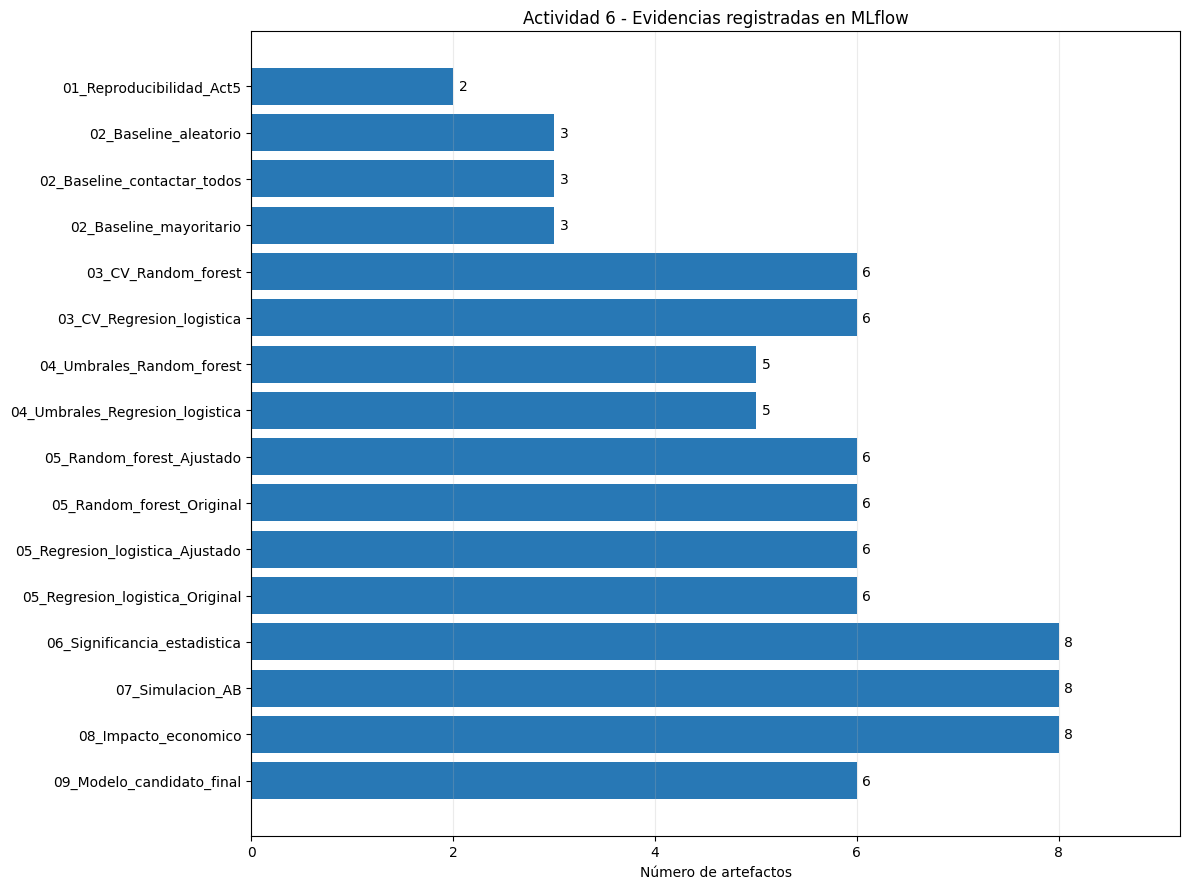

[OK] Visualización generada


In [89]:
df_conteo_runs = (
    df_artefactos_mlflow.groupby(
        "nombre_run"
    ).size().sort_index()
)

fig, ax = plt.subplots(
    figsize=(12, 9)
)

barras = ax.barh(
    df_conteo_runs.index,
    df_conteo_runs.values,
    color="#2878B5"
)

ax.bar_label(
    barras,
    padding=4
)

ax.invert_yaxis()

ax.set_title(
    "Actividad 6 - Evidencias registradas en MLflow"
)

ax.set_xlabel(
    "Número de artefactos"
)

ax.grid(axis="x", alpha=0.25)

ax.margins(x=0.15)

plt.tight_layout()

plt.savefig(
    G / "24_inventario_mlflow.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("[OK] Visualización generada")

In [90]:
fecha = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

ruta_respaldo = Path(
    f"/content/Actividad6_Avance_Etapa10_{fecha}.zip"
)

carpetas_respaldo = [
    "resultados",
    "graficas",
    "documentacion",
    "evidencias_mlflow",
    "modelos"
]

with zipfile.ZipFile(
    ruta_respaldo,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for carpeta in carpetas_respaldo:

        for archivo in (
            ruta_base / carpeta
        ).rglob("*"):

            if archivo.is_file():

                z.write(
                    archivo,
                    archivo.relative_to(ruta_base)
                )

print("Respaldo generado:", ruta_respaldo.name)

print(
    "Tamaño:",
    round(
        ruta_respaldo.stat().st_size /
        (1024 * 1024),
        2
    ),
    "MB"
)

files.download(str(ruta_respaldo))

Respaldo generado: Actividad6_Avance_Etapa10_20261128_084219.zip
Tamaño: 35.48 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Construcción del tablero visual de resultados

En esta etapa se integrarán las evidencias generadas durante el proceso de evaluación y validación de los modelos de aprendizaje automático.

Se desarrollará un tablero visual interactivo mediante Plotly, incorporando las métricas principales, comparación de modelos, matrices de confusión, ajuste de umbrales, validación cruzada, significancia estadística, simulaciones A/B, impacto económico y trazabilidad mediante MLflow.

Adicionalmente, se generará una versión estática en PDF que permita consultar los resultados sin necesidad de ejecutar el notebook.

De acuerdo con las indicaciones proporcionadas por el profesor durante la clase 7, las evidencias visuales se organizarán en el repositorio de GitHub como alternativa al tablero de Trello.

El tablero utilizará exclusivamente los resultados obtenidos durante los experimentos anteriores.

In [91]:
import plotly
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots
from IPython.display import display

ruta_dashboard = ruta_base / "dashboard"

ruta_dashboard.mkdir(
    parents=True,
    exist_ok=True
)

archivos_graficas = sorted(
    (ruta_base / "graficas").glob("*.png")
)

archivos_resultados = sorted(
    (ruta_base / "resultados").glob("*.csv")
)

archivos_documentacion = sorted(
    (ruta_base / "documentacion").glob("*.json")
)

print("=" * 70)
print("INVENTARIO PARA EL DASHBOARD")
print("=" * 70)

print("Plotly:", plotly.__version__)
print("Gráficas disponibles:", len(archivos_graficas))
print("Archivos CSV:", len(archivos_resultados))
print("Archivos JSON:", len(archivos_documentacion))

assert len(archivos_graficas) == 24
assert len(df_final) == 4
assert len(df_runs_mlflow) == 16
assert len(df_artefactos_mlflow) == 87

print("\nGRÁFICAS DISPONIBLES")

for archivo in archivos_graficas:
    print("[OK]", archivo.name)

print("\n[OK] Evidencias disponibles")

INVENTARIO PARA EL DASHBOARD
Plotly: 5.24.1
Gráficas disponibles: 24
Archivos CSV: 34
Archivos JSON: 5

GRÁFICAS DISPONIBLES
[OK] 01_comparacion_metricas.png
[OK] 02_indicadores_comerciales.png
[OK] 03_f1_objetivo_smart.png
[OK] 04_f1_validacion_cruzada.png
[OK] 05_entrenamiento_vs_validacion.png
[OK] 06_estabilidad_modelos.png
[OK] 07_umbrales_Random_forest.png
[OK] 08_umbrales_Regresion_logistica.png
[OK] 09_comparacion_f1_umbrales.png
[OK] 10_matrices_confusion_finales.png
[OK] 11_curvas_roc_finales.png
[OK] 12_curvas_precision_recall.png
[OK] 13_comparacion_final_metricas.png
[OK] 14_cumplimiento_smart.png
[OK] 15_intervalos_confianza_f1.png
[OK] 16_smart_intervalos_confianza.png
[OK] 17_diferencias_estadisticas_f1.png
[OK] 18_resultados_ab.png
[OK] 19_distribucion_simulaciones_ab.png
[OK] 20_diferencias_conversion_ab.png
[OK] 21_sensibilidad_economica.png
[OK] 22_comparacion_economica_modelos.png
[OK] 23_impacto_economico_ab.png
[OK] 24_inventario_mlflow.png

[OK] Evidencias dispo

In [92]:
COLORES = {
    "azul_oscuro": "#072146",
    "azul": "#1464A5",
    "azul_claro": "#49A5E6",
    "verde": "#27864B",
    "naranja": "#D48B30",
    "rojo": "#C34D4D",
    "gris": "#9299A3",
    "fondo": "#F4F7FA"
}

def estilo_dashboard(fig, titulo, altura=450):

    fig.update_layout(
        title={
            "text": titulo,
            "x": 0.02
        },

        template="plotly_white",

        font={
            "family": "Arial",
            "size": 13,
            "color": COLORES["azul_oscuro"]
        },

        height=altura,

        paper_bgcolor="white",
        plot_bgcolor="white",

        margin={
            "l": 65,
            "r": 35,
            "t": 75,
            "b": 65
        },

        legend={
            "orientation": "h",
            "y": -0.20
        }
    )

    return fig


graficas_interactivas = {}

print("[OK] Diseño visual configurado")

[OK] Diseño visual configurado


In [93]:
fig_kpi = make_subplots(
    rows=1,
    cols=4,

    specs=[[
        {"type": "indicator"},
        {"type": "indicator"},
        {"type": "indicator"},
        {"type": "indicator"}
    ]]
)

indicadores = [
    (
        "F1-score",
        candidato_prueba["f1"],
        OBJETIVOS["f1_minimo"]
    ),

    (
        "Recall",
        candidato_prueba["recall"],
        OBJETIVOS["recall_minimo"]
    ),

    (
        "Precision",
        candidato_prueba["precision"],
        OBJETIVOS["precision_minima"]
    ),

    (
        "ROC-AUC",
        candidato_prueba["roc_auc"],
        None
    )
]

for i, (nombre, valor, objetivo) in enumerate(
    indicadores,
    start=1
):

    configuracion = {
        "mode": (
            "number+delta"
            if objetivo is not None
            else "number"
        ),

        "value": valor * 100,

        "number": {
            "suffix": "%",
            "valueformat": ".2f",
            "font": {
                "size": 32,
                "color": COLORES["azul_oscuro"]
            }
        },

        "title": {
            "text": nombre
        }
    }

    if objetivo is not None:

        configuracion["delta"] = {
            "reference": objetivo * 100,
            "relative": False,
            "valueformat": ".2f",
            "suffix": " pp"
        }

    fig_kpi.add_trace(
        go.Indicator(**configuracion),
        row=1,
        col=i
    )

fig_kpi = estilo_dashboard(
    fig_kpi,
    "Random Forest ajustado | Umbral 0.14",
    altura=260
)

graficas_interactivas["indicadores"] = fig_kpi

fig_kpi.show()

In [94]:
df_dash_metricas = df_comparacion_final.copy()

df_dash_metricas["nombre"] = (
    df_dash_metricas["modelo"]
    .map(etiquetas)
    .fillna(df_dash_metricas["modelo"])
)

df_dash_largo = df_dash_metricas.melt(
    id_vars=["nombre"],

    value_vars=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],

    var_name="metrica",
    value_name="valor"
)

df_dash_largo["valor"] *= 100

fig_comparacion = px.bar(
    df_dash_largo,

    x="nombre",
    y="valor",
    color="metrica",

    barmode="group",

    labels={
        "nombre": "Estrategia",
        "valor": "Resultado (%)",
        "metrica": "Métrica"
    },

    color_discrete_sequence=[
        "#1464A5",
        "#49A5E6",
        "#27864B",
        "#D48B30",
        "#072146"
    ]
)

fig_comparacion.update_yaxes(
    range=[0, 105]
)

fig_comparacion = estilo_dashboard(
    fig_comparacion,
    "Comparación de modelos y baselines",
    altura=520
)

graficas_interactivas[
    "comparacion"
] = fig_comparacion

fig_comparacion.show()

In [95]:
fig_umbrales = go.Figure()

for nombre, grupo in df_umbrales.groupby(
    "modelo"
):

    grupo = grupo.sort_values("umbral")

    nombre_visible = nombres_cortos.get(
        nombre, nombre
    )

    color = (
        COLORES["verde"]
        if nombre == modelo_candidato
        else COLORES["azul"]
    )

    fig_umbrales.add_trace(
        go.Scatter(
            x=grupo["umbral"],
            y=grupo["f1"] * 100,

            mode="lines",

            name=nombre_visible,

            line={
                "color": color,
                "width": 3
            },

            customdata=grupo[
                ["precision", "recall"]
            ].to_numpy(),

            hovertemplate=(
                "Umbral: %{x:.2f}<br>"
                "F1: %{y:.2f}%<br>"
                "Precision: %{customdata[0]:.2%}<br>"
                "Recall: %{customdata[1]:.2%}"
                "<extra></extra>"
            )
        )
    )

    seleccionado = umbrales_seleccionados[
        nombre
    ]

    fig_umbrales.add_trace(
        go.Scatter(
            x=[seleccionado["umbral"]],

            y=[
                seleccionado["f1_oof"] * 100
            ],

            mode="markers",

            marker={
                "size": 13,
                "color": color,
                "symbol": "diamond"
            },

            name=(
                f"Seleccionado: "
                f"{seleccionado['umbral']:.2f}"
            )
        )
    )

fig_umbrales.add_hline(
    y=OBJETIVOS["f1_minimo"] * 100,
    line_dash="dash",
    line_color=COLORES["rojo"],
    annotation_text="Objetivo F1"
)

fig_umbrales.add_vline(
    x=0.50,
    line_dash="dot",
    annotation_text="Umbral original"
)

fig_umbrales.update_xaxes(
    title="Umbral de decisión"
)

fig_umbrales.update_yaxes(
    title="F1-score (%)"
)

fig_umbrales = estilo_dashboard(
    fig_umbrales,
    "Optimización de umbrales mediante OOF"
)

graficas_interactivas[
    "umbrales"
] = fig_umbrales

fig_umbrales.show()

In [96]:
df_dash_cv = df_cv_nueva.copy()

df_dash_cv["nombre"] = (
    df_dash_cv["modelo"]
    .map(nombres_cortos)
)

df_dash_cv["f1_pct"] = (
    df_dash_cv["f1"] * 100
)

fig_cv = px.line(
    df_dash_cv.sort_values("fold"),

    x="fold",
    y="f1_pct",
    color="nombre",

    markers=True,

    labels={
        "fold": "Fold",
        "f1_pct": "F1-score (%)",
        "nombre": "Modelo"
    }
)

fig_cv.add_hline(
    y=40,
    line_dash="dash",
    line_color=COLORES["rojo"],
    annotation_text="Objetivo SMART"
)

fig_cv.update_xaxes(
    dtick=1
)

fig_cv.update_yaxes(
    range=[20, 45]
)

fig_cv = estilo_dashboard(
    fig_cv,
    "Estabilidad de los modelos originales"
)

graficas_interactivas[
    "validacion"
] = fig_cv

fig_cv.show()

In [97]:
fig_ic = make_subplots(
    rows=1,
    cols=3,

    subplot_titles=[
        fila["metrica"].upper()
        for _, fila in df_smart_ic.iterrows()
    ]
)

for i, (_, fila) in enumerate(
    df_smart_ic.iterrows(),
    start=1
):

    valor = fila["estimacion"] * 100

    inferior = fila["ic_inferior"] * 100

    superior = fila["ic_superior"] * 100

    objetivo = fila["objetivo"] * 100

    color = (
        COLORES["verde"]
        if fila["limite_inferior_cumple"]
        else COLORES["naranja"]
    )

    fig_ic.add_trace(
        go.Scatter(
            x=[0],
            y=[valor],

            mode="markers",

            marker={
                "size": 13,
                "color": color
            },

            error_y={
                "type": "data",
                "symmetric": False,

                "array": [
                    superior - valor
                ],

                "arrayminus": [
                    valor - inferior
                ],

                "thickness": 3
            },

            showlegend=False,

            hovertemplate=(
                f"Resultado: {valor:.2f}%<br>"
                f"IC 95%: {inferior:.2f}%"
                f" - {superior:.2f}%"
                "<extra></extra>"
            )
        ),

        row=1,
        col=i
    )

    fig_ic.add_hline(
        y=objetivo,
        line_dash="dash",
        line_color=COLORES["rojo"],

        annotation_text=(
            f"Objetivo {objetivo:.0f}%"
        ),

        row=1,
        col=i
    )

    fig_ic.update_xaxes(
        visible=False,
        row=1,
        col=i
    )

    fig_ic.update_yaxes(
        range=[
            min(inferior, objetivo) - 4,
            max(superior, objetivo) + 4
        ],

        ticksuffix="%",

        row=1,
        col=i
    )

fig_ic = estilo_dashboard(
    fig_ic,
    "Cumplimiento SMART e incertidumbre estadística"
)

graficas_interactivas[
    "significancia"
] = fig_ic

fig_ic.show()

In [98]:
fig_ab = go.Figure()

grupos_ab = [
    "A - Selección aleatoria",
    "B - Random Forest"
]

fig_ab.add_trace(
    go.Bar(
        x=grupos_ab,

        y=[
            resultado_ab["contrataciones_a"],
            resultado_ab["contrataciones_b"]
        ],

        name="Contrataciones identificadas",

        marker_color=COLORES["verde"],

        text=[
            resultado_ab["contrataciones_a"],
            resultado_ab["contrataciones_b"]
        ],

        textposition="inside"
    )
)

fig_ab.add_trace(
    go.Bar(
        x=grupos_ab,

        y=[
            resultado_ab["no_contrataciones_a"],
            resultado_ab["no_contrataciones_b"]
        ],

        name="Sin contratación",

        marker_color=COLORES["naranja"],

        text=[
            resultado_ab["no_contrataciones_a"],
            resultado_ab["no_contrataciones_b"]
        ],

        textposition="inside"
    )
)

fig_ab.update_layout(
    barmode="stack"
)

fig_ab.update_yaxes(
    title="Registros seleccionados"
)

fig_ab = estilo_dashboard(
    fig_ab,
    "Simulación A/B retrospectiva | 850 contactos por grupo"
)

graficas_interactivas["ab"] = fig_ab

fig_ab.show()

In [99]:
tabla_sensibilidad = df_sensibilidad.pivot(
    index="margen_contratacion",
    columns="costo_contacto",
    values="ventaja_rf"
)

fig_economia = go.Figure(
    data=go.Heatmap(

        z=tabla_sensibilidad.to_numpy(),

        x=tabla_sensibilidad.columns,

        y=tabla_sensibilidad.index,

        colorscale="RdYlGn",

        zmid=0,

        texttemplate="%{z:,.0f}",

        colorbar={
            "title": "MXN"
        },

        hovertemplate=(
            "Costo por contacto: $%{x}<br>"
            "Margen: $%{y}<br>"
            "Ventaja RF: $%{z:,.0f}"
            "<extra></extra>"
        )
    )
)

fig_economia.update_xaxes(
    title="Costo por contacto (MXN)",
    type="category"
)

fig_economia.update_yaxes(
    title="Margen por contratación (MXN)",
    type="category"
)

fig_economia = estilo_dashboard(
    fig_economia,
    "Sensibilidad económica | RF ajustado vs RL original",
    altura=520
)

graficas_interactivas[
    "economia"
] = fig_economia

fig_economia.show()

In [100]:
import base64
import html

def imagen_embebida(nombre, descripcion):

    archivo = ruta_base / "graficas" / nombre

    assert archivo.is_file(), nombre

    imagen = base64.b64encode(
        archivo.read_bytes()
    ).decode("utf-8")

    return f"""
    <figure>
        <img
            src="data:image/png;base64,{imagen}"
            alt="{html.escape(descripcion)}"
        >
        <figcaption>
            {html.escape(descripcion)}
        </figcaption>
    </figure>
    """


def grafica_html(clave, incluir_plotly=False):

    return graficas_interactivas[
        clave
    ].to_html(
        full_html=False,
        include_plotlyjs=incluir_plotly,
        config={
            "responsive": True,
            "displaylogo": False
        }
    )


estilos_css = """
body {
    margin: 0;
    background: #F4F7FA;
    color: #072146;
    font-family: Arial, sans-serif;
    line-height: 1.6;
}

header {
    background: #072146;
    color: white;
    padding: 36px;
}

header h1 {
    margin: 0;
    font-size: 32px;
}

header p {
    margin: 8px 0;
}

main {
    max-width: 1250px;
    margin: auto;
    padding: 24px;
}

section {
    background: white;
    border: 1px solid #DDE5ED;
    border-radius: 10px;
    padding: 24px;
    margin-bottom: 24px;
}

h2 {
    border-bottom: 2px solid #1464A5;
    padding-bottom: 10px;
}

.grid {
    display: grid;
    grid-template-columns:
        repeat(auto-fit, minmax(320px, 1fr));
    gap: 20px;
}

figure {
    margin: 10px 0;
}

figure img {
    width: 100%;
    height: auto;
}

figcaption {
    font-size: 13px;
    color: #52677C;
}

.kpis {
    display: grid;
    grid-template-columns:
        repeat(auto-fit, minmax(180px, 1fr));
    gap: 16px;
}

.kpi {
    padding: 20px;
    border: 1px solid #DDE5ED;
    border-radius: 8px;
}

.kpi strong {
    display: block;
    font-size: 30px;
    color: #1464A5;
}

.nota {
    background: #F4F7FA;
    border-left: 4px solid #D48B30;
    padding: 16px;
    margin-top: 20px;
}

footer {
    text-align: center;
    padding: 24px;
    color: #52677C;
}
"""

limitaciones_html = "".join(
    f"<li>{html.escape(x)}</li>"
    for x in recomendacion["limitaciones"]
)

dashboard_html = f"""
<!DOCTYPE html>
<html lang="es">
<head>
    <meta charset="UTF-8">
    <meta name="viewport"
          content="width=device-width, initial-scale=1">

    <title>Actividad 6 - Evaluación y validación</title>

    <style>{estilos_css}</style>
</head>

<body>

<header>
    <p>TECMILENIO | ACTIVIDAD 6</p>

    <h1>Evaluación y validación de modelos</h1>

    <p>
        Predicción de contratación
        de depósitos a plazo
    </p>

    <p>Rogelio Aco González</p>
</header>

<main>

<section>
    <h2>01. Resumen ejecutivo</h2>

    <h3>
        Modelo seleccionado: Random Forest
        | Umbral {umbral_candidato:.2f}
    </h3>

    {grafica_html("indicadores", True)}

    <p>
        Se seleccionó Random Forest ajustado
        por su desempeño predictivo y cumplimiento
        puntual de los objetivos SMART.
    </p>

    <div class="nota">
        Candidato para validación adicional
        y eventual piloto controlado.
        No aprobado para producción.
    </div>
</section>

<section>
    <h2>02. Evaluación técnica</h2>

    {grafica_html("comparacion")}

    {imagen_embebida(
        "10_matrices_confusion_finales.png",
        "Matrices de confusión de los cuatro escenarios"
    )}

    <div class="grid">

        {imagen_embebida(
            "11_curvas_roc_finales.png",
            "Curvas ROC y puntos de operación"
        )}

        {imagen_embebida(
            "12_curvas_precision_recall.png",
            "Curvas Precision-Recall"
        )}

    </div>
</section>

<section>
    <h2>03. Optimización y validación</h2>

    {grafica_html("umbrales")}

    {grafica_html("validacion")}

    <div class="grid">

        {imagen_embebida(
            "05_entrenamiento_vs_validacion.png",
            "Análisis de generalización y sobreajuste"
        )}

        {imagen_embebida(
            "06_estabilidad_modelos.png",
            "Estabilidad de los modelos originales"
        )}

    </div>
</section>

<section>
    <h2>04. Significancia estadística</h2>

    {grafica_html("significancia")}

    {imagen_embebida(
        "17_diferencias_estadisticas_f1.png",
        "Comparaciones mediante Bootstrap pareado"
    )}

    <div class="nota">
        El intervalo de confianza del recall
        incluye valores inferiores al objetivo.
        Se requiere validación adicional.
    </div>
</section>

<section>
    <h2>05. Impacto comercial y económico</h2>

    <div class="kpis">

        <div class="kpi">
            <strong>
                {100 * contactos_evitados / eco_rl["contactos"]:.2f}%
            </strong>
            Reducción potencial de contactos
        </div>

        <div class="kpi">
            <strong>
                {resultado_ab["lift"]:.2f}x
            </strong>
            Lift de la simulación principal
        </div>

        <div class="kpi">
            <strong>
                ${ventaja_economica_rf:,.0f}
            </strong>
            Ventaja económica simulada frente a RL
        </div>

        <div class="kpi">
            <strong>
                ${ventaja_ab:,.0f}
            </strong>
            Ventaja económica simulada A/B
        </div>

    </div>

    {grafica_html("ab")}

    {imagen_embebida(
        "19_distribucion_simulaciones_ab.png",
        "Estabilidad de las 1,000 simulaciones A/B"
    )}

    {grafica_html("economia")}

    {imagen_embebida(
        "22_comparacion_economica_modelos.png",
        "Comparación económica de estrategias"
    )}

    <div class="nota">
        Los resultados comerciales son retrospectivos.
        Los importes económicos son hipotéticos
        y se expresan en MXN.
        No representan beneficios reales.
    </div>
</section>

<section>
    <h2>06. Trazabilidad y decisión final</h2>

    <div class="kpis">

        <div class="kpi">
            <strong>{len(df_runs_mlflow)}</strong>
            Experimentos registrados
        </div>

        <div class="kpi">
            <strong>{len(df_artefactos_mlflow)}</strong>
            Artefactos registrados
        </div>

        <div class="kpi">
            <strong>SHA-256</strong>
            Integridad verificada
        </div>

    </div>

    {imagen_embebida(
        "24_inventario_mlflow.png",
        "Evidencias registradas mediante MLflow"
    )}

    <h3>Recomendación técnica</h3>

    <p>
        Random Forest con umbral 0.14
        constituye el candidato más conveniente
        bajo los criterios SMART establecidos.
    </p>

    <h3>Limitaciones identificadas</h3>

    <ul>
        {limitaciones_html}
    </ul>

    <div class="nota">
        Se recomienda una validación externa
        y una prueba piloto controlada
        antes de considerar el despliegue.
    </div>
</section>

</main>

<footer>
    Proyecto académico | UCI Bank Marketing
    | Actividad 6
</footer>

</body>
</html>
"""

ruta_html = (
    ruta_dashboard / "dashboard_actividad6.html"
)

ruta_html.write_text(
    dashboard_html,
    encoding="utf-8"
)

print("=" * 70)
print("DASHBOARD GENERADO")
print("=" * 70)

print("Archivo:", ruta_html)

print(
    "Tamaño:",
    round(
        ruta_html.stat().st_size /
        (1024 * 1024),
        2
    ),
    "MB"
)

print("\n[OK] Dashboard HTML generado")

DASHBOARD GENERADO
Archivo: /content/Actividad6/dashboard/dashboard_actividad6.html
Tamaño: 5.72 MB

[OK] Dashboard HTML generado


In [101]:
from IPython.display import FileLink

display(
    FileLink(str(ruta_html))
)

files.download(
    str(ruta_html)
)

/content/Actividad6/dashboard/dashboard_actividad6.html

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [102]:
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.image as mpimg

ruta_pdf_dashboard = (
    ruta_dashboard / "dashboard_actividad6.pdf"
)

paginas_dashboard = [

    (
        "02. Evaluación técnica",
        [
            "13_comparacion_final_metricas.png",
            "10_matrices_confusion_finales.png"
        ]
    ),

    (
        "03. Curvas de evaluación",
        [
            "11_curvas_roc_finales.png",
            "12_curvas_precision_recall.png"
        ]
    ),

    (
        "04. Optimización y validación",
        [
            "09_comparacion_f1_umbrales.png",
            "05_entrenamiento_vs_validacion.png"
        ]
    ),

    (
        "05. Significancia estadística",
        [
            "16_smart_intervalos_confianza.png",
            "17_diferencias_estadisticas_f1.png"
        ]
    ),

    (
        "06. Simulación A/B",
        [
            "18_resultados_ab.png",
            "19_distribucion_simulaciones_ab.png"
        ]
    ),

    (
        "07. Impacto económico",
        [
            "21_sensibilidad_economica.png",
            "22_comparacion_economica_modelos.png"
        ]
    ),

    (
        "08. Trazabilidad y selección",
        [
            "24_inventario_mlflow.png",
            "14_cumplimiento_smart.png"
        ]
    )
]

with PdfPages(ruta_pdf_dashboard) as pdf:

    # Portada ejecutiva

    fig = plt.figure(
        figsize=(8.27, 11.69),
        facecolor="white"
    )

    fig.text(
        0.08, 0.93,
        "TECMILENIO | ACTIVIDAD 6",
        fontsize=12,
        color="#1464A5",
        weight="bold"
    )

    fig.text(
        0.08, 0.85,
        "Evaluación y validación\n"
        "de modelos de Machine Learning",
        fontsize=23,
        weight="bold",
        color="#072146"
    )

    fig.text(
        0.08, 0.76,
        "Predicción de contratación\n"
        "de depósitos a plazo",
        fontsize=16
    )

    fig.text(
        0.08, 0.67,
        "Modelo seleccionado: Random Forest\n"
        f"Umbral de decisión: {umbral_candidato:.2f}",
        fontsize=16,
        color="#1464A5",
        weight="bold"
    )

    kpis_pdf = [
        (
            "F1-score",
            candidato_prueba["f1"]
        ),

        (
            "Precision",
            candidato_prueba["precision"]
        ),

        (
            "Recall",
            candidato_prueba["recall"]
        ),

        (
            "ROC-AUC",
            candidato_prueba["roc_auc"]
        )
    ]

    for i, (nombre, valor) in enumerate(
        kpis_pdf
    ):

        x = 0.08 + (i % 2) * 0.46

        y = 0.55 - (i // 2) * 0.13

        fig.text(
            x, y,
            nombre,
            fontsize=13
        )

        fig.text(
            x, y - 0.045,
            f"{valor:.2%}",
            fontsize=27,
            color="#1464A5",
            weight="bold"
        )

    fig.text(
        0.08, 0.25,

        "Recomendación:\n"
        "Candidato para validación adicional\n"
        "y eventual piloto controlado.",

        fontsize=14,
        color="#072146"
    )

    fig.text(
        0.08, 0.14,

        "No aprobado para producción.\n"
        "Resultados comerciales retrospectivos.\n"
        "Supuestos económicos hipotéticos.",

        fontsize=11,
        color="#52677C"
    )

    fig.text(
        0.08, 0.06,
        "Rogelio Aco González | Tablero visual",
        fontsize=10
    )

    pdf.savefig(fig)

    plt.close(fig)

    # Páginas de resultados

    for numero, (titulo, imagenes) in enumerate(
        paginas_dashboard,
        start=2
    ):

        fig, axes = plt.subplots(
            2, 1,
            figsize=(8.27, 11.69)
        )

        fig.suptitle(
            titulo,
            fontsize=18,
            color="#072146",
            weight="bold",
            y=0.96
        )

        for ax, nombre in zip(
            axes,
            imagenes
        ):

            archivo = (
                ruta_base / "graficas" / nombre
            )

            assert archivo.is_file(), nombre

            imagen = mpimg.imread(archivo)

            ax.imshow(imagen)

            ax.axis("off")

        fig.text(
            0.08, 0.025,

            "Actividad 6 | Evidencias experimentales",

            fontsize=9,
            color="#52677C"
        )

        fig.text(
            0.92, 0.025,
            str(numero),
            fontsize=9,
            ha="right"
        )

        fig.tight_layout(
            rect=[0.03, 0.05, 0.97, 0.93]
        )

        pdf.savefig(fig)

        plt.close(fig)

print("=" * 70)
print("TABLERO VISUAL EN PDF")
print("=" * 70)

print("Archivo:", ruta_pdf_dashboard)

print(
    "Páginas generadas:",
    1 + len(paginas_dashboard)
)

print(
    "Tamaño:",
    round(
        ruta_pdf_dashboard.stat().st_size /
        (1024 * 1024),
        2
    ),
    "MB"
)

files.download(
    str(ruta_pdf_dashboard)
)

TABLERO VISUAL EN PDF
Archivo: /content/Actividad6/dashboard/dashboard_actividad6.pdf
Páginas generadas: 8
Tamaño: 0.56 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [103]:
markdown_dashboard = f"""# Tablero visual de resultados

## Actividad 6 - Evaluación y validación

Predicción de contratación de depósitos a plazo.

**Alumno:** Rogelio Aco González

## 1. Modelo seleccionado

Random Forest con umbral de decisión de
{umbral_candidato:.2f}.

| Métrica | Resultado |
|---|---:|
| Accuracy | {candidato_prueba["accuracy"]:.2%} |
| Precision | {candidato_prueba["precision"]:.2%} |
| Recall | {candidato_prueba["recall"]:.2%} |
| F1-score | {candidato_prueba["f1"]:.2%} |
| ROC-AUC | {candidato_prueba["roc_auc"]:.2%} |

## 2. Evaluación técnica

![Comparación](../graficas/13_comparacion_final_metricas.png)

![Matrices](../graficas/10_matrices_confusion_finales.png)

![ROC](../graficas/11_curvas_roc_finales.png)

![Precision Recall](../graficas/12_curvas_precision_recall.png)

## 3. Optimización y validación

![Umbrales](../graficas/09_comparacion_f1_umbrales.png)

![Validación cruzada](../graficas/04_f1_validacion_cruzada.png)

![Generalización](../graficas/05_entrenamiento_vs_validacion.png)

## 4. Significancia estadística

![Intervalos](../graficas/16_smart_intervalos_confianza.png)

![Diferencias F1](../graficas/17_diferencias_estadisticas_f1.png)

El intervalo de confianza del recall incluye
valores inferiores al objetivo establecido.

## 5. Simulación A/B

![Resultados AB](../graficas/18_resultados_ab.png)

![Simulaciones](../graficas/19_distribucion_simulaciones_ab.png)

La simulación es retrospectiva y no demuestra
un efecto causal sobre las ventas.

## 6. Impacto económico

![Sensibilidad](../graficas/21_sensibilidad_economica.png)

![Comparación económica](../graficas/22_comparacion_economica_modelos.png)

Los valores económicos son hipotéticos.

## 7. Trazabilidad

- Experimentos MLflow: {len(df_runs_mlflow)}
- Artefactos registrados: {len(df_artefactos_mlflow)}
- Integridad SHA-256 verificada.
- Predicciones reproducidas.

![MLflow](../graficas/24_inventario_mlflow.png)

## 8. Recomendación final

Random Forest ajustado constituye el candidato
más conveniente bajo los criterios SMART
establecidos.

Se recomienda una validación adicional
y eventual piloto controlado.

**No aprobado para producción.**

## Archivos complementarios

- [Dashboard interactivo HTML](dashboard_actividad6.html)
- [Tablero visual PDF](dashboard_actividad6.pdf)

Para consultar el dashboard interactivo,
descargar el archivo HTML y abrirlo
en un navegador.
"""

ruta_md_dashboard = (
    ruta_dashboard / "README.md"
)

ruta_md_dashboard.write_text(
    markdown_dashboard,
    encoding="utf-8"
)

print("[OK] Tablero Markdown generado")

print(ruta_md_dashboard)

[OK] Tablero Markdown generado
/content/Actividad6/dashboard/README.md


In [104]:
import re

archivos_dashboard = [
    ruta_html,
    ruta_pdf_dashboard,
    ruta_md_dashboard
]

print("=" * 70)
print("VERIFICACIÓN DEL TABLERO VISUAL")
print("=" * 70)

for archivo in archivos_dashboard:

    assert archivo.is_file()

    assert archivo.stat().st_size > 0

    print(
        "[OK]",
        archivo.name,
        "|",
        round(
            archivo.stat().st_size / 1024,
            2
        ),
        "KB"
    )

# Verificar las referencias a imágenes
# del documento Markdown

referencias = re.findall(
    r"!\[[^\]]*\]\(([^)]+)\)",
    markdown_dashboard
)

for referencia in referencias:

    archivo = (
        ruta_dashboard / referencia
    ).resolve()

    assert archivo.is_file(), referencia

print(
    "\nReferencias visuales verificadas:",
    len(referencias)
)

print(
    "Componentes interactivos:",
    len(graficas_interactivas)
)

print("\n[OK] Tablero visual completo")

VERIFICACIÓN DEL TABLERO VISUAL
[OK] dashboard_actividad6.html | 5852.2 KB
[OK] dashboard_actividad6.pdf | 570.07 KB
[OK] README.md | 2.16 KB

Referencias visuales verificadas: 14
Componentes interactivos: 7

[OK] Tablero visual completo


In [105]:
fecha = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

ruta_respaldo = Path(
    f"/content/Actividad6_Avance_Etapa11_{fecha}.zip"
)

carpetas_respaldo = [
    "dashboard",
    "graficas",
    "resultados",
    "documentacion"
]

with zipfile.ZipFile(
    ruta_respaldo,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for carpeta in carpetas_respaldo:

        for archivo in (
            ruta_base / carpeta
        ).rglob("*"):

            if archivo.is_file():

                z.write(
                    archivo,
                    archivo.relative_to(ruta_base)
                )

print("Respaldo generado:", ruta_respaldo.name)

print(
    "Tamaño:",
    round(
        ruta_respaldo.stat().st_size /
        (1024 * 1024),
        2
    ),
    "MB"
)

files.download(
    str(ruta_respaldo)
)

Respaldo generado: Actividad6_Avance_Etapa11_20261128_085718.zip
Tamaño: 6.51 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>